# FPA Project — Statistical Models: ARIMA, SARIMA, SARIMAX

**Data:** `Data/depts_1_to_3_stat.csv` (teammate's `depts_1_to_3.csv` + calendar columns, built in `FPA_Project_EDA_full.ipynb`) and `Data/week_calendar.csv`.
**Methodology (teammate's):** departments 1–3, Store 1 studied first; train part = first 104 weeks, holdout = last 39 weeks (`split == "test"`); one forecast origin (2012-01-27) → 39 weeks ahead; metric **WMAE** (holiday weeks × 5).

### How to read this notebook

All outputs are saved in the notebook, so it can be read without running. It has five parts:

| Part | Content |
|---|---|
| **1. Theory** | What ARIMA, SARIMA and SARIMAX are: plain-English intuition first, then the equations, plus a small **simulation lab** that shows what each model "looks like" |
| **2. Store 1, step by step** | The full Box–Jenkins cycle (identify → estimate → diagnose → forecast) for every model, on the 3 series of Store 1 |
| **3. All 135 series** | The same models, automated, scored on the holdout |
| **4. Final forecast** | The best approach re-fitted on all 143 weeks to forecast the 39 weeks of `test.csv` |
| **5. Conclusions** | What we learned, limitations, link with the ML / DL parts, cheat sheet |

If a section feels heavy, the **"In plain words"** paragraphs and the **tables** carry the main message; the equations are there to go deeper.

**Amounts** (sales, errors) are weekly **US dollars**. In the text I write them without the dollar sign (e.g. 57.6k = 57,600 dollars): Jupyter reads text between two `$` signs as a maths formula, so two dollar amounts in the same sentence would be displayed as garbled maths.

## The model ladder used in this notebook

Each model adds **one idea** to the previous one. That's also the structure of the comparison at the end.

| # | Model (name used below) | One-line idea | What it can capture |
|---|---|---|---|
| 0 | **naive / mean / seasonal naive** | "nothing changes" / "a normal week" / "same week last year" | baselines |
| 1 | **ARIMA** = ARIMA(p, 0, q) on log sales | short-term memory only | how the last weeks influence the next ones |
| 2 | **SARIMA-D** = SARIMA(p, 0, q)(0, 1, 0)₅₂ | last year's same week + short-term correction | the yearly pattern, by copying last year |
| 3 | **SARIMA-AR** = SARIMA(p, 0, 0)(1, 0, 0)₅₂ on log sales minus their mean | a *shrunk* copy of last year | the yearly pattern, with an estimated strength Φ |
| 4 | **SARIMAX-D** = SARIMA-D + moving-holiday dummies | copy last year, but correct the holidays that moved | Easter, Valentine's, Halloween shifts |
| 5 | **SARIMAX-F** = Fourier terms + holiday dummies + ARMA errors | a smooth yearly curve + explicit holiday bumps | the yearly shape without copying last year's noise |
| 6 | **Combination** = average of SARIMAX-D and SARIMAX-F | two different views averaged (teammate's Note 6) | robustness |

## Setup: libraries and settings (used by every part below)

In [1]:
# --- libraries ---
import os, time, itertools
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from statsmodels.tsa.statespace.sarimax import SARIMAX          # ARIMA, SARIMA and SARIMAX all use this class
from statsmodels.tsa.arima_process import ArmaProcess            # to simulate AR / MA processes (theory lab)
from statsmodels.tsa.stattools import acf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox          # Ljung-Box test on residuals

# hide warnings AFTER importing statsmodels (statsmodels switches its convergence warnings back on when imported)
warnings.filterwarnings("ignore")

# if something is missing:  pip install seaborn statsmodels

# --- settings ---
DATA_DIR = "Data/"
RESULTS_DIR = "results/"            # cached results of the long loops (Part 3 and 4)
os.makedirs(RESULTS_DIR, exist_ok=True)
DEPTS = [1, 2, 3]                   # teammate's departments
FOCUS_STORE = 1                     # teammate's store for the statistical models
H = 39                              # forecast horizon in weeks (= length of the holdout and of test.csv)
PERIOD = 365.25 / 7                 # length of a year in weeks (52.18), used by the Fourier terms
split_date = pd.Timestamp("2012-01-27")       # teammate's split date

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

# Part 1 — Theory

## 1.0 The forecasting problem in one picture

For one series (e.g. *Store 1 – Dept 1*), call $y_t$ the **log** of the weekly sales in week $t$ (why log: EDA notebook, section G.3).

- We know $y_1, \dots, y_T$ with $T = 104$ (train part, Feb 2010 → Jan 2012).
- We want $\hat y_{T+1}, \dots, \hat y_{T+39}$: the 39 holdout weeks, all **from the same origin** $T$ (no update with new data along the way).
- The notation $\hat y_{T+h \mid T}$ means "forecast of week $T+h$ using information up to $T$". $h$ is the **horizon** (1 to 39 weeks ahead).

**In plain words:** standing at the end of January 2012, write down your guess for every week until the end of October 2012, then check how far off you were.

A **time-series model** is a recipe that says how $y_t$ is built from **its own past** (and, for SARIMAX, from a few **known calendar variables**) plus a **random surprise**. Once the recipe's numbers (coefficients) are estimated on the train part, the same recipe is rolled forward to produce the forecasts.

## 1.1 The building blocks

### White noise $\varepsilon_t$: pure surprise

A series of independent random shocks with mean 0 and constant variance $\sigma^2$. Knowing past values tells you **nothing** about the next one, so the best forecast is simply the mean.

Every model below has the same goal: **explain everything that is predictable, so that what remains looks like white noise.** If the leftovers (residuals) still have a pattern, the model has missed something. That's the idea behind the residual checks in Part 2.

### The backshift operator $B$: compact notation for "the value k weeks ago"

$$B\,y_t = y_{t-1}, \qquad B^k y_t = y_{t-k}$$

So:
- $(1-B)\,y_t = y_t - y_{t-1}$ = **first difference** ("this week − last week"),
- $(1-B^{52})\,y_t = y_t - y_{t-52}$ = **seasonal difference** ("this week − same week last year").

It looks abstract, but it turns every model into a product of simple polynomials in $B$, which is how the software and the textbooks write them.

### Stationarity (recap from the EDA, section G.4)

A series is **stationary** if its mean, its variance and its correlations between weeks $k$ apart **don't change over time**. ARMA models estimate **one** set of coefficients for the whole history, so they need this. Differencing ($d$, $D$) is the tool that removes non-stationarity (trends, seasonal levels) **before** fitting the ARMA part.

## 1.2 AR(p): memory of past **values**

**In plain words:** this week = a fraction of last week + a new surprise. Think of the temperature of a room after the heating is switched off: today's temperature is mostly yesterday's, and a shock (a door left open) fades away **gradually**.

**AR(1):**
$$y_t = c + \phi\, y_{t-1} + \varepsilon_t, \qquad |\phi| < 1$$

- $\phi$ = how much of last week is carried over (0.8 → 80%).
- The long-run mean is $\mu = c / (1-\phi)$.
- **AR(p)** uses the last $p$ weeks: $y_t = c + \phi_1 y_{t-1} + \dots + \phi_p y_{t-p} + \varepsilon_t$, or with $B$: $\phi(B)\,y_t = c + \varepsilon_t$ with $\phi(B) = 1 - \phi_1 B - \dots - \phi_p B^p$.

**Fingerprint:** the ACF **decays slowly** ($\phi, \phi^2, \phi^3, \dots$) and the PACF **cuts off** after lag $p$.

**Forecast:** $\hat y_{T+h} - \mu = \phi^h\,(y_T - \mu)$. The forecast **slides back to the mean**, faster when $\phi$ is small.

## 1.3 MA(q): memory of past **surprises**

**In plain words:** this week = normal level + this week's surprise + a fraction of last week's surprise. Think of a ripple: a shock is felt for exactly $q$ weeks and then **completely forgotten**.

**MA(1):**
$$y_t = \mu + \varepsilon_t + \theta\, \varepsilon_{t-1}$$

**Fingerprint:** the ACF **cuts off** after lag $q$, and the PACF **decays**. **Forecast:** after $q$ steps the forecast is exactly the mean $\mu$.

## 1.4 ARMA and ARIMA(p, d, q)

- **ARMA(p, q)** combines both: $\phi(B)\, y_t = c + \theta(B)\,\varepsilon_t$. Both ACF and PACF decay. ARMA describes complex memory with few parameters.
- **ARIMA(p, d, q)**: if the series is not stationary, **difference it $d$ times**, fit an ARMA on the result, then add the differences back up (= "**I**ntegrate") to get forecasts of the original series:

$$\phi(B)\,(1-B)^d\, y_t = c + \theta(B)\,\varepsilon_t$$

| Special case | Equation | Forecast |
|---|---|---|
| ARIMA(0,0,0) + constant | $y_t = \mu + \varepsilon_t$ | the mean (= *mean* baseline) |
| ARIMA(0,1,0) (random walk) | $y_t = y_{t-1} + \varepsilon_t$ | the last value, forever (= *naive* baseline) |
| ARIMA(p,0,q) + constant | stationary ARMA | goes back to the mean within a few weeks |

**Key consequence for us:** an ARIMA with $d = 0$ has short memory, so after a few weeks its forecast is **flat at the mean**. It can't produce a Christmas or back-to-school peak 30 weeks ahead. That's why it needs a seasonal part.

### Simulation lab 1: the fingerprints of white noise, random walk, AR(1) and MA(1)

The best way to learn to read ACF / PACF plots is to look at series **where we know the truth**. Below I simulate 300 points of 4 processes and draw each series with its ACF and PACF.

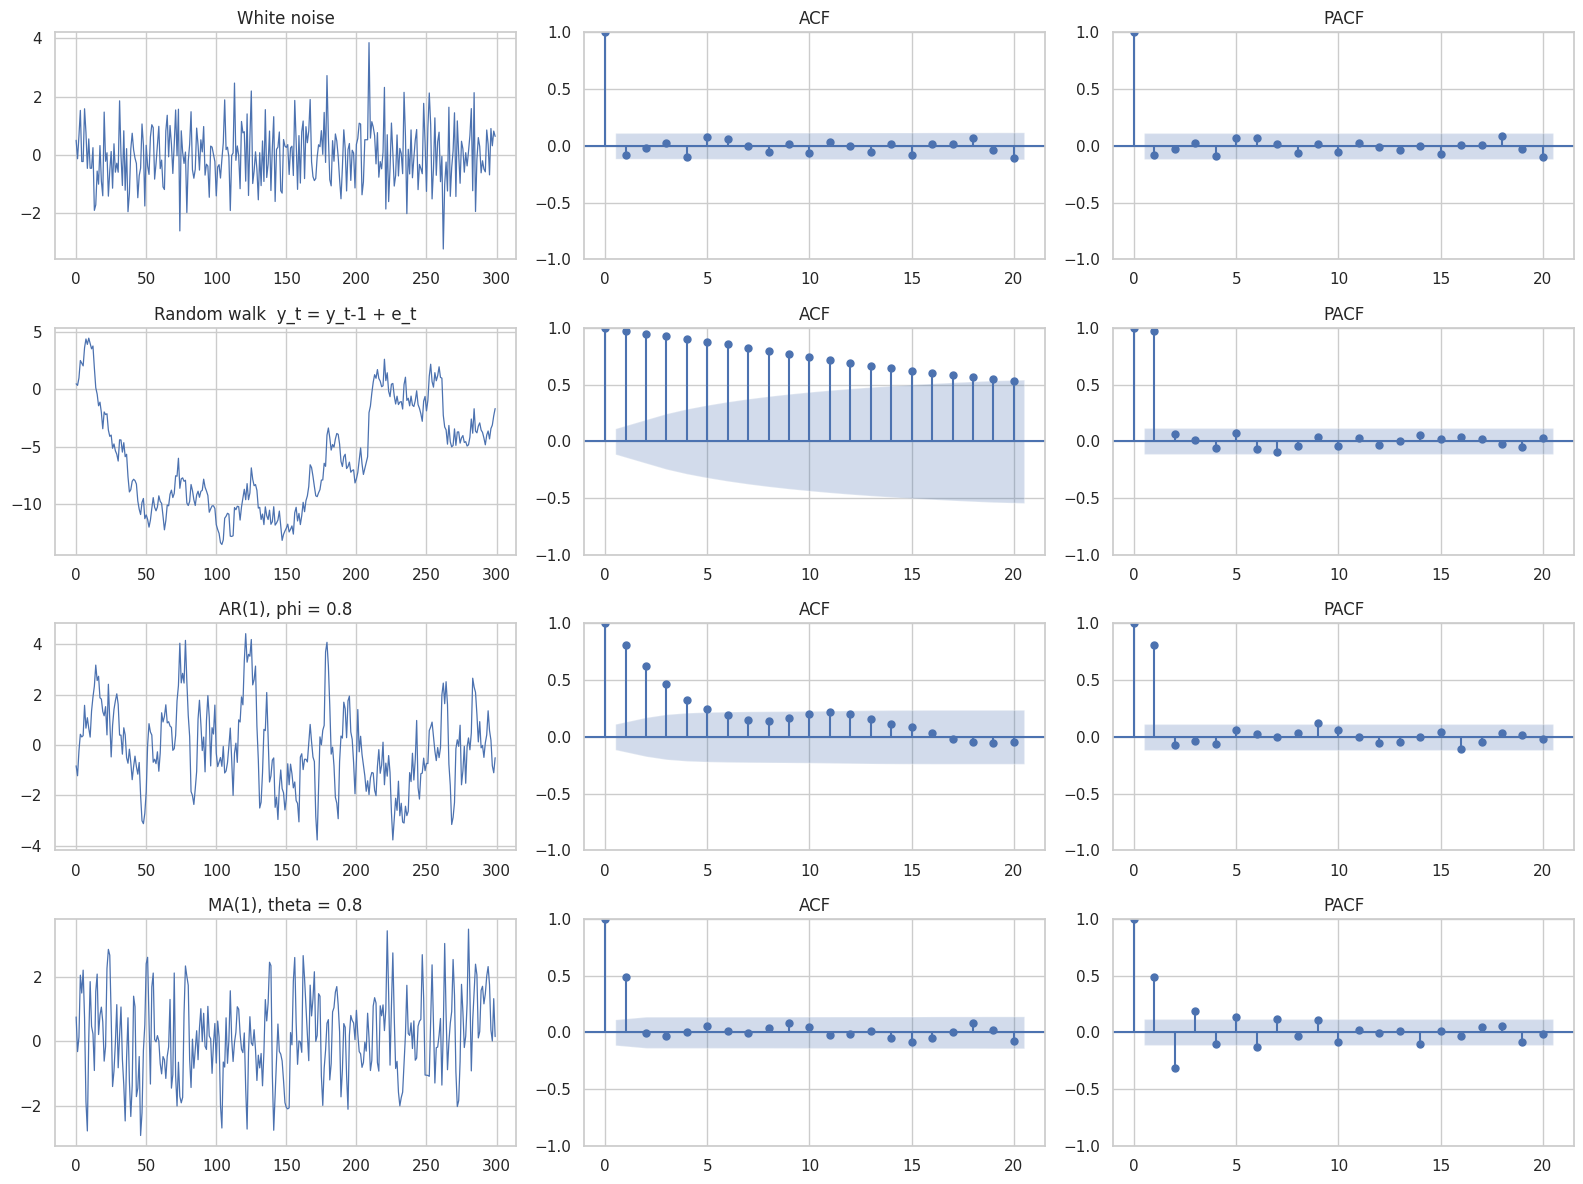

In [2]:
np.random.seed(42)                                   # same random numbers every time the notebook runs
n = 300
eps = np.random.normal(0, 1, n)                      # white noise

simulated = {
    "White noise": eps,
    "Random walk  y_t = y_t-1 + e_t": np.cumsum(eps),
    "AR(1), phi = 0.8": ArmaProcess(ar=[1, -0.8], ma=[1]).generate_sample(n),     # ar=[1, -phi] (statsmodels sign convention)
    "MA(1), theta = 0.8": ArmaProcess(ar=[1], ma=[1, 0.8]).generate_sample(n),   # ma=[1, theta]
}

fig, axes = plt.subplots(4, 3, figsize=(16, 12))
for row, (name, y) in enumerate(simulated.items()):
    axes[row, 0].plot(y, linewidth=0.9)
    axes[row, 0].set_title(name)
    plot_acf(y, lags=20, ax=axes[row, 1], title="ACF")
    plot_pacf(y, lags=20, ax=axes[row, 2], method="ywm", title="PACF")
plt.tight_layout()
plt.show()

**How to read the lab**

| Process | ACF | PACF | Lesson |
|---|---|---|---|
| White noise | nothing outside the band | nothing outside the band | nothing to model: the target state for **residuals** |
| Random walk | very slow decay, stays high | one huge bar at lag 1 | **non-stationary**: needs differencing ($d = 1$) |
| AR(1), φ = 0.8 | geometric decay 0.8, 0.64, 0.51… | **cuts off after lag 1** | AR order = last significant PACF lag |
| MA(1), θ = 0.8 | **cuts off after lag 1** | decays, alternating signs | MA order = last significant ACF lag |

## 1.5 SARIMA(p, d, q)(P, D, Q)ₛ: adding a second clock

**In plain words:** a SARIMA has **two clocks**. The *short* clock remembers the last few weeks (p, d, q, as in ARIMA). The *long* clock remembers **the same week in previous years** (P, D, Q, at lags $s = 52, 104, \dots$).

| Part | Short clock (weeks) | Long clock (years, $s = 52$) |
|---|---|---|
| AR (memory of values) | $p$: $y_{t-1}, y_{t-2}, \dots$ | $P$: $y_{t-52}, y_{t-104}, \dots$ |
| differencing | $d$: $y_t - y_{t-1}$ | $D$: $y_t - y_{t-52}$ |
| MA (memory of surprises) | $q$: $\varepsilon_{t-1}, \dots$ | $Q$: $\varepsilon_{t-52}, \dots$ |

**Full equation (multiplicative form):**
$$\phi(B)\,\Phi(B^{s})\,(1-B)^d\,(1-B^{s})^D\, y_t = c + \theta(B)\,\Theta(B^{s})\,\varepsilon_t$$

"Multiplicative" means the two clocks **multiply**. For example $(1-\phi B)(1-\Phi B^{52}) = 1 - \phi B - \Phi B^{52} + \phi\Phi B^{53}$, so the model automatically includes the interaction term at lag 53.

### Three special cases that matter a lot for this project

**1. Seasonal naive is a SARIMA.** SARIMA(0,0,0)(0,1,0)₅₂ without constant says $(1-B^{52})\,y_t = \varepsilon_t$, i.e. $y_t = y_{t-52} + \varepsilon_t$. Its forecast is $\hat y_{T+h} = y_{T+h-52}$: exactly "same week last year". So the baseline is already a (very simple) statistical model.

**2. SARIMA-D = SARIMA(p, 0, q)(0, 1, 0)₅₂ = seasonal naive + a correction.** Call $w_t = y_t - y_{t-52}$ the **yearly change** (on the log scale ≈ % growth vs last year). The model says $w_t$ follows an ARMA(p, q). Forecast:
$$\hat y_{T+h} = \underbrace{y_{T+h-52}}_{\text{same week last year}} + \underbrace{\hat w_{T+h}}_{\text{forecast of the yearly change}}$$
If the latest weeks ran 5% above last year, the model carries that +5% into the next weeks, and then (because the ARMA is stationary) the correction fades back to 0 (or to a constant yearly growth if there is a constant, the **drift**).

**3. SARIMA-AR = SARIMA(p, 0, 0)(1, 0, 0)₅₂ on the de-meaned series: a shrunk copy of last year.** Without differencing, the seasonal AR term says
$$y_t - \mu \approx \Phi\,(y_{t-52} - \mu) + \dots$$
$\Phi = 1$ → exactly last year (seasonal naive); $\Phi = 0$ → the mean; in between → last year **pulled towards the average**. The data estimate $\Phi$ for us. If $\Phi$ comes out ≈ 1, the data are telling us that seasonal differencing ($D = 1$) is the right description.

### The data budget problem: why we can't use P or Q with D = 1

With 104 weeks and $D = 1$, the yearly change $w_t = y_t - y_{t-52}$ only exists for $t = 53, \dots, 104$: **52 values**.

- A seasonal AR term on $w$ needs $w_{t-52}$, i.e. $t - 52 \ge 53$, i.e. $t \ge 105$. **There are zero such pairs in the data.**
- A seasonal MA term needs $\varepsilon_{t-52}$, which lies before the start of $w$. Same problem.

So with $D = 1$, $P$ and $Q$ are **not identifiable**: the data contain no information about them, and any number the software prints would be meaningless. With $D = 0$, a seasonal AR term needs $y_{t-52}$, and there are 52 pairs: exactly the "pairs correlation" of the EDA (G.1). That's why the two SARIMA versions above are **SARIMA-D (D = 1, P = Q = 0)** and **SARIMA-AR (D = 0, P = 1)**. These are the only seasonal structures 2 years of data can support.

### Simulation lab 2: seasonal fingerprints and forecast shapes

To keep the picture readable I simulate a **monthly-like** season, $s = 12$, over 20 seasons. The logic is the same as for $s = 52$, just with fewer lags to draw.

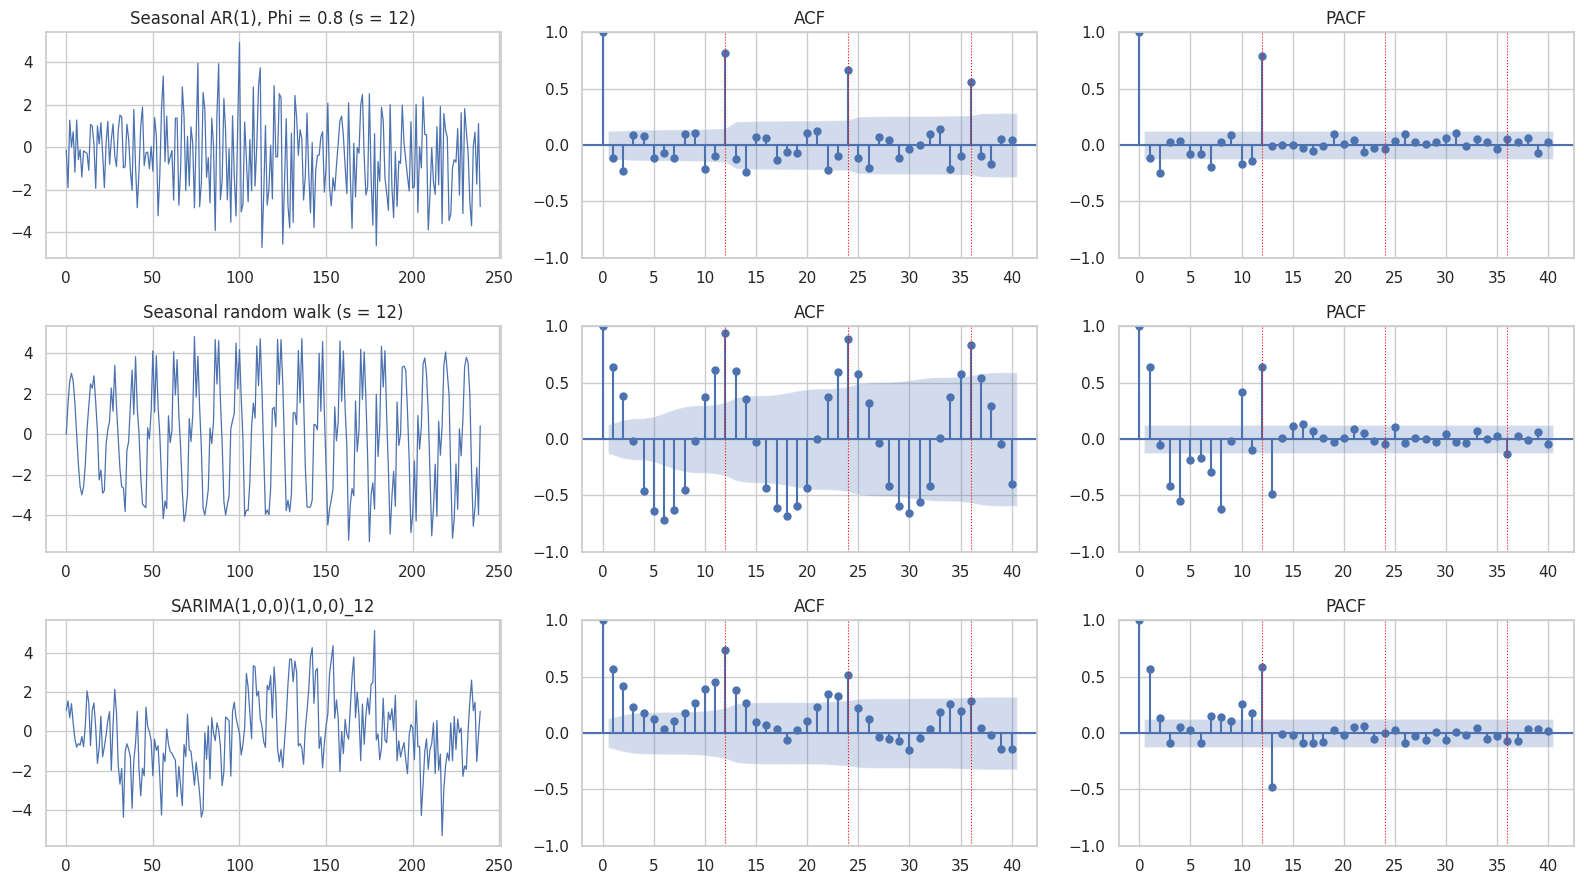

In [3]:
np.random.seed(7)
n, s = 240, 12
eps = np.random.normal(0, 1, n)

# seasonal AR(1): y_t = 0.8 * y_(t-12) + e_t        -> ar polynomial 1 - 0.8 B^12
seasonal_ar = ArmaProcess(ar=[1] + [0] * (s - 1) + [-0.8], ma=[1]).generate_sample(n)

# seasonal random walk: y_t = y_(t-12) + e_t, starting from a fixed yearly pattern
pattern = 3 * np.sin(2 * np.pi * np.arange(s) / s)
seasonal_rw = np.zeros(n)
seasonal_rw[:s] = pattern
for t in range(s, n):
    seasonal_rw[t] = seasonal_rw[t - s] + 0.5 * eps[t]

# SARIMA(1,0,0)(1,0,0)_12: (1 - 0.6B)(1 - 0.8B^12) y_t = e_t  -> multiply the two polynomials
ar_poly = np.polymul([1, -0.6][::-1], ([1] + [0] * (s - 1) + [-0.8])[::-1])[::-1]
sarima_sim = ArmaProcess(ar=ar_poly, ma=[1]).generate_sample(n)

fig, axes = plt.subplots(3, 3, figsize=(16, 9))
for row, (name, y) in enumerate({"Seasonal AR(1), Phi = 0.8 (s = 12)": seasonal_ar,
                                  "Seasonal random walk (s = 12)": seasonal_rw,
                                  "SARIMA(1,0,0)(1,0,0)_12": sarima_sim}.items()):
    axes[row, 0].plot(y, linewidth=0.9)
    axes[row, 0].set_title(name)
    plot_acf(y, lags=40, ax=axes[row, 1], title="ACF")
    plot_pacf(y, lags=40, ax=axes[row, 2], method="ywm", title="PACF")
    for ax in axes[row, 1:]:
        for k in (12, 24, 36):
            ax.axvline(k, color="red", linestyle=":", linewidth=0.8)    # seasonal lags
plt.tight_layout()
plt.show()

**Reading lab 2** (red dotted lines = seasonal lags 12, 24, 36)

- **Seasonal AR(1):** the ACF has spikes **only** at 12, 24, 36, decaying (0.8, 0.64, 0.51). The PACF has one spike at 12. It's the AR fingerprint, but at seasonal lags.
- **Seasonal random walk:** the seasonal spikes in the ACF **don't decay**. Like the random walk in lab 1, it's non-stationary and needs **seasonal differencing** ($D = 1$).
- **SARIMA(1,0,0)(1,0,0)₁₂:** both clocks at once. Decay from lag 1 (short clock), plus spikes around 12, 24 (long clock), with side-lobes at 11 and 13 from the multiplication of the two clocks.

Now, **what do the forecasts of these models look like?** Same idea, shown on simulated data:

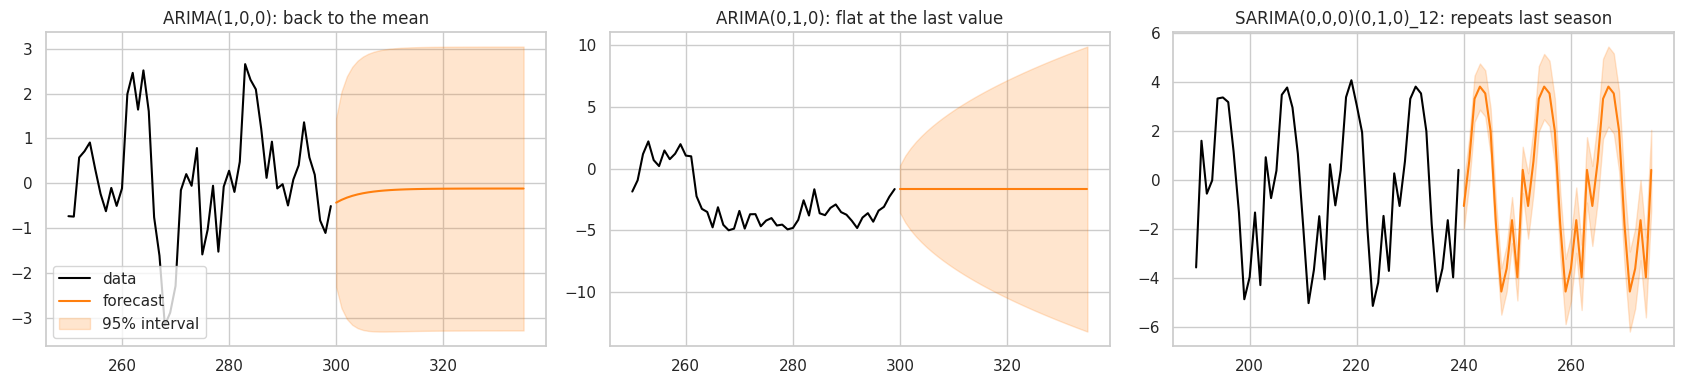

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

# AR(1): forecast slides back to the mean
y = simulated["AR(1), phi = 0.8"]
res = SARIMAX(y, order=(1, 0, 0), trend="c").fit(disp=False)
fc = res.get_forecast(36)
axes[0].plot(range(250, 300), y[250:], color="black", label="data")
axes[0].plot(range(300, 336), fc.predicted_mean, color="tab:orange", label="forecast")
axes[0].fill_between(range(300, 336), fc.conf_int()[:, 0], fc.conf_int()[:, 1], color="tab:orange", alpha=0.2, label="95% interval")
axes[0].set_title("ARIMA(1,0,0): back to the mean")

# random walk: forecast flat at the last value, interval keeps widening
y = simulated["Random walk  y_t = y_t-1 + e_t"]
res = SARIMAX(y, order=(0, 1, 0)).fit(disp=False)
fc = res.get_forecast(36)
axes[1].plot(range(250, 300), y[250:], color="black")
axes[1].plot(range(300, 336), fc.predicted_mean, color="tab:orange")
axes[1].fill_between(range(300, 336), fc.conf_int()[:, 0], fc.conf_int()[:, 1], color="tab:orange", alpha=0.2)
axes[1].set_title("ARIMA(0,1,0): flat at the last value")

# seasonal random walk: forecast repeats the last season
y = seasonal_rw
res = SARIMAX(y, order=(0, 0, 0), seasonal_order=(0, 1, 0, 12)).fit(disp=False)
fc = res.get_forecast(36)
axes[2].plot(range(190, 240), y[190:], color="black")
axes[2].plot(range(240, 276), fc.predicted_mean, color="tab:orange")
axes[2].fill_between(range(240, 276), fc.conf_int()[:, 0], fc.conf_int()[:, 1], color="tab:orange", alpha=0.2)
axes[2].set_title("SARIMA(0,0,0)(0,1,0)_12: repeats last season")
axes[0].legend(loc="lower left")
plt.tight_layout()
plt.show()

**These three forecast shapes explain most of Part 2:** a plain ARIMA forecast for 39 weeks will look like the left plot (flat after a few weeks), while a seasonal model looks like the right plot (it repeats the yearly pattern). Also note the **95% intervals**: they widen with the horizon for the random walk, and they widen once per season for the seasonal random walk.

## 1.6 SARIMAX: regression with SARIMA errors

**In plain words:** first explain the part of the sales we **know in advance** (holidays, the smooth shape of the year) with a regression, then let a SARIMA model whatever is left.

$$y_t = \beta_0 + \beta_1 x_{1,t} + \dots + \beta_k x_{k,t} + \eta_t, \qquad \eta_t \sim \text{SARIMA}(p,d,q)(P,D,Q)_s$$

- The $x$'s are **exogenous variables** (the "X" in SARIMAX).
- This is the form `statsmodels.SARIMAX` uses: the regression part is separate, and the **errors** $\eta_t$ follow a SARIMA. So $\beta$ keeps its usual meaning: "the effect of $x$ on $y$".
- **Rule (teammate's Note 5):** an $x$ is only allowed if its future values are **known at the forecast origin**. Calendar dummies and Fourier terms: ✅. Temperature, fuel price, CPI, unemployment: ❌ (we'd have to forecast them first).

### Dummy variables (0/1 columns)

`easter_week = 1` in the week before Easter, 0 otherwise. Because $y$ is the **log** of sales, the coefficient $\beta$ reads as a percentage:
$$\text{effect} = e^{\beta} - 1 \qquad (\beta = 0.7 \Rightarrow e^{0.7} - 1 \approx +101\%\text{, i.e. sales double})$$

### Fourier terms: building the yearly shape from waves

**In plain words:** any shape that repeats every year can be rebuilt by adding up sine and cosine waves of different speeds, just as a musical chord is made of a few notes. One slow wave (1 cycle per year) gives the summer/winter contrast; faster waves (2, 3, … cycles per year) add finer details.

$$x^{(k)}_{\sin,t} = \sin\!\left(\frac{2\pi k t}{m}\right),\quad x^{(k)}_{\cos,t} = \cos\!\left(\frac{2\pi k t}{m}\right),\qquad k = 1, \dots, K,\quad m = \frac{365.25}{7} \approx 52.18$$

| Why Fourier terms | Explanation |
|---|---|
| few parameters | $2K$ coefficients (e.g. 10 for $K = 5$) instead of 51 weekly dummies |
| smooth | they describe the **typical** year instead of copying last year's noise |
| exact period | $m = 52.18$ weeks, not 52: they follow the real calendar, which slides by about a day per year |
| $K$ is chosen by AIC | small $K$ = smooth shape, big $K$ = detailed shape |

Their weakness: a **1-week spike** (Easter) needs a very large $K$. That's why Fourier terms are combined with **holiday dummies** for the spikes. In Hyndman & Athanasopoulos (*Forecasting: Principles and Practice*), this is called **dynamic harmonic regression**.

### Important interaction: differencing removes repeating regressors

If the error is seasonally differenced ($D = 1$), the regression is differenced too: $y_t - y_{t-52} = \beta\,(x_t - x_{t-52}) + \dots$ For a dummy that falls in the **same week every year**, $x_t - x_{t-52} = 0$ always, so its coefficient **can't be estimated**: it vanishes. Only **moving** holidays survive differencing. Fourier terms almost vanish too. Hence two SARIMAX variants:

| Variant | Errors | Regressors |
|---|---|---|
| **SARIMAX-D** | SARIMA(p,0,q)(0,1,0)₅₂ | only the **moving** holiday dummies (`easter_week`, `valentine_week`, `halloween_week`) |
| **SARIMAX-F** | ARMA(p,q), no differencing | Fourier terms + **all** holiday dummies |

## 1.7 Estimating and choosing a model

**Estimation: maximum likelihood.** For given coefficients, the model says how likely the observed series is. Maximum likelihood picks the coefficients under which **the data we actually saw are the most likely**. statsmodels computes this likelihood with the **Kalman filter** (a step-by-step "predict, then correct" algorithm), which is also how it produces forecasts and intervals.

**Choosing between candidates: AICc.**
$$\text{AIC} = -2\log L + 2k, \qquad \text{AICc} = \text{AIC} + \frac{2k(k+1)}{n-k-1}$$
$\log L$ rewards a good fit, $k$ (number of parameters) is a penalty for complexity. **Lower is better.** AICc adds an extra penalty that matters when the sample is small (our $n$ is 104, or 52 after seasonal differencing), so I use AICc everywhere.

⚠️ **AIC/AICc can only compare models fitted on the same data.** A model on $y$ (D = 0) and a model on $y_t - y_{t-52}$ (D = 1) work on different data, so their AICc values are **not comparable**. Between families, I compare **forecast errors on the holdout** instead.

**Checking a model: residual diagnostics.** If the model captured everything predictable, the residuals (one-step-ahead errors on the train part) should look like **white noise**.
- **Ljung–Box test**: H₀ = "no autocorrelation in the residuals up to lag $m$". **p > 0.05 → OK** (no leftover pattern). p < 0.05 → the model missed some structure.
- `plot_diagnostics()` shows 4 pictures: residuals over time, their histogram, a Q-Q plot (normality), and their ACF.

**The Box–Jenkins cycle** (used for every model in Part 2):
```
 identify (plots, tests, ACF/PACF) → estimate (MLE, AICc) → diagnose (residuals) → forecast
        ↑                                                        │
        └──────────── if diagnostics fail, go back ──────────────┘
```

## 1.8 Log scale and back to dollars

All models are fitted on $\log(\text{sales})$, and forecasts are converted back with $e^{\hat y}$.

- $e^{\hat y}$ gives the **median** of the forecast distribution (not the mean). The mean would need a correction factor $e^{\sigma^2/2}$.
- For an **absolute-error** metric like WMAE, the median is the **best** point forecast. So no correction is needed, and $e^{\hat y}$ is the right choice here. (For a squared-error metric like RMSE, the mean would be better.)
- Prediction intervals are converted the same way ($e^{\text{lower}}, e^{\text{upper}}$), which makes them **asymmetric** in dollars: wider above than below, as is natural for sales.

## 1.9 Evaluation protocol (teammate's methodology)

| Item | Choice |
|---|---|
| Fit | train part, 104 weeks (2010-02-05 → 2012-01-27) |
| Forecast | 39 weeks from one origin (2012-02-03 → 2012-10-26) |
| Metric | WMAE, weight 5 for `is_holiday == 1` (in the holdout: 2012-02-10 Super Bowl, 2012-09-07 Labor Day) |
| Comparison | **relative WMAE** = model WMAE / seasonal-naive WMAE (< 1 = better than "same week last year") |
| Model selection | AICc on the **train part only**; the holdout is used **once**, for the final comparison |

# Part 2 — Store 1, step by step

## 2.0 Setup, data and helper functions

In [5]:
# the file built at the end of the EDA notebook: teammate's subset + calendar columns
subset = pd.read_csv(DATA_DIR + "depts_1_to_3_stat.csv", parse_dates=["Date", "week_start"])
week_calendar = pd.read_csv(DATA_DIR + "week_calendar.csv", parse_dates=["Date", "week_start"])

print("subset       :", subset.shape)
print("week_calendar:", week_calendar.shape, "(all 182 weeks: train part + holdout + forecast set)")
subset.head(3)

subset       : (19305, 19)
week_calendar: (182, 16) (all 182 weeks: train part + holdout + forecast set)


,Store,Dept,Date,Weekly_Sales,split,is_holiday,week_start,year,week_of_year,t,holiday_name,superbowl,valentine_week,easter_week,labor_day,halloween_week,thanksgiving,christmas_peak,christmas
0,1,1,2010-02-05,24924.50,train,0,2010-01-30,2010,5,0,NaN,0,0,0,0,0,0,0,0
1,1,1,2010-02-12,46039.49,train,1,2010-02-06,2010,6,1,Super Bowl,1,1,0,0,0,0,0,0
2,1,1,2010-02-19,41595.55,train,0,2010-02-13,2010,7,2,NaN,0,0,0,0,0,0,0,0


In [6]:
# all calendar flags (dummies) built in the EDA notebook, part F
ALL_FLAGS = ["superbowl", "valentine_week", "easter_week", "labor_day",
             "halloween_week", "thanksgiving", "christmas_peak", "christmas"]
# the flags whose week MOVES from one year to the next (EDA F.5) -> the only ones that survive seasonal differencing
MOVING_FLAGS = ["valentine_week", "easter_week", "halloween_week"]

missing = [c for c in ALL_FLAGS + ["t"] if c not in subset.columns]
assert not missing, f"re-run FPA_Project_EDA_full.ipynb first, these columns are missing: {missing}"
print("flags available:", ALL_FLAGS)

flags available: ['superbowl', 'valentine_week', 'easter_week', 'labor_day', 'halloween_week', 'thanksgiving', 'christmas_peak', 'christmas']


### Helper functions

Small functions I use everywhere below. Each one does a single job, so the modelling code stays short and readable.

In [7]:
def get_series(store, dept):
    # the rows of one series, split in train part and holdout (teammate's split column)
    s = subset[(subset["Store"] == store) & (subset["Dept"] == dept)].sort_values("Date").reset_index(drop=True)
    train_part = s[s["split"] == "train"].reset_index(drop=True)
    holdout = s[s["split"] == "test"].reset_index(drop=True)
    return train_part, holdout


def wmae(y_true, y_pred, is_holiday):
    # competition metric: mean absolute error, holiday weeks count 5 times
    w = np.where(np.asarray(is_holiday) == 1, 5, 1)
    return np.sum(w * np.abs(np.asarray(y_true) - np.asarray(y_pred))) / np.sum(w)


def fourier_terms(t, K, period=PERIOD):
    # K pairs of sin/cos waves with 1, 2, ..., K cycles per year; t = week counter
    t = np.asarray(t, dtype=float)
    cols = {}
    for k in range(1, K + 1):
        cols[f"sin{k}"] = np.sin(2 * np.pi * k * t / period)
        cols[f"cos{k}"] = np.cos(2 * np.pi * k * t / period)
    return pd.DataFrame(cols)


def ljung_box_p(residuals, n_params, lags=10):
    # Ljung-Box p-value: H0 = no autocorrelation left in the residuals (p > 0.05 = OK)
    lb = acorr_ljungbox(np.asarray(residuals), lags=[lags], model_df=n_params, return_df=True)
    return float(lb["lb_pvalue"].iloc[0])


def plot_forecast(ax, train_part, holdout, forecast, lower=None, upper=None, label="forecast", color="tab:orange", n_history=60):
    # last n_history weeks of the train part + the holdout + one forecast (and its 95% interval)
    hist = train_part.tail(n_history)
    ax.plot(hist["Date"], hist["Weekly_Sales"], color="tab:blue", linewidth=1.2, label="train part")
    ax.plot(holdout["Date"], holdout["Weekly_Sales"], color="black", linewidth=1.2, label="holdout (actual)")
    ax.plot(holdout["Date"], forecast, color=color, linestyle="--", linewidth=1.8, label=label)
    if lower is not None:
        ax.fill_between(holdout["Date"], lower, upper, color=color, alpha=0.15, label="95% interval")
    ax.axvline(split_date, color="red", linestyle=":", linewidth=1)

print("helpers ready")

helpers ready


I store every Store 1 forecast in one dictionary, so section 2.8 can compare them:

`store1_forecasts[dept][model_name] = array of 39 weekly forecasts in $`

In [8]:
store1_forecasts = {dept: {} for dept in DEPTS}
store1_series = {dept: get_series(FOCUS_STORE, dept) for dept in DEPTS}      # (train_part, holdout) per dept

for dept in DEPTS:
    train_part, holdout = store1_series[dept]
    print(f"Dept {dept}: train part {len(train_part)} weeks ({train_part['Date'].min().date()} -> {train_part['Date'].max().date()}), "
          f"holdout {len(holdout)} weeks ({holdout['Date'].min().date()} -> {holdout['Date'].max().date()})")

Dept 1: train part 104 weeks (2010-02-05 -> 2012-01-27), holdout 39 weeks (2012-02-03 -> 2012-10-26)
Dept 2: train part 104 weeks (2010-02-05 -> 2012-01-27), holdout 39 weeks (2012-02-03 -> 2012-10-26)
Dept 3: train part 104 weeks (2010-02-05 -> 2012-01-27), holdout 39 weeks (2012-02-03 -> 2012-10-26)


## 2.1 Baselines: the bar to beat

| Baseline | Forecast for every holdout week |
|---|---|
| naive | the last train week (2012-01-27) |
| mean | the average of the 104 train weeks |
| seasonal naive | the same week 52 weeks earlier |

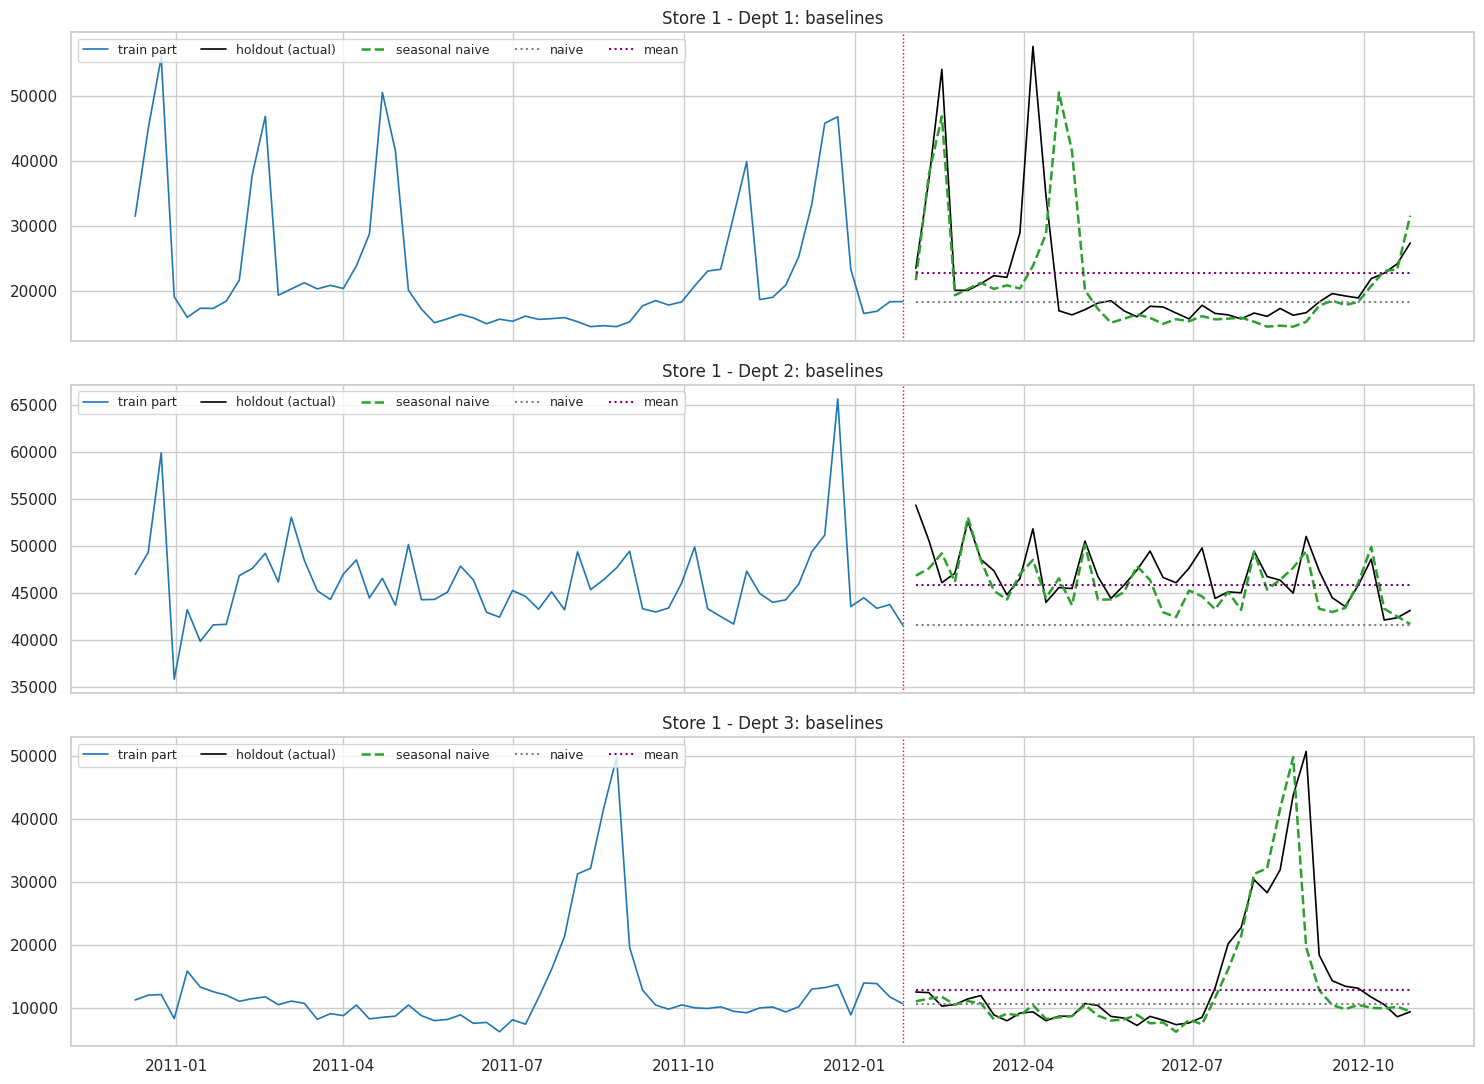

,Dept 1,Dept 2,Dept 3
naive,5748.0,5703.0,5457.0
mean,6847.0,2390.0,5546.0
seasonal naive,3486.0,1990.0,2607.0


In [9]:
for dept in DEPTS:
    train_part, holdout = store1_series[dept]
    y = train_part["Weekly_Sales"].values
    store1_forecasts[dept]["naive"] = np.repeat(y[-1], H)
    store1_forecasts[dept]["mean"] = np.repeat(y.mean(), H)
    store1_forecasts[dept]["seasonal naive"] = y[-52:][:H]       # holdout week k <- week k of the last train year

fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)
for ax, dept in zip(axes, DEPTS):
    train_part, holdout = store1_series[dept]
    plot_forecast(ax, train_part, holdout, store1_forecasts[dept]["seasonal naive"], label="seasonal naive", color="tab:green")
    ax.plot(holdout["Date"], store1_forecasts[dept]["naive"], color="grey", linestyle=":", label="naive")
    ax.plot(holdout["Date"], store1_forecasts[dept]["mean"], color="purple", linestyle=":", label="mean")
    ax.set_title(f"Store {FOCUS_STORE} - Dept {dept}: baselines")
    ax.legend(loc="upper left", ncol=5, fontsize=9)
plt.tight_layout()
plt.show()

baseline_wmae = pd.DataFrame({dept: {m: wmae(store1_series[dept][1]["Weekly_Sales"], store1_forecasts[dept][m],
                                             store1_series[dept][1]["is_holiday"]) for m in ["naive", "mean", "seasonal naive"]}
                              for dept in DEPTS}).round(0)
baseline_wmae.columns = [f"Dept {d}" for d in DEPTS]
baseline_wmae

**What I see**

- **Seasonal naive wins in all three departments** (3,486 / 1,990 / 2,607), by a wide margin for Depts 1 and 3, whose sales are dominated by peaks. The naive and mean forecasts are flat lines, so they can't produce any peak at all.
- The **mean** is not bad for Dept 2 (2,390) because Dept 2 is a "flat" department: its average week looks like most of its weeks. The **naive** forecast is bad for Dept 2 only because the last train week (27 Jan 2012, 41.5k) happened to be a low week.
- Where seasonal naive goes wrong tells us what a better model has to fix:
  1. **A holiday that moved (Dept 1, Easter).** The Easter week of 2012 (ending 6 April) came two weeks earlier than 52 weeks after the Easter week of 2011 (ending 22 April). So seasonal naive **misses the real peak** (23.9k forecast vs 57.6k actual) and draws a **ghost peak** copied from 2011 on 20 and 27 April (50.5k and 41.5k forecast, actual 17.0k and 16.3k). One moving holiday = two big errors.
  2. **A peak that slid by one week (Dept 3).** The back-to-school-like peak was in the week ending 26 Aug in 2011, but in the week ending 31 Aug in 2012: one week "late" compared with a 52-week copy. On the peak week itself, the copy says 19.6k (the 2011 week *after* the peak) while the actual was 50.7k.
  3. **A different level (Dept 2).** The first holdout weeks were above last year's (54.3k vs 46.8k on 3 Feb). A pure copy can't see that.

**Why it matters:** seasonal naive is the bar to beat, and section 1.5 showed it is already a SARIMA, SARIMA(0,0,0)(0,1,0)₅₂. Problem 3 is what SARIMA-D tries to fix (2.3), problem 1 is what SARIMAX-D and SARIMAX-F try to fix (2.5, 2.6). Problem 2 has no calendar flag behind it, so no model in this notebook will fully fix it.

## 2.2 ARIMA(p, 0, q): short-term memory only

### Step 1: Identify (what the EDA already told us)

| Question | EDA answer | Consequence |
|---|---|---|
| transformation? | std ∝ level (G.3) | model $\log(\text{sales})$ |
| differencing $d$? | stationary by ADF and KPSS for all 3 Store 1 series (G.4); trend ≈ 0 (G.2) | $d = 0$, with a constant |
| $p$, $q$? | Dept 1: ACF 0.67 then fast decay, PACF cut after 2 → AR(1)–AR(2). Dept 2: almost no autocorrelation. Dept 3: slow decay → AR(1)–AR(2) (G.5) | try $p, q \in \{0, 1, 2\}$ |

### Step 2: Estimate. Try 9 candidates, keep the lowest AICc

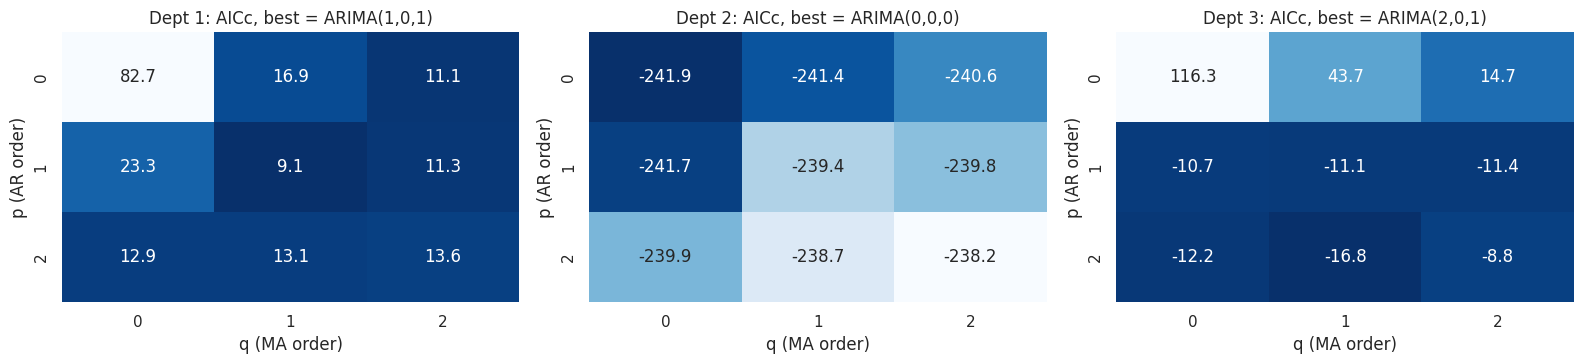

In [10]:
arima_store1 = {}
for dept in DEPTS:
    train_part, holdout = store1_series[dept]
    y_log = np.log(train_part["Weekly_Sales"].values)

    aicc_table = pd.DataFrame(index=[0, 1, 2], columns=[0, 1, 2], dtype=float)   # rows = p, columns = q
    fits = {}
    for p, q in itertools.product([0, 1, 2], [0, 1, 2]):
        res = SARIMAX(y_log, order=(p, 0, q), trend="c").fit(disp=False)        # trend="c": include a constant
        aicc_table.loc[p, q] = res.aicc
        fits[(p, q)] = res

    best_order = aicc_table.stack().idxmin()                                     # (p, q) with the lowest AICc
    arima_store1[dept] = {"aicc_table": aicc_table, "order": best_order, "res": fits[best_order]}

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, dept in zip(axes, DEPTS):
    sns.heatmap(arima_store1[dept]["aicc_table"], annot=True, fmt=".1f", cmap="Blues_r", cbar=False, ax=ax)
    p, q = arima_store1[dept]["order"]
    ax.set_title(f"Dept {dept}: AICc, best = ARIMA({p},0,{q})")
    ax.set_xlabel("q (MA order)")
    ax.set_ylabel("p (AR order)")
plt.tight_layout()
plt.show()

> **Code explained**
> - `SARIMAX(y_log, order=(p, 0, q), trend="c")`: statsmodels has one class for the whole family. `order=(p, d, q)`; no `seasonal_order` → plain ARIMA; `trend="c"` adds a constant.
> - `.fit(disp=False)`: maximum-likelihood estimation; `disp=False` hides the optimiser's messages.
> - `res.aicc`: the AICc of the fitted model.
> - `aicc_table.stack().idxmin()`: `stack()` turns the 3 × 3 table into a list indexed by (p, q), and `idxmin()` returns the (p, q) of the smallest value.

In [11]:
# the full statsmodels summary of the chosen model for Dept 1
print(arima_store1[1]["res"].summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  104
Model:               SARIMAX(1, 0, 1)   Log Likelihood                  -0.357
Date:                Tue, 10 Nov 2026   AIC                              8.715
Time:                        20:51:54   BIC                             19.292
Sample:                             0   HQIC                            13.000
                                - 104                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      6.0392      1.252      4.824      0.000       3.585       8.493
ar.L1          0.3936      0.121      3.247      0.001       0.156       0.631
ma.L1          0.5792      0.109      5.305      0.0

### How to read a statsmodels `summary()`

| Block | What it says |
|---|---|
| **Top** | `No. Observations` (104), `Log Likelihood`, `AIC`/`BIC`/`HQIC` (information criteria, lower = better) |
| **Coefficient table** | one row per parameter: `intercept` = the constant $c$; `ar.L1` = $\phi_1$ (lag 1); `ma.L1` = $\theta_1$; `sigma2` = variance of the surprises $\varepsilon_t$. `coef` = estimate, `std err` = its uncertainty, `P>\|z\|` < 0.05 = significantly different from 0, `[0.025 0.975]` = 95% confidence interval |
| **Bottom** | quick residual checks: `Ljung-Box (L1) (Q)` + `Prob(Q)` (autocorrelation at lag 1, p > 0.05 = OK); `Jarque-Bera` + `Prob(JB)` (normality, p < 0.05 = not normal); `Heteroskedasticity (H)` + `Prob(H)` (does the variance change between the start and the end?); `Skew`, `Kurtosis` (shape of the residual distribution; normal = 0 and 3) |

On the log scale, `ar.L1` reads as "a week x% above normal is followed by a week about $\phi \cdot$ x% above normal".

### Step 3: Diagnose (are the residuals white noise?)

In [12]:
rows = []
for dept in DEPTS:
    res = arima_store1[dept]["res"]
    p, q = arima_store1[dept]["order"]
    rows.append({"Dept": dept, "model": f"ARIMA({p},0,{q})",
                 "Ljung-Box p (lag 10)": round(ljung_box_p(res.resid, n_params=p + q), 3),
                 "residual std (log)": round(np.std(res.resid), 3)})
pd.DataFrame(rows).set_index("Dept")

,model,Ljung-Box p (lag 10),residual std (log)
Dept,,,
1,"ARIMA(1,0,1)",0.095,0.243
2,"ARIMA(0,0,0)",0.156,0.074
3,"ARIMA(2,0,1)",0.598,0.211


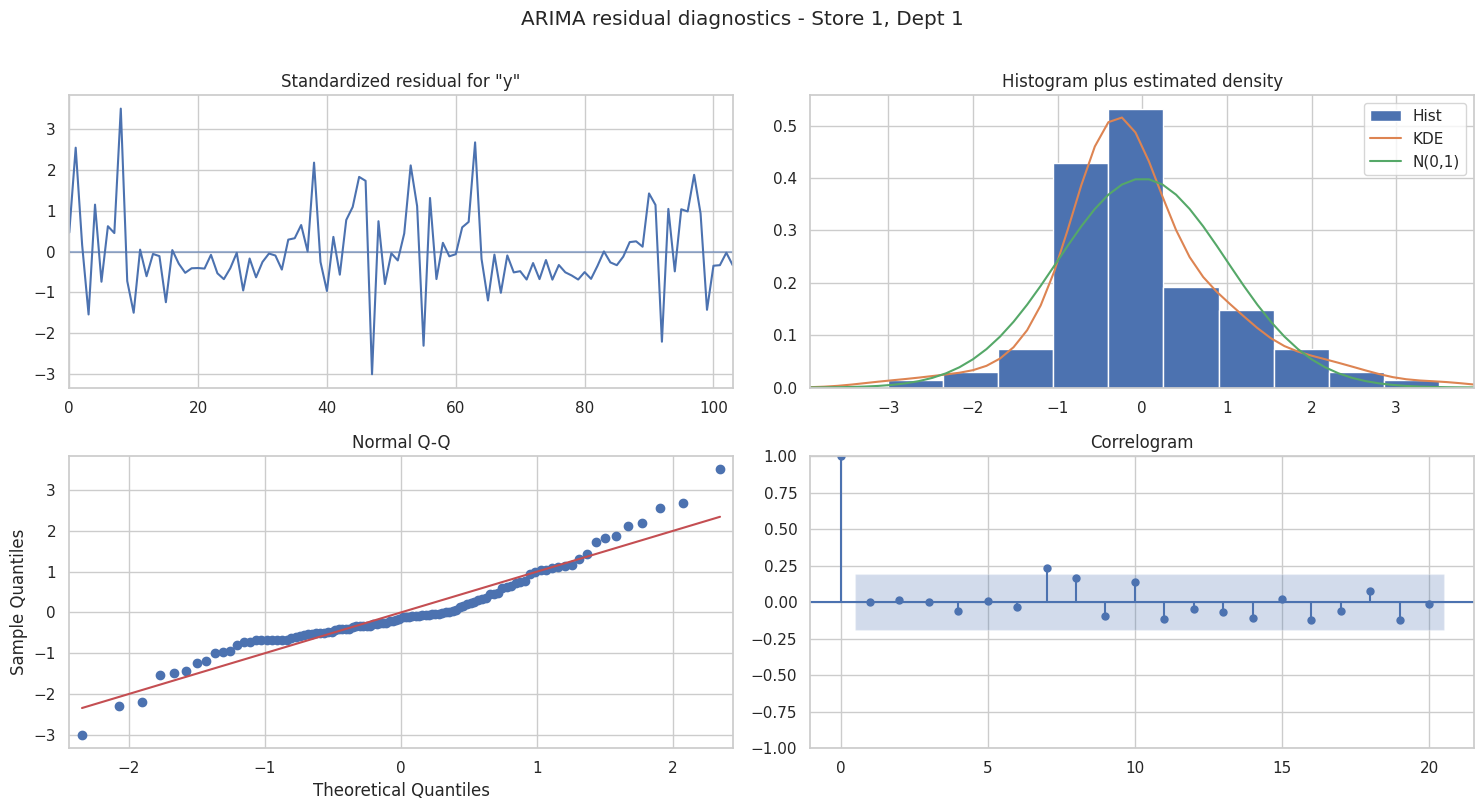

In [13]:
# the 4 standard diagnostic plots, for Dept 1
fig = arima_store1[1]["res"].plot_diagnostics(figsize=(15, 8), lags=20)
fig.suptitle("ARIMA residual diagnostics - Store 1, Dept 1", y=1.01)
plt.tight_layout()
plt.show()

> **The 4 diagnostic plots:** (top-left) standardised residuals over time: should look like random noise around 0; (top-right) histogram vs a normal curve; (bottom-left) Q-Q plot: points on the red line = normal; (bottom-right) correlogram = ACF of the residuals: no bar outside the band = no pattern left.

**What I see**

- **AICc picks small models:** ARIMA(1,0,1) for Dept 1, ARIMA(0,0,0) for Dept 2, ARIMA(2,0,1) for Dept 3.
  - For Dept 2 the nine candidates are within 4 AICc points of each other: on the log scale, Dept 2 is basically "its mean + noise".
  - For Dept 3, every model without an AR term ($p = 0$, first row of the heatmap) is far worse (AICc 15 to 116, vs −17 for the best): its weeks are strongly tied to the previous weeks, because the August peak builds up over several weeks.
- **Reading the Dept 1 summary:** `ar.L1` = 0.39 and `ma.L1` = 0.58, both clearly significant (P>|z| ≈ 0). The `intercept` is the constant $c$, **not** the mean: the long-run mean of log sales is $c/(1-\phi) = 6.039/(1-0.394) \approx 9.97$, i.e. about 21.3k per week once converted back with the exponential. Keep this number in mind for the next plot. `sigma2` = 0.058, so a typical weekly surprise is $\sqrt{0.058} \approx 0.24$ on the log scale: about ±24%.
- **Residual checks:** the correlogram (bottom right) stays inside the band (lag 7 just touches it), and the Ljung–Box p-values are 0.095 / 0.156 / 0.598. **All three models "pass"** (p > 0.05).
- **But the residuals are not normal:** Jarque–Bera p = 0.00, skew 0.60, kurtosis 4.80 (a normal distribution has 3). The histogram is more peaked than the green normal curve and has a long right tail, and the Q-Q plot bends away from the red line at both ends. The biggest standardised residuals (up to +3.5) are the **holiday weeks**: the model is surprised by every peak, and by the drop right after it.

**In plain words:** by the textbook checklist, this model is fine: one week ahead, its surprises look random. But the checklist only asks *"knowing the last weeks, was this week a surprise?"* (one-step-ahead errors, lags 1–10). It never looks at lag 52, and it never asks *"how good is the forecast 39 weeks ahead?"*, which is our real task. The heavy tails are the warning sign: they are the yearly peaks the model can't explain. The next plot shows the consequence.

### Step 4: Forecast the 39 holdout weeks

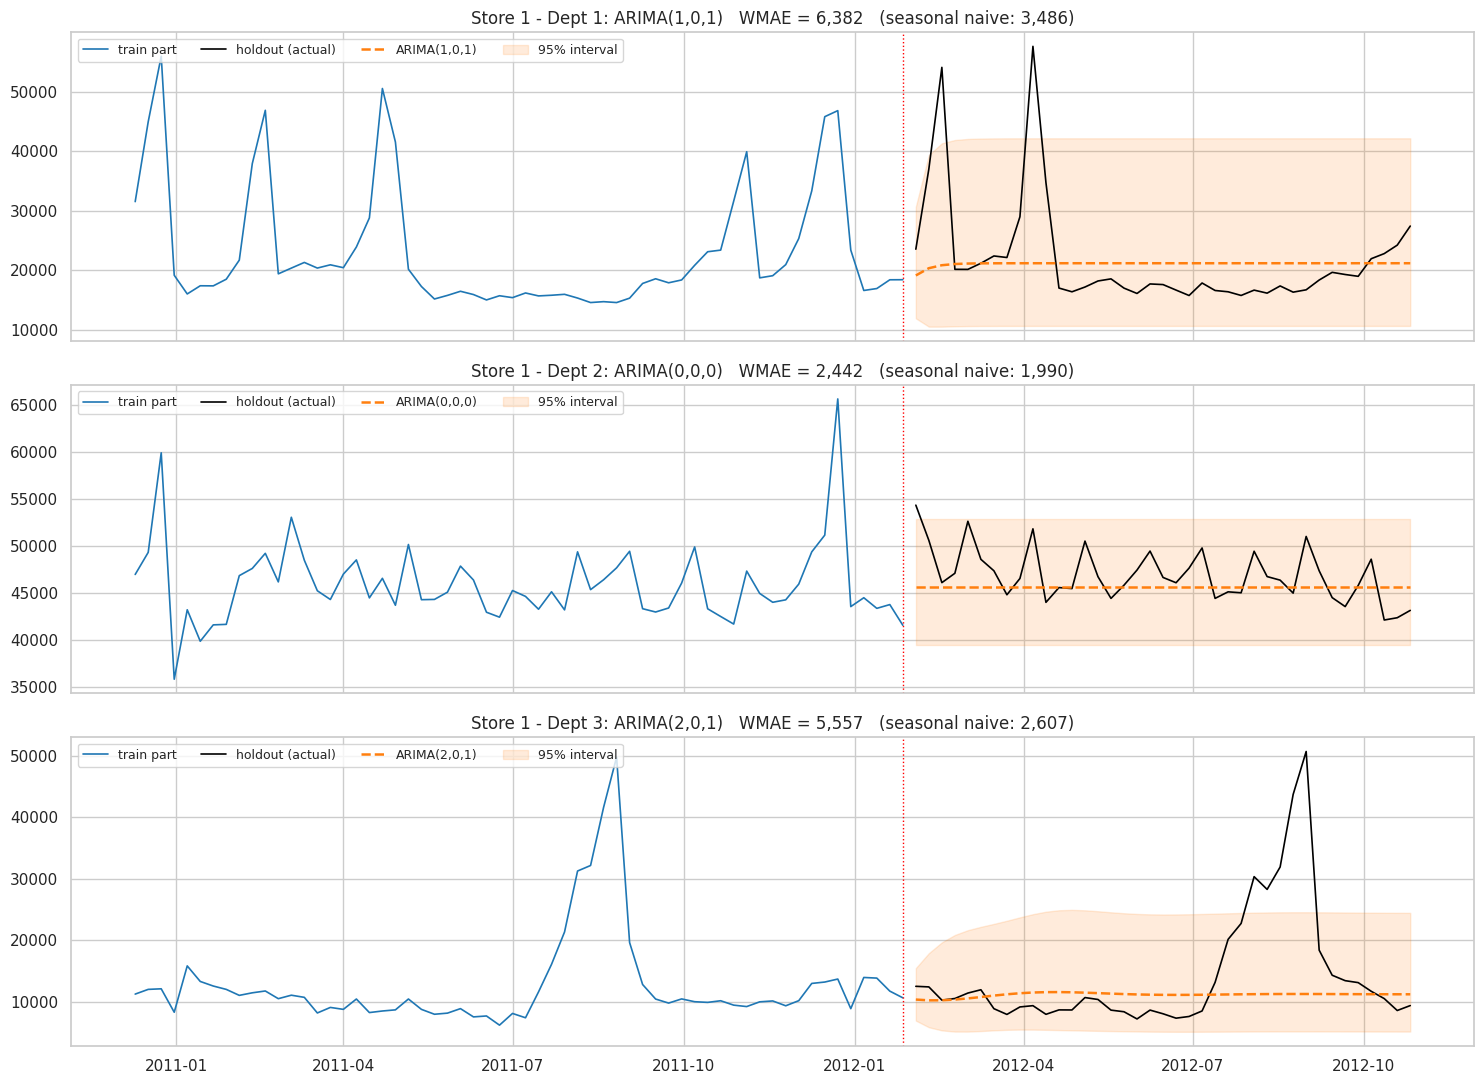

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)
for ax, dept in zip(axes, DEPTS):
    train_part, holdout = store1_series[dept]
    res = arima_store1[dept]["res"]
    fc = res.get_forecast(steps=H)                       # forecast object
    mean_log = fc.predicted_mean                         # point forecast, log scale
    ci_log = fc.conf_int(alpha=0.05)                     # 95% interval, log scale (2 columns: lower, upper)
    forecast = np.exp(mean_log)                          # back to dollars (median forecast, see 1.8)
    store1_forecasts[dept]["ARIMA"] = forecast

    p, q = arima_store1[dept]["order"]
    plot_forecast(ax, train_part, holdout, forecast, np.exp(ci_log[:, 0]), np.exp(ci_log[:, 1]), label=f"ARIMA({p},0,{q})")
    ax.set_title(f"Store {FOCUS_STORE} - Dept {dept}: ARIMA({p},0,{q})   WMAE = {wmae(holdout['Weekly_Sales'], forecast, holdout['is_holiday']):,.0f}"
                 f"   (seasonal naive: {wmae(holdout['Weekly_Sales'], store1_forecasts[dept]['seasonal naive'], holdout['is_holiday']):,.0f})")
    ax.legend(loc="upper left", ncol=4, fontsize=9)
plt.tight_layout()
plt.show()

**What I see**

- After 2–3 weeks, **every ARIMA forecast is a flat line.** Dept 1 climbs from about 19k to about 21.2k (the long-run mean computed above) and stays there. Dept 2 is flat from the first week (ARIMA(0,0,0) *is* the mean). Dept 3 slowly rises to about 11.3k.
- **None of the peaks is forecast:** not Valentine's Day or Easter (Dept 1), not the August peak (Dept 3).
- The **95% intervals** are wide and constant (Dept 1: about 10k to 42k): the model "knows" it doesn't know. Even so, the Easter week (57.6k) and the Dept 3 peak (50.7k) fall outside.
- **WMAE 6,382 / 2,442 / 5,557**: almost the same as the *mean* baseline (6,847 / 2,390 / 5,546), and about **twice** the seasonal naive (3,486 / 1,990 / 2,607).

**In plain words:** an ARIMA with $d = 0$ answers one question: *how fast does a deviation from normal fade away?* With $\phi = 0.39$, a week 30% above normal is followed by a week roughly 12% above normal, then 5%, then 2%… After 39 weeks everything has faded, so the forecast is "an average week". Section 1.4 predicted exactly this.

**Why the ARIMA is slightly better than the mean baseline in Dept 1:** the exponential of the mean *log* sales (21.2k) is a "typical week" level, below the plain average (22.8k) that the peaks pull up. For an absolute-error metric like WMAE, a flat line at the typical level beats a flat line at the average (section 1.8).

**Lessons**
1. For a 39-week horizon, short-term memory is worth almost nothing. The information has to come from **the yearly pattern**, which is what the "S" of SARIMA adds.
2. These same models *passed* the residual checks in the previous cell. **Good residuals ≠ good long-horizon forecasts.** This comes back in Part 3.

## 2.3 SARIMA-D = SARIMA(p, 0, q)(0, 1, 0)₅₂: copy last year, then correct

### Step 1: Identify

The seasonal difference $w_t = \log y_t - \log y_{t-52}$ is the **yearly change** (≈ % growth vs the same week last year). We have 52 values of it (EDA G.6). The ARMA part of SARIMA-D is identified on $w_t$:

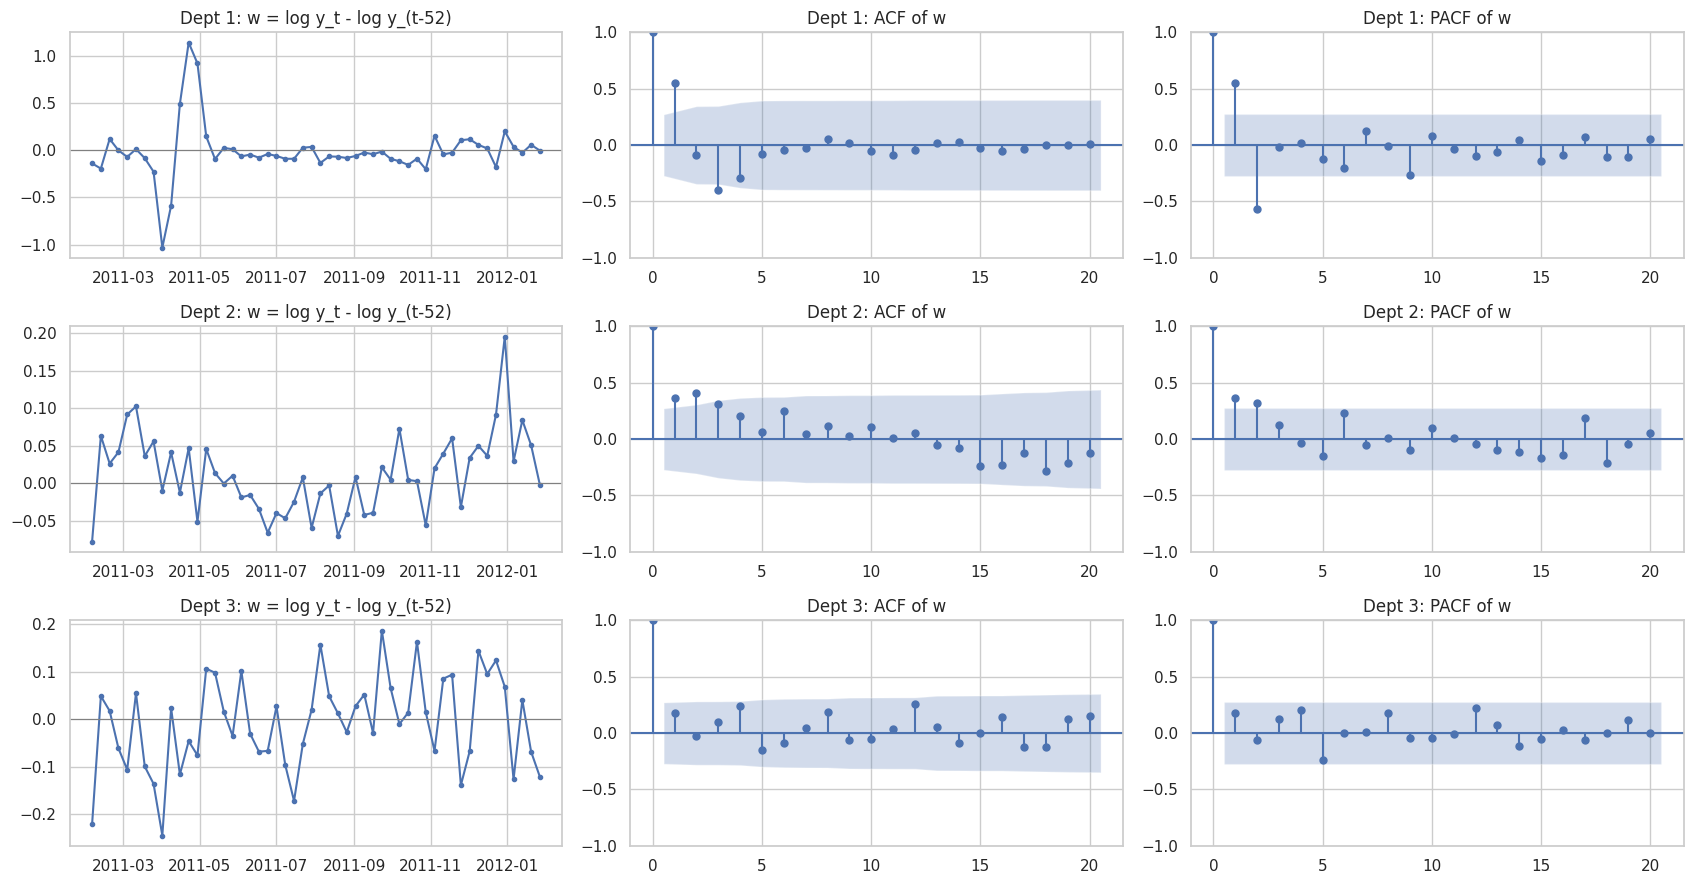

In [15]:
fig, axes = plt.subplots(3, 3, figsize=(17, 9))
for row, dept in enumerate(DEPTS):
    train_part, holdout = store1_series[dept]
    y_log = np.log(train_part["Weekly_Sales"].values)
    w = y_log[52:] - y_log[:-52]                        # 52 yearly changes (log scale)
    axes[row, 0].plot(train_part["Date"].iloc[52:], w, marker="o", markersize=3)
    axes[row, 0].axhline(0, color="grey", linewidth=0.8)
    axes[row, 0].set_title(f"Dept {dept}: w = log y_t - log y_(t-52)")
    plot_acf(w, lags=20, ax=axes[row, 1], title=f"Dept {dept}: ACF of w")
    plot_pacf(w, lags=20, ax=axes[row, 2], method="ywm", title=f"Dept {dept}: PACF of w")
plt.tight_layout()
plt.show()

**What I see** (left: the yearly change $w_t$; middle and right: its ACF and PACF, computed on 52 values)

- **Dept 1:** $w$ is almost flat (within about ±15%) except for **one big swing in spring 2011**: −1.03 on 1 April 2011 and −0.59 on 8 April, then +1.14 on 22 April and +0.92 on 29 April. That's **Easter moving**: on 1 April 2011, the same week one year earlier was the Easter week of 2010, so this year looks 64% below last year ($e^{-1.03} \approx 0.36$). Three weeks later it's the opposite: Easter 2011 against a normal week of 2010.
- The ACF of Dept 1 has a big bar at lag 1 (≈ 0.55) and **negative bars at lags 3–4** (≈ −0.40 and −0.30); the PACF cuts off after lag 2 (≈ 0.55 and −0.57). Read with the rules of 1.2, that's an **AR(2)**.
- **But look at where this pattern comes from:** a block of big negative values followed, three weeks later, by a block of big positive values creates exactly a negative correlation at lag 3. Most of the "AR structure" of Dept 1 is the **Easter shift**, a calendar effect. An ARMA can only imitate it; a holiday regressor can describe it directly (section 2.5).
- **Dept 2:** $w$ wanders slowly: +5 to +10% in spring 2011, about −5% in summer, positive again at the end of 2011 (about +20% in the Christmas week). The ACF stays positive for lags 1–3 (≈ 0.37, 0.41, 0.32) and decays slowly, the PACF has bars at lags 1–2 → **AR(1) or AR(2)**. In plain words: when this year runs above last year, the next weeks probably will too ("momentum" in the yearly growth).
- **Dept 3:** $w$ looks like noise (about ±20%) and no bar is clearly outside the band → **white noise**, maybe a small MA term. "Same week last year" already says almost everything.
- The blue bands are wide (about ±0.27) because there are only **52** values: only fairly strong correlations can be detected. That's the data budget of section 1.5 again.

**Expected orders:** Dept 1 AR(2), Dept 2 AR(1)–AR(2), Dept 3 (0,0,0) or MA(1). The AICc search below confirms all three.

### Step 2: Estimate. ARMA(p, q) on $w$, with or without a constant (drift)

In [16]:
sarima_d_store1 = {}
for dept in DEPTS:
    train_part, holdout = store1_series[dept]
    y_log = np.log(train_part["Weekly_Sales"].values)
    w = y_log[52:] - y_log[:-52]

    rows, fits = [], {}
    for p, q, trend in itertools.product([0, 1, 2], [0, 1], ["n", "c"]):        # "n" = no constant, "c" = drift
        res = SARIMAX(w, order=(p, 0, q), trend=trend).fit(disp=False)
        rows.append({"p": p, "q": q, "drift": trend == "c", "AICc": res.aicc})
        fits[(p, q, trend)] = res
    table = pd.DataFrame(rows).sort_values("AICc").reset_index(drop=True)
    best = table.iloc[0]
    key = (int(best["p"]), int(best["q"]), "c" if best["drift"] else "n")
    sarima_d_store1[dept] = {"table": table, "key": key, "res": fits[key]}
    print(f"Dept {dept}: best = SARIMA({key[0]},0,{key[1]})(0,1,0)52{' + drift' if key[2] == 'c' else ''}")
    print(table.head(4).round(2).to_string(index=False), "\n")

Dept 1: best = SARIMA(2,0,0)(0,1,0)52
 p  q  drift   AICc
 2  0  False -13.88
 2  0   True -11.63
 2  1  False -11.54
 2  1   True  -9.19 



Dept 2: best = SARIMA(2,0,0)(0,1,0)52
 p  q  drift    AICc
 2  0  False -166.70
 1  1  False -165.81
 2  0   True -164.90
 2  1  False -164.85 



Dept 3: best = SARIMA(0,0,1)(0,1,0)52
 p  q  drift   AICc
 0  1  False -92.55
 0  0  False -92.46
 1  0  False -92.23
 0  0   True -90.60 



**Check: is "ARMA on the seasonal difference" really the same as statsmodels' built-in SARIMA?** I fit SARIMA(1,0,0)(0,1,0)₅₂ both ways and compare the 39 forecasts.

In [17]:
for dept in DEPTS:
    train_part, holdout = store1_series[dept]
    y_log = np.log(train_part["Weekly_Sales"].values)

    # (a) built-in: statsmodels does the seasonal differencing itself
    builtin = SARIMAX(y_log, order=(1, 0, 0), seasonal_order=(0, 1, 0, 52)).fit(disp=False)
    f_builtin = np.exp(builtin.forecast(H))

    # (b) by hand: ARMA on w, then add back last year's value
    w = y_log[52:] - y_log[:-52]
    manual = SARIMAX(w, order=(1, 0, 0)).fit(disp=False)
    f_manual = np.exp(y_log[-52:][:H] + manual.forecast(H))

    print(f"Dept {dept}: largest difference between the two forecasts = {np.max(np.abs(f_builtin / f_manual - 1)):.6%}")

Dept 1: largest difference between the two forecasts = 0.000002%


Dept 2: largest difference between the two forecasts = 0.000018%


Dept 3: largest difference between the two forecasts = 0.000034%


**Identical.** So in the rest of the notebook I use the "by hand" version. It's the same model, but about 15× faster, and it makes the logic visible: **forecast = same week last year + forecast of the yearly change**.

### Step 3: Diagnose, and Step 4: Forecast

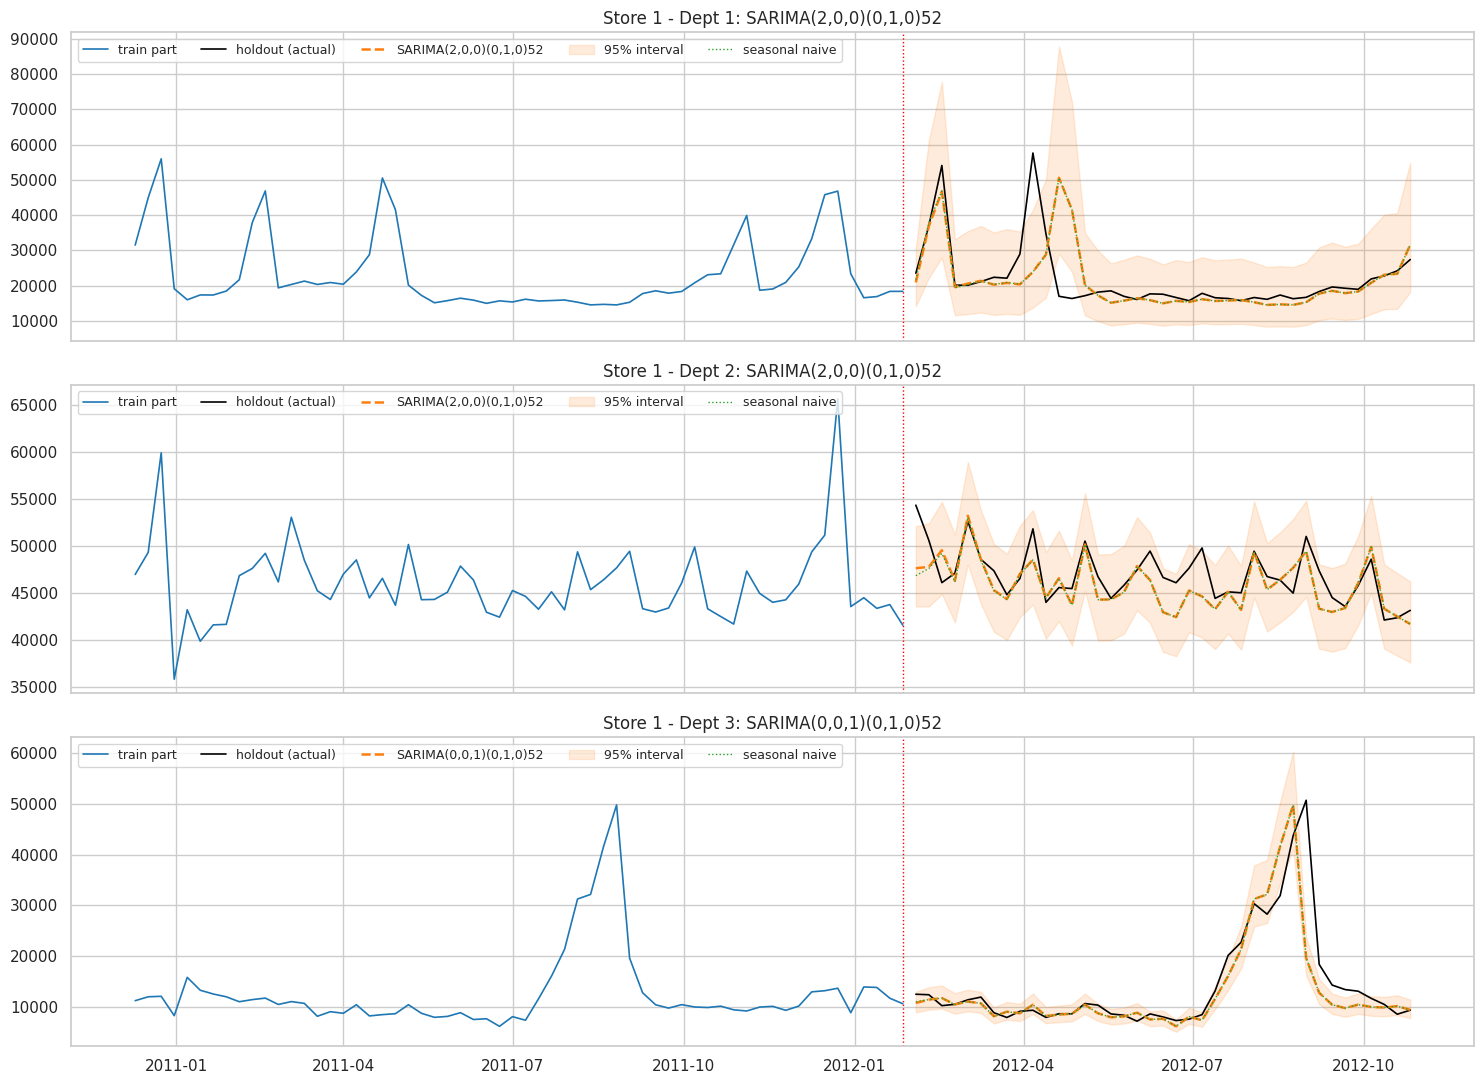

,model,Ljung-Box p (lag 10),WMAE,seasonal naive WMAE
Dept,,,,
1,"SARIMA(2,0,0)(0,1,0)52",0.571,3431,3486
2,"SARIMA(2,0,0)(0,1,0)52",0.566,1959,1990
3,"SARIMA(0,0,1)(0,1,0)52",0.323,2613,2607


In [18]:
rows = []
fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)
for ax, dept in zip(axes, DEPTS):
    train_part, holdout = store1_series[dept]
    y_log = np.log(train_part["Weekly_Sales"].values)
    p, q, trend = sarima_d_store1[dept]["key"]
    res = sarima_d_store1[dept]["res"]

    fc = res.get_forecast(steps=H)
    last_year = y_log[-52:][:H]                                   # log sales of the same weeks one year earlier
    forecast = np.exp(last_year + fc.predicted_mean)              # same week last year + forecast of the yearly change
    ci = fc.conf_int(alpha=0.05)
    lower, upper = np.exp(last_year + ci[:, 0]), np.exp(last_year + ci[:, 1])
    store1_forecasts[dept]["SARIMA-D"] = forecast

    name = f"SARIMA({p},0,{q})(0,1,0)52{' + drift' if trend == 'c' else ''}"
    rows.append({"Dept": dept, "model": name, "Ljung-Box p (lag 10)": round(ljung_box_p(res.resid, n_params=p + q), 3),
                 "WMAE": round(wmae(holdout["Weekly_Sales"], forecast, holdout["is_holiday"])),
                 "seasonal naive WMAE": round(wmae(holdout["Weekly_Sales"], store1_forecasts[dept]["seasonal naive"], holdout["is_holiday"]))})
    plot_forecast(ax, train_part, holdout, forecast, lower, upper, label=name)
    ax.plot(holdout["Date"], store1_forecasts[dept]["seasonal naive"], color="tab:green", linestyle=":", linewidth=1, label="seasonal naive")
    ax.set_title(f"Store {FOCUS_STORE} - Dept {dept}: {name}")
    ax.legend(loc="upper left", ncol=5, fontsize=9)
plt.tight_layout()
plt.show()
pd.DataFrame(rows).set_index("Dept")

**What I see**

- **Chosen models:** SARIMA(2,0,0)(0,1,0)₅₂ for Depts 1 and 2, SARIMA(0,0,1)(0,1,0)₅₂ for Dept 3, as the ACF/PACF suggested. For Dept 3, the top three candidates are within 0.3 AICc points (−92.55, −92.46, −92.23). A difference below 2 means "no real difference", so (0,0,0), i.e. the plain seasonal naive, is just as good.
- **No drift** for any Store 1 series: adding a constant yearly growth never improves the AICc. That's consistent with the EDA: Store 1's sales don't grow from one year to the next.
- **The "by hand" shortcut is exact:** statsmodels' built-in SARIMA and "ARMA on $w$ + last year" give the same forecasts (largest difference 0.000034%).
- **Residuals are white noise** for all three (Ljung–Box p = 0.571 / 0.566 / 0.323), better than the ARIMA.
- **But the forecasts are almost the seasonal naive:** the orange and green dotted lines lie on top of each other. WMAE **3,431 / 1,959 / 2,613** vs **3,486 / 1,990 / 2,607**: −1.6%, −1.6% and +0.2%.

**Why so little gain?** The forecast is *last year + a forecast of the yearly change*. The ARMA part only knows the **last few** yearly changes. At the origin, Dept 2 ran a little above last year, so the first holdout weeks are lifted a little (47.6k instead of 46.8k on 3 Feb; the actual was 54.3k). Because the ARMA is stationary and has no drift, this correction **fades to 0 within a few weeks**, exactly like the ARIMA forecast faded to the mean. From about week 10 to week 39, SARIMA-D *is* the seasonal naive, with all its mistakes: the Easter ghost of Dept 1 and the one-week-early peak of Dept 3.

**The intervals** are "± a percentage of last year's value" (they are symmetric on the log scale). In dollars they become huge around copied peaks: up to about 88k around the ghost Easter peak of Dept 1.

**Lesson:** with two years of history, a SARIMA can learn *"copy last year, plus a short-lived correction"*. That's useful for the first weeks after the origin and useless at week 39. To beat seasonal naive at long horizons we have to change **what** is copied: the holidays (SARIMAX, 2.5).

## 2.4 SARIMA-AR = SARIMA(p, 0, 0)(1, 0, 0)₅₂: let the data choose how much of last year to copy

No differencing. The seasonal AR coefficient $\Phi$ (`ar.S.L52`) says how much of last year's deviation from the mean comes back this year. Two practical details:

1. **I subtract the mean of log sales first** and fit without a constant: $(y_t - \bar y) = \Phi\,(y_{t-52} - \bar y) + \dots$ When $\Phi$ gets close to 1, a free constant becomes almost impossible to estimate (it's divided by $1-\Phi$), and the forecast can explode. With the mean fixed beforehand this can't happen.
2. **Approximate diffuse start** (`initialize_approximate_diffuse()`): the model doesn't try to guess the state before the first week (which needs $\Phi < 1$ strictly and fails numerically near 1). In practice $\Phi$ is learned from the 52 (this year, last year) pairs, exactly the data budget of section 1.5.

In [19]:
sarima_ar_store1 = {}
rows = []
for dept in DEPTS:
    train_part, holdout = store1_series[dept]
    y_log = np.log(train_part["Weekly_Sales"].values)

    y_mean = y_log.mean()                                              # 1. subtract the mean of log sales

    best = None
    for p in [0, 1]:
        model = SARIMAX(y_log - y_mean, order=(p, 0, 0), seasonal_order=(1, 0, 0, 52), trend="n")
        model.initialize_approximate_diffuse()                         # 2. stable start, even when Phi ~ 1
        res = model.fit(disp=False)
        if best is None or res.aicc < best[1].aicc:
            best = (p, res)
    p, res = best
    Phi = res.params[res.model.param_names.index("ar.S.L52")]          # the seasonal AR coefficient
    forecast = np.exp(res.forecast(H) + y_mean)                        # add the mean back, then back to dollars
    store1_forecasts[dept]["SARIMA-AR"] = forecast
    sarima_ar_store1[dept] = {"p": p, "res": res, "Phi": Phi}
    rows.append({"Dept": dept, "model": f"SARIMA({p},0,0)(1,0,0)52", "Phi (ar.S.L52)": round(Phi, 3),
                 "Ljung-Box p (lag 10)": round(ljung_box_p(res.resid[52:], n_params=p + 1), 3),
                 "WMAE": round(wmae(holdout["Weekly_Sales"], forecast, holdout["is_holiday"]))})
pd.DataFrame(rows).set_index("Dept")

,model,Phi (ar.S.L52),Ljung-Box p (lag 10),WMAE
Dept,,,,
1,"SARIMA(1,0,0)(1,0,0)52",0.532,0.010,4062
2,"SARIMA(0,0,0)(1,0,0)52",0.755,0.008,1957
3,"SARIMA(0,0,0)(1,0,0)52",0.997,0.309,2596


> **Code explained:** `res.model.param_names` is the list of parameter names, e.g. `['intercept', 'ar.L1', 'ar.S.L52', 'sigma2']`. `.index("ar.S.L52")` finds the position of $\Phi$, and `res.params[...]` reads its value. For the Ljung–Box test I skip the first 52 residuals: during the first year the model has no "last year" to look at yet.

**What I see**

| | $\Phi$ | Meaning | WMAE vs seasonal naive |
|---|---|---|---|
| Dept 1 | 0.53 | keep about half of last year's ups and downs | 4,062 vs 3,486 (**+17%**) |
| Dept 2 | 0.76 | keep about three quarters | 1,957 vs 1,990 (−2%) |
| Dept 3 | 1.00 (0.997) | copy last year completely | 2,596 vs 2,607 (−0.4%) |

- **Dept 3:** $\Phi \approx 1$ means the data themselves say *"this year = last year"*. That's the signal that seasonal differencing ($D = 1$) is the right description, as anticipated in 1.5.
- **Dept 2:** the yearly pattern only partly repeats. Shrinking last year's wiggles by a quarter removes some of last year's noise: a small gain.
- **Dept 1:** why only 0.53 for the most seasonal department? $\Phi$ is learned from the 52 pairs *(week of 2011, same week of 2010)*, and in those pairs **all three moving holidays of Dept 1 moved** (EDA F.5: Valentine's and Halloween by one week, Easter by three). Each move creates pairs like *"peak last year → normal week this year"* (and the reverse), which look like *"last year doesn't repeat"* and drag $\Phi$ down. Then, in the holdout, the peaks that **do** repeat (Valentine's, the October build-up) are cut in half → worse than seasonal naive.
- **Ljung–Box fails for Depts 1 and 2** (p = 0.010 and 0.008): a shrunk copy leaves part of the yearly pattern in the residuals.

**Lessons**
1. $\Phi$ is a useful diagnostic: close to 1 → use $D = 1$. Clearly below 1 for a strongly seasonal series → something distorts the year-to-year pairs (here, moving holidays).
2. One coefficient for the whole year can't tell *"a peak that repeats"* from *"a peak that moved"*. Only explicit holiday information can, which is the next step.

## 2.5 SARIMAX-D: SARIMA-D + the holidays that moved

### Why only these dummies?

SARIMA-D compares each week with the same week last year. For a holiday that falls in the same week every year (Super Bowl, Labor Day, Thanksgiving, Christmas), that comparison is already right. For the **moving** pre-holiday weeks (Easter, Valentine's and Halloween in our years, EDA F.5) it compares a holiday week with a normal week. So I add these 3 dummies as regressors. On the differenced scale the regressor becomes $x_t - x_{t-52}$:
- **+1** in a holiday week whose same week last year was normal,
- **−1** in a normal week whose same week last year was the holiday,
- **0** when both years agree.

This way the model **removes** last year's Easter peak from the copy and **adds** this year's at the right place.

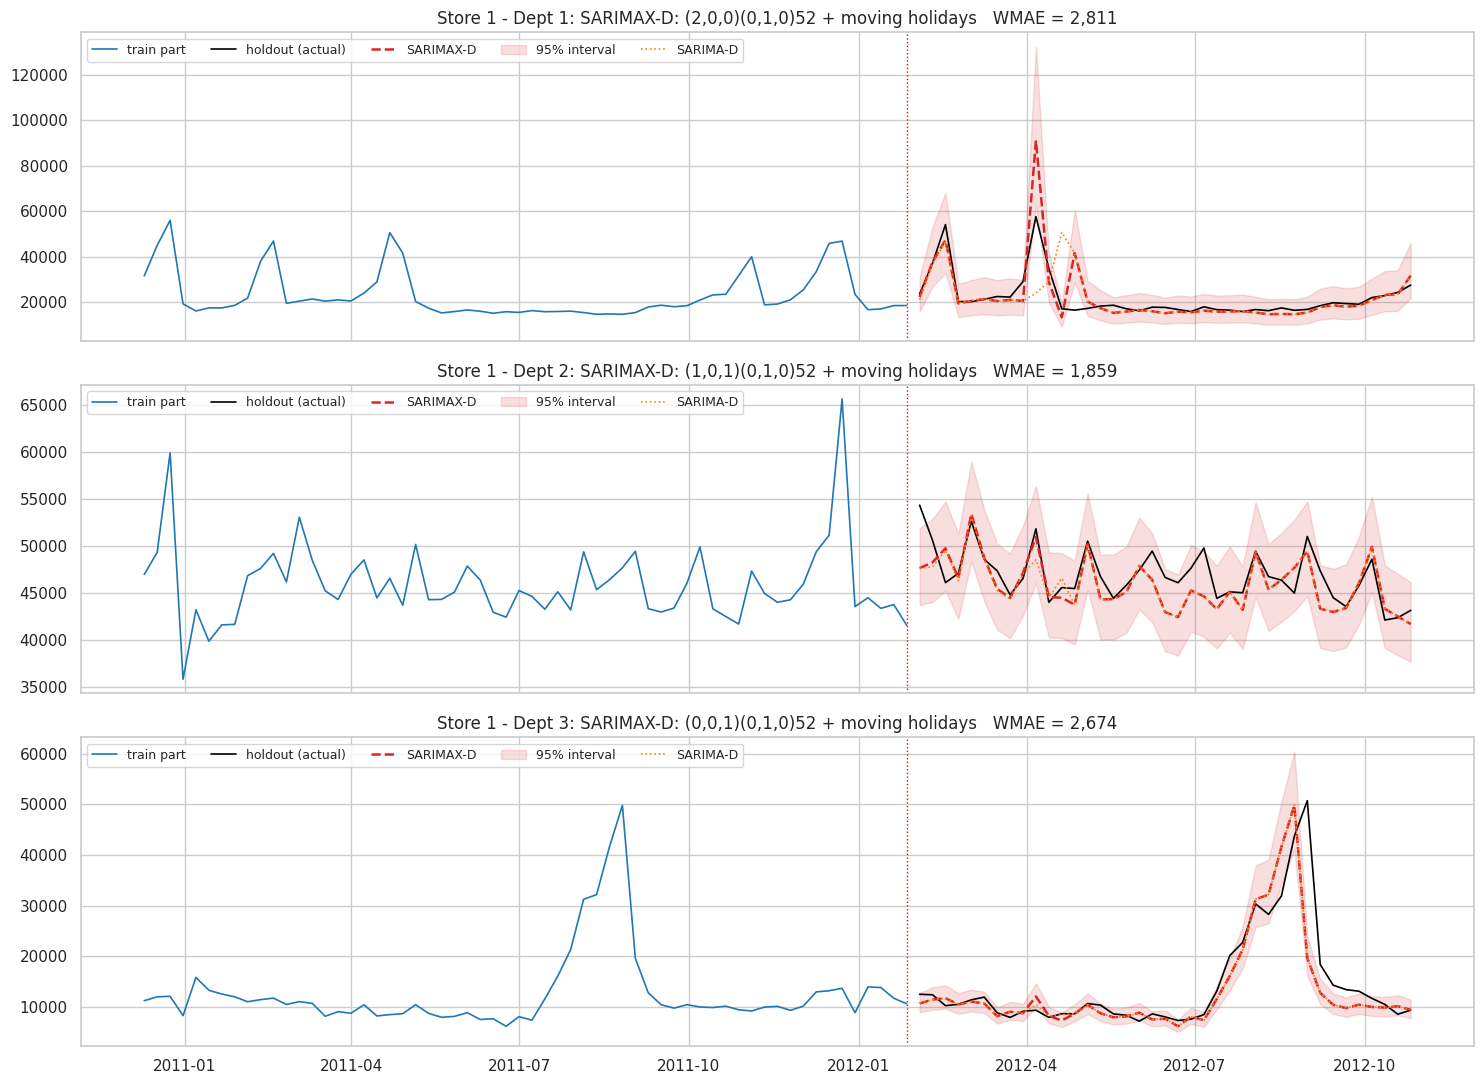

Estimated effect of the moving holidays (on top of last year's copy):


beta (log)  effect %  p-value
Dept flag                                         
1    valentine_week       0.206      22.9    0.750
     easter_week          1.340     282.0    0.000
     halloween_week       0.166      18.1    0.896
2    valentine_week      -0.030      -2.9    0.117
     easter_week          0.047       4.8    0.571
     halloween_week       0.035       3.6    0.544
3    valentine_week      -0.056      -5.4    0.475
     easter_week          0.147      15.8    0.009
     halloween_week      -0.013      -1.2    0.881

In [20]:
sarimax_d_store1 = {}
coef_rows = []
fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)
for ax, dept in zip(axes, DEPTS):
    train_part, holdout = store1_series[dept]
    y_log = np.log(train_part["Weekly_Sales"].values)
    w = y_log[52:] - y_log[:-52]

    # differenced dummies: this week's flag - the flag of the same week last year
    x_hist = train_part[MOVING_FLAGS].values.astype(float)
    x_future = holdout[MOVING_FLAGS].values.astype(float)
    wx = pd.DataFrame(x_hist[52:] - x_hist[:-52], columns=MOVING_FLAGS)
    wx_future = pd.DataFrame(x_future - x_hist[-52:][:H], columns=MOVING_FLAGS)
    keep = [f for f in MOVING_FLAGS if wx[f].abs().sum() > 0]      # flags that really moved inside the history

    best = None
    for p, q, trend in itertools.product([0, 1, 2], [0, 1], ["n", "c"]):
        res = SARIMAX(pd.Series(w), exog=wx[keep], order=(p, 0, q), trend=trend).fit(disp=False)
        if best is None or res.aicc < best[1].aicc:
            best = ((p, q, trend), res)
    (p, q, trend), res = best

    fc = res.get_forecast(steps=H, exog=wx_future[keep])
    last_year = y_log[-52:][:H]
    forecast = np.exp(last_year + np.asarray(fc.predicted_mean))
    ci = np.asarray(fc.conf_int(alpha=0.05))
    store1_forecasts[dept]["SARIMAX-D"] = forecast
    sarimax_d_store1[dept] = {"key": (p, q, trend), "res": res, "flags": keep}

    for f in keep:                                               # effect of each moving holiday
        beta = res.params[f]
        coef_rows.append({"Dept": dept, "flag": f, "beta (log)": round(beta, 3), "effect %": round((np.exp(beta) - 1) * 100, 1),
                          "p-value": round(res.pvalues[f], 3)})

    name = f"SARIMAX-D: ({p},0,{q})(0,1,0)52{' + drift' if trend == 'c' else ''} + moving holidays"
    plot_forecast(ax, train_part, holdout, forecast, np.exp(last_year + ci[:, 0]), np.exp(last_year + ci[:, 1]), label="SARIMAX-D", color="tab:red")
    ax.plot(holdout["Date"], store1_forecasts[dept]["SARIMA-D"], color="tab:orange", linestyle=":", linewidth=1.2, label="SARIMA-D")
    ax.set_title(f"Store {FOCUS_STORE} - Dept {dept}: {name}   WMAE = {wmae(holdout['Weekly_Sales'], forecast, holdout['is_holiday']):,.0f}")
    ax.legend(loc="upper left", ncol=5, fontsize=9)
plt.tight_layout()
plt.show()

print("Estimated effect of the moving holidays (on top of last year's copy):")
pd.DataFrame(coef_rows).set_index(["Dept", "flag"])

**What I see**

| Dept | ARMA part | Easter | Valentine's | Halloween | WMAE: SARIMA-D → SARIMAX-D |
|---|---|---|---|---|---|
| 1 | (2,0,0) | **+282%** (p < 0.001) | +23% (p = 0.75) | +18% (p = 0.90) | 3,431 → **2,811** (−18%) |
| 2 | (1,0,1) | +5% (p = 0.57) | −3% (p = 0.12) | +4% (p = 0.54) | 1,959 → **1,859** (−5%) |
| 3 | (0,0,1) | **+16%** (p = 0.009) | −5% (p = 0.48) | −1% (p = 0.88) | 2,613 → 2,674 (+2%) |

- **Dept 1: the Easter peak is now in the right week** (6 April 2012). That's the whole point of the differenced dummy: it **adds** the effect where Easter is this year (+1) and **removes** it where Easter was last year (−1).
- **But the peak is too high:** 91.2k forecast vs 57.6k actual. The arithmetic: same week last year (8 April 2011, 23.9k) × $e^{1.34}$ (= 3.82) ≈ 91k. Two reasons:
  1. **The effect is learned from only two "swaps"** among the 52 yearly changes: Easter 2011 vs a normal week of 2010, and Easter 2010 vs a normal week of 2011. A p-value below 0.001 means *"the effect is not 0"*, not *"the effect is precisely +282%"*.
  2. **The base week wasn't a normal week:** 8 April 2011 was already two weeks into the 2011 pre-Easter build-up, so the model multiplies a week that was already high. (In 2012 the real ratio was 57.6 / 23.9 = 2.4, i.e. +141%.)
- **20 April is fixed** (13.2k vs 17.0k actual), **but a ghost remains on 27 April** (41.5k vs 16.3k). Why? **Easter lasts two weeks in the data:** the flagged week (ending on Good Friday) *and* the next one, which contains Easter Saturday and Sunday: 43.0k in 2010, 41.5k in 2011, 34.7k in 2012, against about 17–21k for a normal week. Our dummy only marks the first week, so the second week of Easter 2011 is still copied.
- **Dept 3:** a small but significant Easter effect (+16%), which adds a bump on 6 April (12.1k vs 9.3k actual) → slightly worse than SARIMA-D.
- **Dept 2:** no significant holiday effect. The small gain comes from a different ARMA order, chosen with the dummies in the model.
- **Valentine's and Halloween are not significant**: in the training pairs they moved by only one week, and their peaks spread over two weeks, so these one-week swaps carry little information.

**In plain words:** SARIMAX-D = *"copy last year, then move the holiday peaks to this year's dates"*. It fixes **where** the Easter peak goes, not **how big** it is, because the size is learned from one or two occurrences.

## 2.6 SARIMAX-F: Fourier terms + holiday dummies + ARMA errors

### First, an intuition for Fourier terms

Left: the first 3 pairs of waves (1, 2 and 3 cycles per year). Right: Store 1 – Dept 3 (log, train part) approximated with **only** Fourier terms (plain least squares, no ARMA, no dummies) for $K = 1, 3, 10$. More waves → more detail.

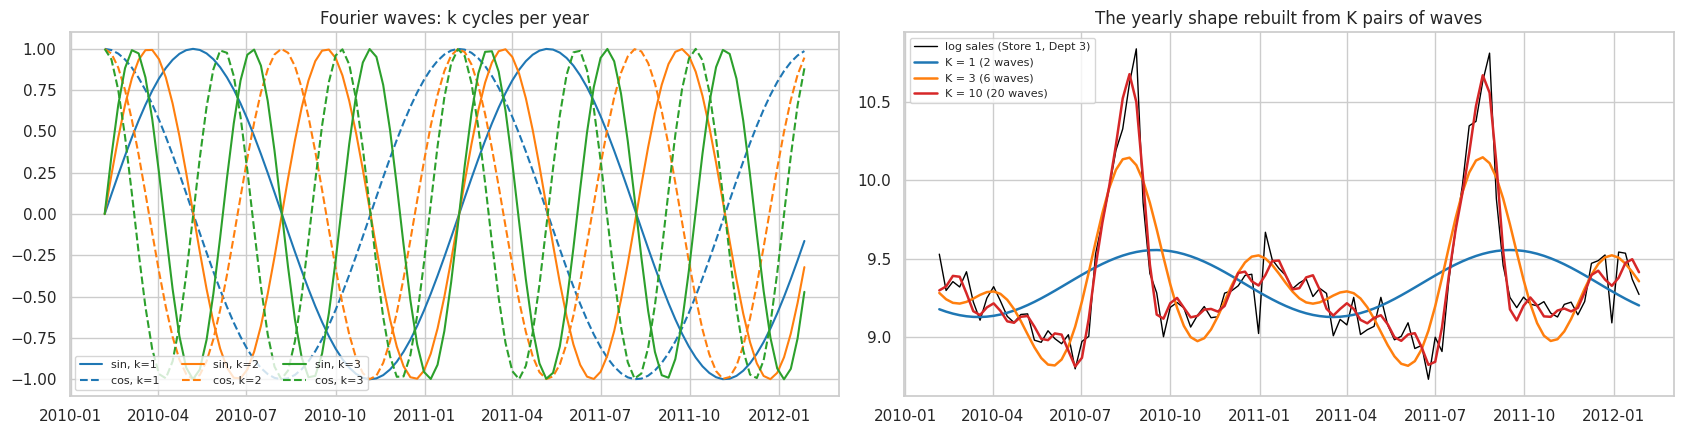

In [21]:
train_part, holdout = store1_series[3]
t_train = train_part["t"].values
y_log = np.log(train_part["Weekly_Sales"].values)

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
basis = fourier_terms(t_train, 3)
for k, color in zip([1, 2, 3], ["tab:blue", "tab:orange", "tab:green"]):
    axes[0].plot(train_part["Date"], basis[f"sin{k}"], color=color, label=f"sin, k={k}")
    axes[0].plot(train_part["Date"], basis[f"cos{k}"], color=color, linestyle="--", label=f"cos, k={k}")
axes[0].set_title("Fourier waves: k cycles per year")
axes[0].legend(ncol=3, fontsize=8, loc="lower left")

axes[1].plot(train_part["Date"], y_log, color="black", linewidth=1, label="log sales (Store 1, Dept 3)")
for K, color in zip([1, 3, 10], ["tab:blue", "tab:orange", "tab:red"]):
    X = np.column_stack([np.ones(len(t_train)), fourier_terms(t_train, K).values])   # constant + 2K waves
    coef, *_ = np.linalg.lstsq(X, y_log, rcond=None)                                 # ordinary least squares
    axes[1].plot(train_part["Date"], X @ coef, color=color, linewidth=1.8, label=f"K = {K} ({2 * K} waves)")
axes[1].set_title("The yearly shape rebuilt from K pairs of waves")
axes[1].legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

**What I see**

- **Left:** the waves themselves. $k = 1$ makes one up-and-down per year, $k = 2$ two, $k = 3$ three. A sine and a cosine of the same speed are shifted by a quarter of a cycle; with both, the regression can place a bump **anywhere** in the year.
- **Right:** Dept 3 (log sales, train part) rebuilt with $K$ pairs of waves (plain least squares):
  - $K = 1$: a gentle summer high / winter low. It completely misses the August peak (about 9.55 vs 10.8 at the top).
  - $K = 3$: a rounded hump in August–September, too low and too wide, plus small artificial waves in spring.
  - $K = 10$: follows the August peak almost exactly, and even the January bump.
- The curve is **the same in both years**: Fourier terms describe the **typical** year. They can't follow a peak that moved (that's the dummies' job), and they don't copy last year's random noise (that's their advantage over seasonal naive).

**Why not always use a big $K$?** Each pair costs 2 coefficients. With $K = 10$, 8 holiday dummies and an ARMA, the model has about 30 parameters for 104 weeks: it starts to draw the noise of these two particular years instead of the typical shape. AICc decides how far to go (next cell).

### Step 2: Estimate. Choose K, then the ARMA orders

1. For $K = 1, \dots, 10$: fit Fourier($K$) + all 8 holiday dummies, with AR(1) errors, and keep the $K$ with the lowest AICc.
2. With that $K$, try ARMA(p, q) errors with $p \in \{0,1,2\}$, $q \in \{0,1\}$, and keep the lowest AICc.

This two-step search is the usual practical shortcut (Hyndman & Athanasopoulos): it avoids fitting 60 models per series.

Dept 1: K = 8, errors ARMA(0, 0)


Dept 2: K = 1, errors ARMA(0, 1)


Dept 3: K = 6, errors ARMA(0, 0)


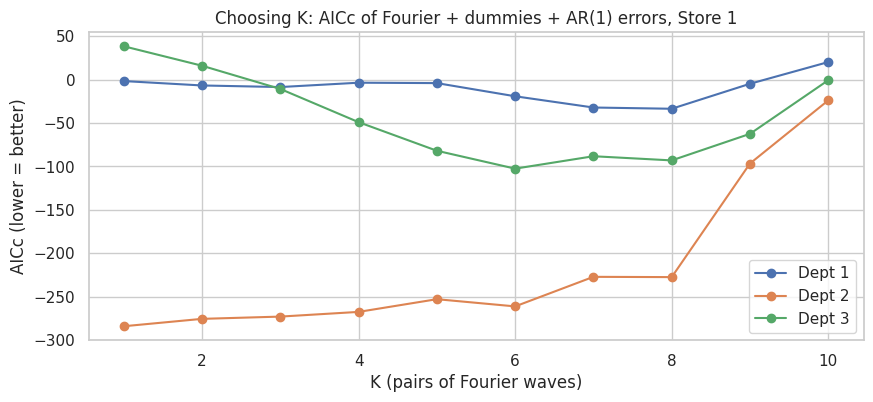

In [22]:
sarimax_f_store1 = {}
K_curves = {}
for dept in DEPTS:
    train_part, holdout = store1_series[dept]
    y_log = pd.Series(np.log(train_part["Weekly_Sales"].values))
    dummies = train_part[ALL_FLAGS].reset_index(drop=True)

    # step 1: choose K
    aicc_by_K = {}
    for K in range(1, 11):
        X = pd.concat([fourier_terms(train_part["t"], K), dummies], axis=1)
        aicc_by_K[K] = SARIMAX(y_log, exog=X, order=(1, 0, 0), trend="c").fit(disp=False).aicc
    K_best = min(aicc_by_K, key=aicc_by_K.get)
    K_curves[dept] = aicc_by_K

    # step 2: choose the ARMA orders of the errors
    X = pd.concat([fourier_terms(train_part["t"], K_best), dummies], axis=1)
    best = None
    for p, q in itertools.product([0, 1, 2], [0, 1]):
        res = SARIMAX(y_log, exog=X, order=(p, 0, q), trend="c").fit(disp=False)
        if best is None or res.aicc < best[1].aicc:
            best = ((p, q), res)
    sarimax_f_store1[dept] = {"K": K_best, "order": best[0], "res": best[1]}
    print(f"Dept {dept}: K = {K_best}, errors ARMA{best[0]}")

plt.figure(figsize=(10, 4))
for dept in DEPTS:
    plt.plot(list(K_curves[dept].keys()), list(K_curves[dept].values()), marker="o", label=f"Dept {dept}")
plt.xlabel("K (pairs of Fourier waves)")
plt.ylabel("AICc (lower = better)")
plt.title("Choosing K: AICc of Fourier + dummies + AR(1) errors, Store 1")
plt.legend()
plt.show()

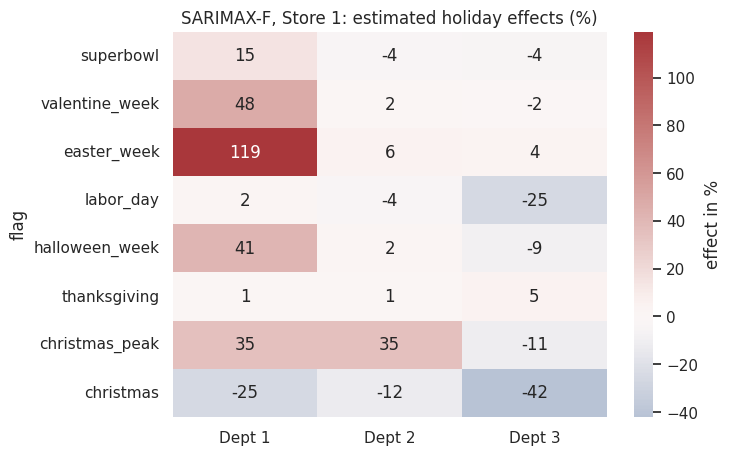

In [23]:
# the estimated holiday effects (dummies), in % on top of the smooth yearly curve
coef_rows = []
for dept in DEPTS:
    res = sarimax_f_store1[dept]["res"]
    for f in ALL_FLAGS:
        beta = res.params[f]
        coef_rows.append({"Dept": dept, "flag": f, "effect %": round((np.exp(beta) - 1) * 100, 1), "p-value": round(res.pvalues[f], 3)})
holiday_effects = pd.DataFrame(coef_rows).pivot(index="flag", columns="Dept", values="effect %").loc[ALL_FLAGS]
holiday_effects.columns = [f"Dept {d}" for d in DEPTS]

plt.figure(figsize=(7, 5))
sns.heatmap(holiday_effects, annot=True, fmt=".0f", cmap="vlag", center=0, cbar_kws={"label": "effect in %"})
plt.title("SARIMAX-F, Store 1: estimated holiday effects (%)")
plt.show()

**Choosing $K$ (line plot)**

- **Dept 1:** AICc keeps improving until $K = 8$, then gets much worse at $K = 9$ and 10: beyond 8 pairs, extra waves cost more than they explain.
- **Dept 2:** best at $K = 1$, and every extra pair makes AICc worse. **Dept 2 has almost no yearly shape** apart from Christmas, which the `christmas_peak` dummy already handles.
- **Dept 3:** best at $K = 6$: enough waves to draw the August peak.
- The chosen error models are simple: white noise (ARMA(0,0)) for Depts 1 and 3, MA(1) for Dept 2. Once the shape of the year and the holidays are explained, little short-term structure is left.

**Holiday effects (heatmap), in % on top of the smooth yearly curve**

- **Dept 1 reacts to every "gift / candy" occasion:** Easter **+119%**, Valentine's **+48%**, Halloween **+41%**, the week before Christmas **+35%**, Super Bowl +15%. The flagged Christmas week is **−25%**: it starts on 25 December, after the shopping is done (EDA F.2). It looks like a seasonal / candy / cards kind of department (the data are anonymised, so that's a guess).
- **Dept 2:** only the Christmas season matters: +35% the week before Christmas, −12% the Christmas week.
- **Dept 3:** no positive holiday effect. Christmas week −42%, and **Labor Day −25%**. This Labor Day "effect" is mostly a **correction of the smooth curve**: Labor Day falls right after the August peak, where sales collapse faster than smooth waves can follow, and the dummy fills the gap.

**Two lessons**
1. A coefficient's meaning depends on the other regressors: dummies and Fourier terms work as a team.
2. These numbers are **not comparable** with the +282% of SARIMAX-D. SARIMAX-F measures Easter against the smooth April level of the curve and uses **both** Easters of the train part (2010 and 2011), because without differencing no year of data is lost. SARIMAX-D measures it against "same week last year", from the swaps only.

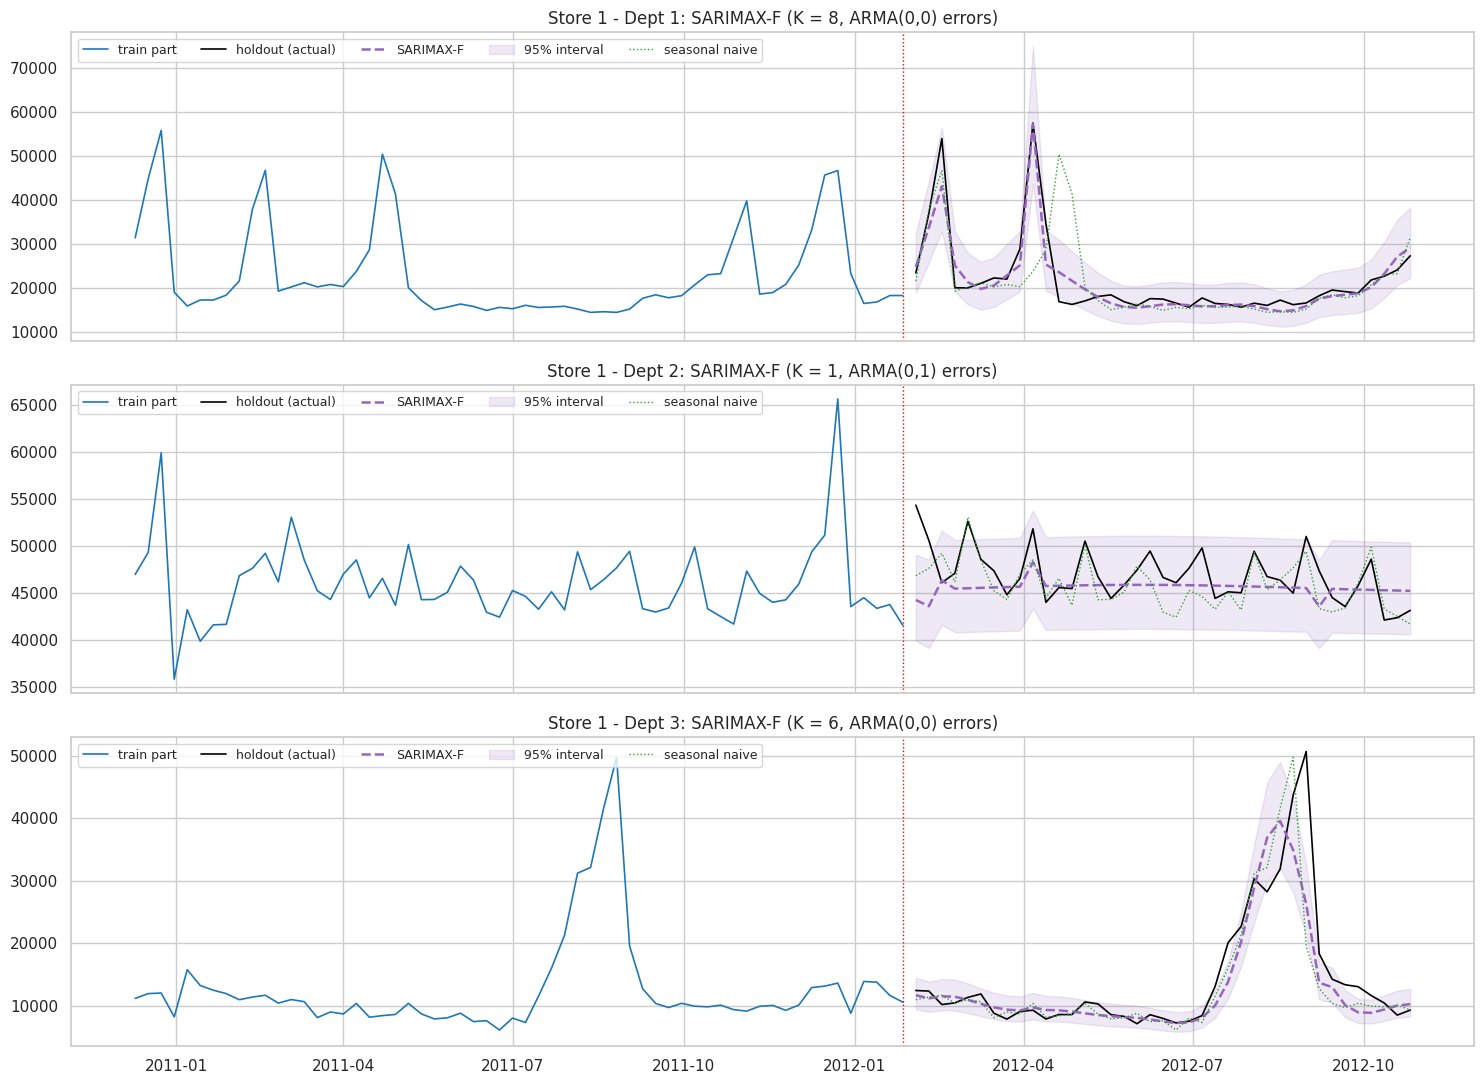

,model,Ljung-Box p (lag 10),WMAE
Dept,,,
1,"Fourier K=8 + 8 dummies + ARMA(0,0) errors",0.472,2032
2,"Fourier K=1 + 8 dummies + ARMA(0,1) errors",0.000,2837
3,"Fourier K=6 + 8 dummies + ARMA(0,0) errors",0.001,2637


In [24]:
rows = []
fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)
for ax, dept in zip(axes, DEPTS):
    train_part, holdout = store1_series[dept]
    K, (p, q), res = sarimax_f_store1[dept]["K"], sarimax_f_store1[dept]["order"], sarimax_f_store1[dept]["res"]

    X_future = pd.concat([fourier_terms(holdout["t"], K), holdout[ALL_FLAGS].reset_index(drop=True)], axis=1)
    fc = res.get_forecast(steps=H, exog=X_future)            # the future Fourier terms and dummies are known in advance
    forecast = np.exp(np.asarray(fc.predicted_mean))
    ci = np.asarray(fc.conf_int(alpha=0.05))
    store1_forecasts[dept]["SARIMAX-F"] = forecast

    rows.append({"Dept": dept, "model": f"Fourier K={K} + 8 dummies + ARMA({p},{q}) errors",
                 "Ljung-Box p (lag 10)": round(ljung_box_p(res.resid, n_params=p + q), 3),
                 "WMAE": round(wmae(holdout["Weekly_Sales"], forecast, holdout["is_holiday"]))})
    plot_forecast(ax, train_part, holdout, forecast, np.exp(ci[:, 0]), np.exp(ci[:, 1]), label="SARIMAX-F", color="tab:purple")
    ax.plot(holdout["Date"], store1_forecasts[dept]["seasonal naive"], color="tab:green", linestyle=":", linewidth=1, label="seasonal naive")
    ax.set_title(f"Store {FOCUS_STORE} - Dept {dept}: SARIMAX-F (K = {K}, ARMA({p},{q}) errors)")
    ax.legend(loc="upper left", ncol=5, fontsize=9)
plt.tight_layout()
plt.show()
pd.DataFrame(rows).set_index("Dept")

**What I see**

- **Dept 1 ($K = 8$, white-noise errors, Ljung–Box p = 0.47): the best Store 1 forecast so far, WMAE 2,032 (−42% vs seasonal naive).**
  - Easter 2012: 57.3k forecast vs 57.6k actual, in the right week, and **no ghost** in late April.
  - Its weaknesses are softer: Valentine's is under-forecast (43.2k vs 54.1k), and after Easter the forecast comes down slowly (23.7k and 21.7k on 20 and 27 April vs about 17k actual), because the smooth curve keeps a little of the 2010 and 2011 Easters in April.
- **Dept 2 ($K = 1$, MA(1) errors, Ljung–Box p = 0.000): worse than seasonal naive** (2,837 vs 1,990). The forecast is almost flat (about 45.5k), while the actual sales go up and down every few weeks, and **seasonal naive gets many of these ups and downs right**. Why? Dept 2 has a **monthly rhythm**: in Store 1, the week that contains the 1st of the month is on average **+6%** above the surrounding weeks (+2% across all Dept 2 stores; a likely reason is paydays and monthly benefits). A copy of last year keeps that rhythm (52 weeks = 364 days, so the same week sits at almost the same place in the month), but a yearly Fourier curve would need about 12 cycles per year to draw it. The rhythm stays in the residuals (significant autocorrelation around lags 6–7), hence Ljung–Box p = 0.000.
- **Dept 3 ($K = 6$, white-noise errors, p = 0.001): about as good as seasonal naive** (2,637 vs 2,607). The August peak is smoothed (about 40k at the top vs 50.7k actual) and placed too early, because the curve averages the 2010 and 2011 peaks.

**In plain words:** SARIMAX-F is excellent when the year is *"a smooth shape + holiday spikes"* (Dept 1), and weaker when the series has fine regular detail (Dept 2's monthly rhythm) or a very sharp peak (Dept 3). It is the **mirror image** of SARIMAX-D: SARIMAX-D is sharp but copies last year's accidents; SARIMAX-F is smooth but misses fine detail. That's the argument for combining them (next section).

## 2.7 Combination (teammate's Note 6)

The teammate noted that "no single model will win everywhere", which is an argument for **forecast combination**. The simplest version is the average of two forecasts that see the data differently:
- **SARIMAX-D** copies last year (with the holiday correction): sharp, but carries last year's noise.
- **SARIMAX-F** draws a smooth typical year: no copied noise, but softer peaks.

Their errors are partly independent, so the average often beats both.

In [25]:
for dept in DEPTS:
    store1_forecasts[dept]["Combination"] = (store1_forecasts[dept]["SARIMAX-D"] + store1_forecasts[dept]["SARIMAX-F"]) / 2
print("combination added for", DEPTS)

combination added for [1, 2, 3]


## 2.8 Store 1: all models side by side

In [26]:
MODEL_ORDER = ["naive", "mean", "seasonal naive", "ARIMA", "SARIMA-D", "SARIMA-AR", "SARIMAX-D", "SARIMAX-F", "Combination"]

store1_wmae = pd.DataFrame({f"Dept {dept}": {m: wmae(store1_series[dept][1]["Weekly_Sales"], store1_forecasts[dept][m],
                                                      store1_series[dept][1]["is_holiday"]) for m in MODEL_ORDER}
                            for dept in DEPTS})
store1_wmae["mean of 3 depts"] = store1_wmae.mean(axis=1)
store1_relative = store1_wmae.div(store1_wmae.loc["seasonal naive"], axis=1)

print("WMAE in $ (lower = better):")
print(store1_wmae.round(0))
print("\nRelative to seasonal naive (< 1 = better than 'same week last year'):")
store1_relative.round(2)

WMAE in $ (lower = better):
                Dept 1  Dept 2  Dept 3  mean of 3 depts
naive           5748.0  5703.0  5457.0           5636.0
mean            6847.0  2390.0  5546.0           4928.0
seasonal naive  3486.0  1990.0  2607.0           2695.0
ARIMA           6382.0  2442.0  5557.0           4794.0
SARIMA-D        3431.0  1959.0  2613.0           2668.0
SARIMA-AR       4062.0  1957.0  2596.0           2871.0
SARIMAX-D       2811.0  1859.0  2674.0           2448.0
SARIMAX-F       2032.0  2837.0  2637.0           2502.0
Combination     2163.0  2157.0  2469.0           2263.0

Relative to seasonal naive (< 1 = better than 'same week last year'):


,Dept 1,Dept 2,Dept 3,mean of 3 depts
naive,1.65,2.87,2.09,2.09
mean,1.96,1.20,2.13,1.83
seasonal naive,1.00,1.00,1.00,1.00
ARIMA,1.83,1.23,2.13,1.78
SARIMA-D,0.98,0.98,1.00,0.99
SARIMA-AR,1.17,0.98,1.00,1.07
SARIMAX-D,0.81,0.93,1.03,0.91
SARIMAX-F,0.58,1.43,1.01,0.93
Combination,0.62,1.08,0.95,0.84


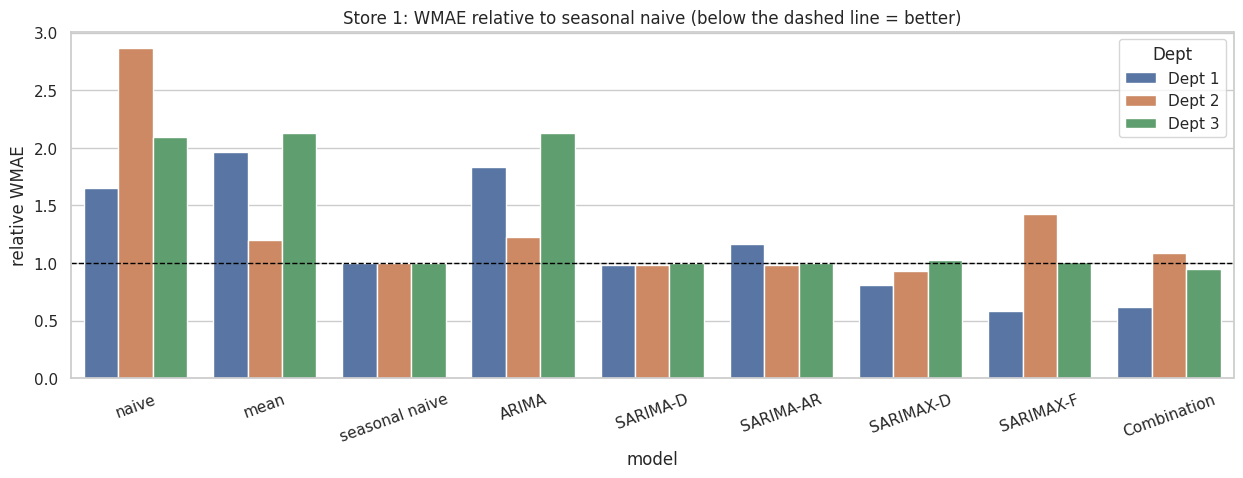

In [27]:
plot_data = store1_relative.drop(columns="mean of 3 depts").reset_index().melt(id_vars="index", var_name="Dept", value_name="relative WMAE")
plot_data = plot_data.rename(columns={"index": "model"})

plt.figure(figsize=(15, 4.5))
sns.barplot(data=plot_data, x="model", y="relative WMAE", hue="Dept", order=MODEL_ORDER)
plt.axhline(1, color="black", linestyle="--", linewidth=1)
plt.title("Store 1: WMAE relative to seasonal naive (below the dashed line = better)")
plt.xticks(rotation=20)
plt.show()

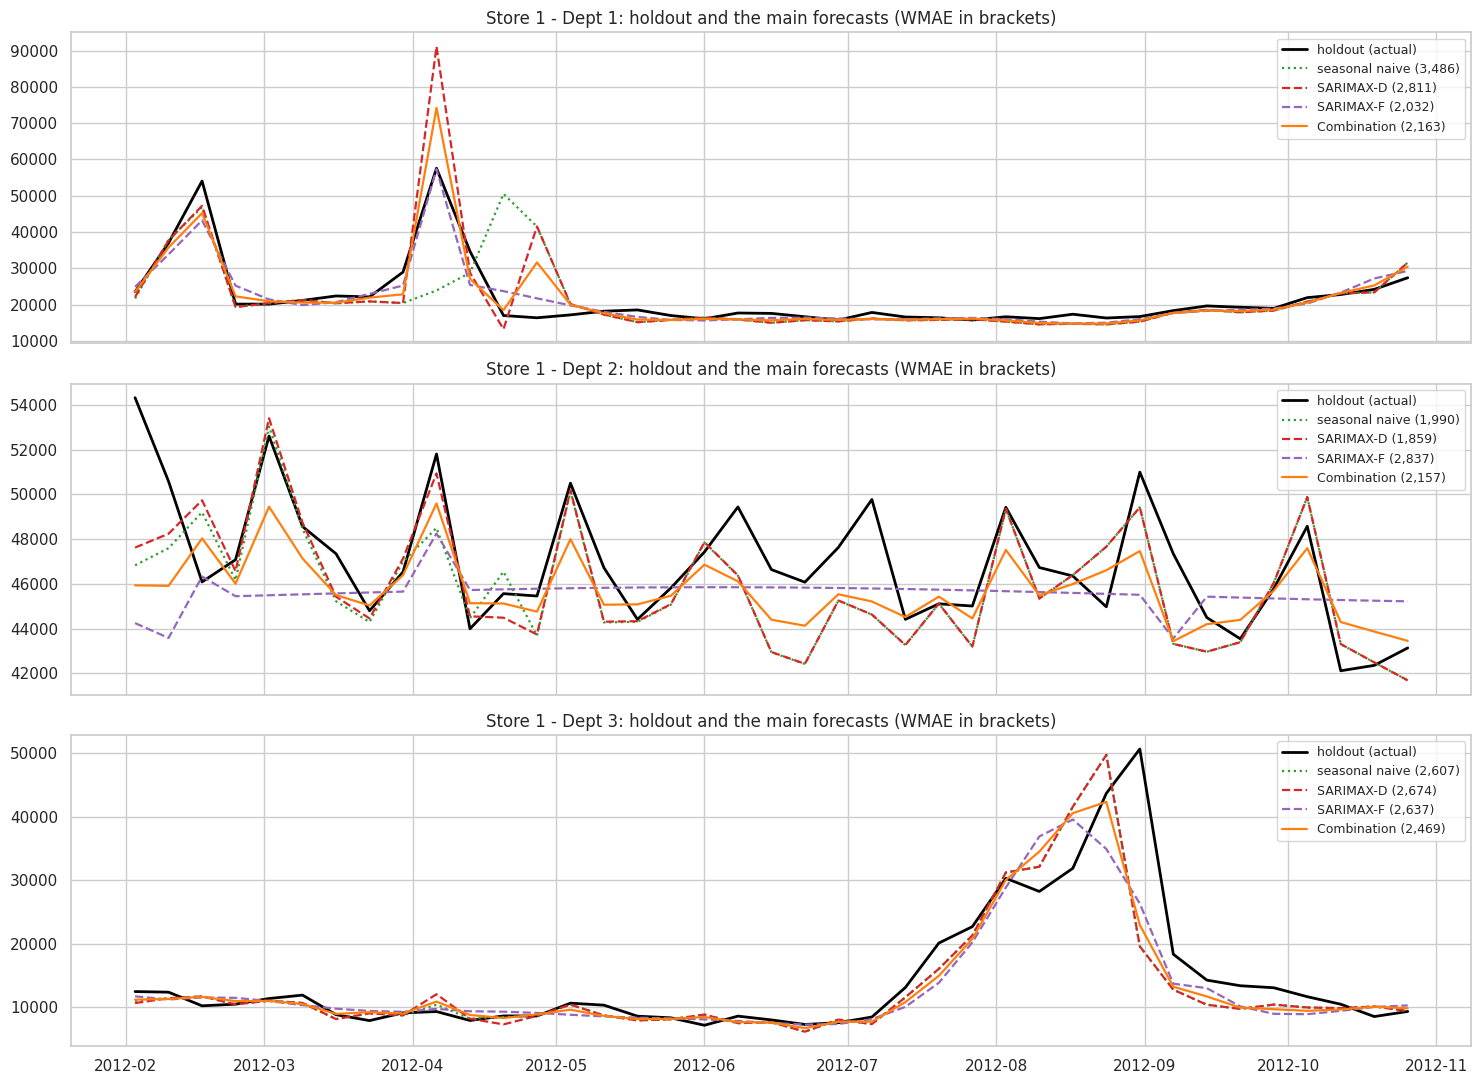

In [28]:
fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)
styles = {"seasonal naive": ("tab:green", ":"), "SARIMAX-D": ("tab:red", "--"), "SARIMAX-F": ("tab:purple", "--"), "Combination": ("tab:orange", "-")}
for ax, dept in zip(axes, DEPTS):
    train_part, holdout = store1_series[dept]
    ax.plot(holdout["Date"], holdout["Weekly_Sales"], color="black", linewidth=2, label="holdout (actual)")
    for m, (color, ls) in styles.items():
        ax.plot(holdout["Date"], store1_forecasts[dept][m], color=color, linestyle=ls, linewidth=1.6,
                label=f"{m} ({store1_wmae.loc[m, f'Dept {dept}']:,.0f})")
    ax.set_title(f"Store {FOCUS_STORE} - Dept {dept}: holdout and the main forecasts (WMAE in brackets)")
    ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

**What I see (Store 1, 3 series)**

| | Dept 1 | Dept 2 | Dept 3 | mean of the 3 |
|---|---|---|---|---|
| best model | SARIMAX-F | SARIMAX-D | Combination | **Combination** |
| its WMAE (relative to seasonal naive) | 2,032 (0.58) | 1,859 (0.93) | 2,469 (0.95) | **2,263 (0.84)** |

- **No single model wins all three departments**, and each winner is the one the previous sections explained: the smooth curve for the holiday-driven Dept 1, the copy for Dept 2's fine rhythm, the average for Dept 3.
- **The Combination is never far from the best** (relative 0.62 / 1.08 / 0.95) and is the best on the average of the three departments: 16% better than seasonal naive.
- **The bottom plot shows why averaging works.** At Easter (Dept 1, 6 April) SARIMAX-D says 91.2k, SARIMAX-F 57.3k, and their average 74.2k: the overshoot is halved. On the ghost week of 27 April: 41.5k and 21.7k → 31.6k. When two models err in opposite directions, the average cancels part of the errors.
- **Dept 3's peak week is lost by everybody:** on 31 August 2012 the actual is 50.7k and the forecasts are 19.6k (SARIMAX-D), 26.3k (SARIMAX-F) and 23.0k (Combination). All models put the drop one week too early, so the next week (Labor Day, weight 5) is too low as well. These two weeks alone make **46%** of the Combination's weighted error for Dept 3. No calendar variable tells us when schools reopen.
- **Ranking (mean of the 3 depts, relative WMAE):** Combination 0.84 < SARIMAX-D 0.91 < SARIMAX-F 0.93 < SARIMA-D 0.99 < seasonal naive 1.00 < SARIMA-AR 1.07 < ARIMA 1.78 < mean 1.83 < naive 2.09.

**Caution:** Store 1 is only 3 series. Part 3 checks whether the same picture holds for all 135.

# Part 3 — All 135 series

## 3.1 One function for the whole pipeline

Everything done by hand for Store 1 is now packed into **one function**, `run_models(hist, future)`:
- `hist`: the weeks used to fit (sales, week counter `t`, holiday flags),
- `future`: the weeks to forecast (`t` and flags only, since they're known in advance).

It applies **exactly the same selection rules** as Part 2 (same candidate orders, AICc, same dummies). Because it only needs `hist` and `future`, the same function serves for the holdout evaluation (104 weeks → 39) **and** for the final forecast of `test.csv` (143 weeks → 39, Part 4).

If one model fails to fit for a series (it can happen with numerical optimisation), the function falls back to the seasonal naive forecast for that model and records it.

In [29]:
ALL_MODELS = ["naive", "mean", "seasonal naive", "ARIMA", "SARIMA-D", "SARIMA-AR", "SARIMAX-D", "SARIMAX-F", "Combination"]


def run_models(hist, future, models=ALL_MODELS):
    # Fit the requested models on `hist` and forecast every row of `future`.
    # Returns forecasts = {model name: array in $} and info = {chosen settings, diagnostics}.
    y = hist["Weekly_Sales"].values
    y_log = np.log(y)
    n_future = len(future)
    last_year = y_log[-52:][:n_future]            # log sales of the same weeks one year earlier
    w = y_log[52:] - y_log[:-52]                  # yearly changes (for the D = 1 models)
    forecasts, info = {}, {}

    # --- 0. baselines ---
    forecasts["naive"] = np.repeat(y[-1], n_future)
    forecasts["mean"] = np.repeat(y.mean(), n_future)
    forecasts["seasonal naive"] = y[-52:][:n_future]

    # --- 1. ARIMA(p,0,q) + constant, p,q in {0,1,2} ---
    if "ARIMA" in models:
        try:
            best = None
            for p, q in itertools.product([0, 1, 2], [0, 1, 2]):
                res = SARIMAX(y_log, order=(p, 0, q), trend="c").fit(disp=False)
                if best is None or res.aicc < best[1].aicc:
                    best = ((p, q), res)
            (p, q), res = best
            forecasts["ARIMA"] = np.exp(res.forecast(n_future))
            info["ARIMA order"] = f"({p},0,{q})"
            info["LB p ARIMA"] = ljung_box_p(res.resid, n_params=p + q)
        except Exception:
            forecasts["ARIMA"] = forecasts["seasonal naive"]; info["ARIMA failed"] = True

    # --- 2. SARIMA-D: ARMA(p,q) [+ drift] on the yearly change ---
    if "SARIMA-D" in models:
        try:
            best = None
            for p, q, trend in itertools.product([0, 1, 2], [0, 1], ["n", "c"]):
                res = SARIMAX(w, order=(p, 0, q), trend=trend).fit(disp=False)
                if best is None or res.aicc < best[1].aicc:
                    best = ((p, q, trend), res)
            (p, q, trend), res = best
            forecasts["SARIMA-D"] = np.exp(last_year + res.forecast(n_future))
            info["SARIMA-D order"] = f"({p},0,{q})(0,1,0)52" + (" + drift" if trend == "c" else "")
            info["LB p SARIMA-D"] = ljung_box_p(res.resid, n_params=p + q)
        except Exception:
            forecasts["SARIMA-D"] = forecasts["seasonal naive"]; info["SARIMA-D failed"] = True

    # --- 3. SARIMA-AR: (p,0,0)(1,0,0)52 on the de-meaned log series, p in {0,1} ---
    if "SARIMA-AR" in models:
        try:
            y_mean = y_log.mean()
            best = None
            for p in [0, 1]:
                model = SARIMAX(y_log - y_mean, order=(p, 0, 0), seasonal_order=(1, 0, 0, 52), trend="n")
                model.initialize_approximate_diffuse()
                res = model.fit(disp=False)
                if best is None or res.aicc < best[1].aicc:
                    best = (p, res)
            p, res = best
            forecasts["SARIMA-AR"] = np.exp(res.forecast(n_future) + y_mean)
            info["SARIMA-AR p"] = p
            info["Phi"] = res.params[res.model.param_names.index("ar.S.L52")]
            info["LB p SARIMA-AR"] = ljung_box_p(res.resid[52:], n_params=p + 1)
        except Exception:
            forecasts["SARIMA-AR"] = forecasts["seasonal naive"]; info["SARIMA-AR failed"] = True

    # --- 4. SARIMAX-D: SARIMA-D + differenced moving-holiday dummies ---
    if "SARIMAX-D" in models or "Combination" in models:
        try:
            x_hist = hist[MOVING_FLAGS].values.astype(float)
            x_future = future[MOVING_FLAGS].values.astype(float)
            wx = pd.DataFrame(x_hist[52:] - x_hist[:-52], columns=MOVING_FLAGS)
            wx_future = pd.DataFrame(x_future - x_hist[-52:][:n_future], columns=MOVING_FLAGS)
            keep = [f for f in MOVING_FLAGS if wx[f].abs().sum() > 0]
            best = None
            for p, q, trend in itertools.product([0, 1, 2], [0, 1], ["n", "c"]):
                res = SARIMAX(pd.Series(w), exog=wx[keep], order=(p, 0, q), trend=trend).fit(disp=False)
                if best is None or res.aicc < best[1].aicc:
                    best = ((p, q, trend), res)
            (p, q, trend), res = best
            forecasts["SARIMAX-D"] = np.exp(last_year + np.asarray(res.forecast(n_future, exog=wx_future[keep])))
            info["SARIMAX-D order"] = f"({p},0,{q})(0,1,0)52" + (" + drift" if trend == "c" else "")
            info["easter effect % (SARIMAX-D)"] = (np.exp(res.params["easter_week"]) - 1) * 100 if "easter_week" in keep else np.nan
            info["LB p SARIMAX-D"] = ljung_box_p(res.resid, n_params=p + q)
        except Exception:
            forecasts["SARIMAX-D"] = forecasts["seasonal naive"]; info["SARIMAX-D failed"] = True

    # --- 5. SARIMAX-F: Fourier(K) + all dummies + ARMA(p,q) errors ---
    if "SARIMAX-F" in models or "Combination" in models:
        try:
            y_series = pd.Series(y_log)
            dummies = hist[ALL_FLAGS].reset_index(drop=True)
            dummies_future = future[ALL_FLAGS].reset_index(drop=True)
            aicc_by_K = {}
            for K in range(1, 11):
                X = pd.concat([fourier_terms(hist["t"], K), dummies], axis=1)
                aicc_by_K[K] = SARIMAX(y_series, exog=X, order=(1, 0, 0), trend="c").fit(disp=False).aicc
            K = min(aicc_by_K, key=aicc_by_K.get)
            X = pd.concat([fourier_terms(hist["t"], K), dummies], axis=1)
            X_future = pd.concat([fourier_terms(future["t"], K), dummies_future], axis=1)
            best = None
            for p, q in itertools.product([0, 1, 2], [0, 1]):
                res = SARIMAX(y_series, exog=X, order=(p, 0, q), trend="c").fit(disp=False)
                if best is None or res.aicc < best[1].aicc:
                    best = ((p, q), res)
            (p, q), res = best
            forecasts["SARIMAX-F"] = np.exp(np.asarray(res.forecast(n_future, exog=X_future)))
            info["SARIMAX-F K"] = K
            info["SARIMAX-F errors"] = f"ARMA({p},{q})"
            info["LB p SARIMAX-F"] = ljung_box_p(res.resid, n_params=p + q)
        except Exception:
            forecasts["SARIMAX-F"] = forecasts["seasonal naive"]; info["SARIMAX-F failed"] = True

    # --- 6. combination ---
    if "Combination" in models:
        forecasts["Combination"] = (forecasts["SARIMAX-D"] + forecasts["SARIMAX-F"]) / 2

    return {m: forecasts[m] for m in models}, info

print("run_models ready")

run_models ready


## 3.2 Run it on the 135 series (with a cache)

This loop fits about 50 models per series (≈ 6,700 fits) and takes **about 15–20 minutes**. The results are saved in `results/`, so the next time the notebook runs it just **reloads** them. Set `RERUN = True` to force a new run.

In [30]:
HOLDOUT_FC_FILE = RESULTS_DIR + "holdout_forecasts.csv"        # one row per series x week x model
HOLDOUT_INFO_FILE = RESULTS_DIR + "holdout_model_info.csv"     # one row per series: chosen orders, diagnostics
RERUN = False

if RERUN or not (os.path.exists(HOLDOUT_FC_FILE) and os.path.exists(HOLDOUT_INFO_FILE)):
    forecast_rows, info_rows = [], []
    start = time.time()
    all_pairs = subset[["Store", "Dept"]].drop_duplicates().sort_values(["Dept", "Store"]).values
    for i, (store, dept) in enumerate(all_pairs):
        train_part, holdout = get_series(store, dept)
        forecasts, info = run_models(train_part, holdout)
        for model, f in forecasts.items():
            forecast_rows.append(pd.DataFrame({"Store": store, "Dept": dept, "Date": holdout["Date"].values,
                                               "model": model, "forecast": f}))
        info.update({"Store": store, "Dept": dept})
        info_rows.append(info)
        if i % 15 == 0:
            print(f"{i:3d}/135 series done, {time.time() - start:5.0f} s")
    holdout_forecasts = pd.concat(forecast_rows, ignore_index=True)
    model_info = pd.DataFrame(info_rows)
    holdout_forecasts.to_csv(HOLDOUT_FC_FILE, index=False)
    model_info.to_csv(HOLDOUT_INFO_FILE, index=False)
    print(f"done in {time.time() - start:.0f} s, saved to {RESULTS_DIR}")
else:
    holdout_forecasts = pd.read_csv(HOLDOUT_FC_FILE, parse_dates=["Date"])
    model_info = pd.read_csv(HOLDOUT_INFO_FILE)
    print("loaded cached results from", RESULTS_DIR)

print(holdout_forecasts.shape, model_info.shape)
holdout_forecasts.head()

loaded cached results from results/
(47385, 5) (135, 15)


,Store,Dept,Date,model,forecast
0,1,1,2012-02-03,naive,18378.16
1,1,1,2012-02-10,naive,18378.16
2,1,1,2012-02-17,naive,18378.16
3,1,1,2012-02-24,naive,18378.16
4,1,1,2012-03-02,naive,18378.16


## 3.3 Scoring: WMAE of every model on every series

In [31]:
# join the forecasts with the true holdout sales
actual = subset.loc[subset["split"] == "test", ["Store", "Dept", "Date", "Weekly_Sales", "is_holiday"]]
evaluation = holdout_forecasts.merge(actual, on=["Store", "Dept", "Date"], how="left")
evaluation["weight"] = np.where(evaluation["is_holiday"] == 1, 5, 1)
evaluation["weighted_abs_error"] = evaluation["weight"] * (evaluation["Weekly_Sales"] - evaluation["forecast"]).abs()

# WMAE = sum of weighted errors / sum of weights, per series and model
sums = evaluation.groupby(["Store", "Dept", "model"])[["weighted_abs_error", "weight"]].sum()
series_wmae = (sums["weighted_abs_error"] / sums["weight"]).unstack("model")[ALL_MODELS]     # rows = series, columns = models
print(series_wmae.shape, "-> 135 series x 9 models")
series_wmae.head()

(135, 9) -> 135 series x 9 models


model             naive         mean  seasonal naive        ARIMA     SARIMA-D    SARIMA-AR    SARIMAX-D    SARIMAX-F  Combination
Store Dept                                                                                                                        
1     1     5748.477447  6846.986858     3486.270000  6382.173412  3431.252654  4061.801606  2810.920282  2032.238013  2162.695646
      2     5703.363830  2390.190078     1990.144681  2442.176319  1959.282021  1956.588167  1859.168105  2837.183926  2157.415740
      3     5457.302553  5545.791774     2607.333191  5556.626409  2612.809450  2595.887778  2674.280455  2637.077339  2469.413402
2     1     7847.932128  8551.224939     6816.736383  7744.074293  6651.354334  4850.295701  7151.260488  3421.386600  4936.519757
      2     8586.177872  2598.414472     3018.687234  2749.638633  4389.769076  2519.468381  4511.871753  2098.501381  2994.921654

> **Why the average of the 135 series' WMAE is the "overall" WMAE:** every series has the same 39 weeks with the same holiday weights, so the denominator $\sum w$ is identical for all series, and the pooled WMAE over all 5,265 forecasts equals the plain average of the 135 per-series WMAEs.

In [32]:
mean_wmae = series_wmae.groupby(level="Dept").mean().T              # rows = models, columns = depts
mean_wmae.columns = [f"Dept {d}" for d in mean_wmae.columns]
mean_wmae["all 135 series"] = series_wmae.mean()
mean_wmae["rank"] = mean_wmae["all 135 series"].rank().astype(int)
print("Mean WMAE in $ (lower = better):")
mean_wmae.round(0)

Mean WMAE in $ (lower = better):


,Dept 1,Dept 2,Dept 3,all 135 series,rank
model,,,,,
naive,5099.0,6264.0,5889.0,5751.0,9
mean,5775.0,3238.0,6246.0,5086.0,8
seasonal naive,3907.0,2643.0,1991.0,2847.0,6
ARIMA,5213.0,3394.0,5711.0,4773.0,7
SARIMA-D,4001.0,2445.0,1969.0,2805.0,4
SARIMA-AR,3810.0,2550.0,2138.0,2833.0,5
SARIMAX-D,3376.0,2426.0,2044.0,2615.0,3
SARIMAX-F,2327.0,3235.0,2155.0,2572.0,2
Combination,2455.0,2314.0,1924.0,2231.0,1


In [33]:
relative = series_wmae.div(series_wmae["seasonal naive"], axis=0)      # < 1 = better than seasonal naive
summary_rel = pd.DataFrame({
    "median relative WMAE": relative.median(),
    "% series better than seasonal naive": (relative < 1).mean() * 100,
}).round(2)
by_dept = relative.groupby(level="Dept").median().T.round(2)
by_dept.columns = [f"median rel. Dept {d}" for d in by_dept.columns]
summary_rel.join(by_dept)

,median relative WMAE,% series better than seasonal naive,median rel. Dept 1,median rel. Dept 2,median rel. Dept 3
model,,,,,
naive,1.64,8.89,1.28,2.13,2.51
mean,1.45,13.33,1.49,1.22,2.73
seasonal naive,1.00,0.00,1.00,1.00,1.00
ARIMA,1.38,9.63,1.29,1.29,2.56
SARIMA-D,1.00,52.59,1.00,0.98,1.00
SARIMA-AR,0.99,56.30,0.97,0.97,1.00
SARIMAX-D,0.96,68.15,0.87,0.96,1.00
SARIMAX-F,0.99,51.11,0.63,1.21,1.07
Combination,0.86,81.48,0.64,0.89,0.92


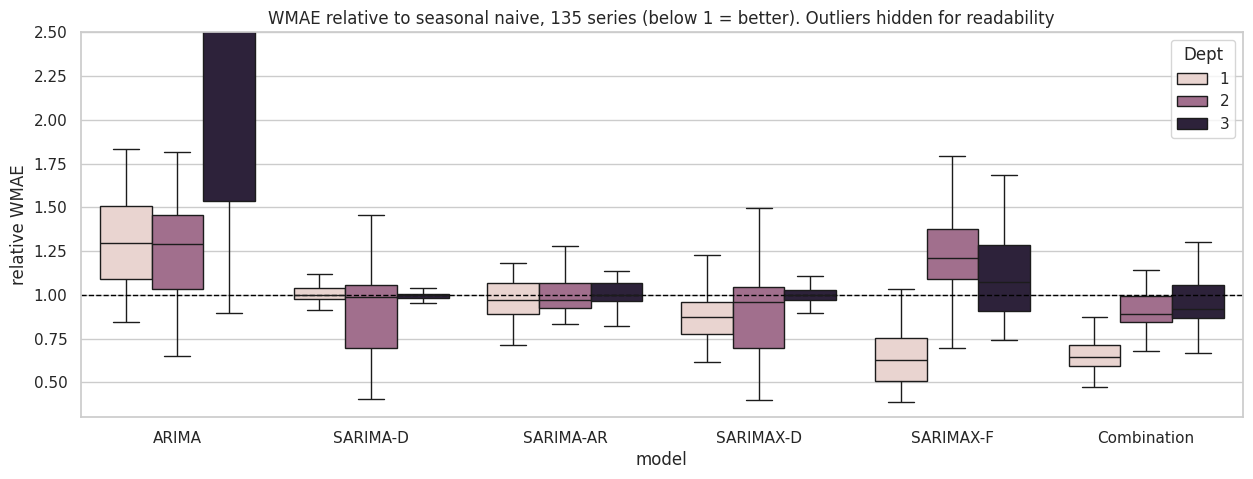

In [34]:
plot_rel = relative.drop(columns=["naive", "mean", "seasonal naive"]).reset_index().melt(
    id_vars=["Store", "Dept"], var_name="model", value_name="relative WMAE")

plt.figure(figsize=(15, 5))
sns.boxplot(data=plot_rel, x="model", y="relative WMAE", hue="Dept", showfliers=False)
plt.axhline(1, color="black", linestyle="--", linewidth=1)
plt.ylim(0.3, 2.5)
plt.title("WMAE relative to seasonal naive, 135 series (below 1 = better). Outliers hidden for readability")
plt.show()

In [35]:
# which model is the best for each series?
best_model = series_wmae.drop(columns=["naive", "mean"]).idxmin(axis=1)
wins = pd.crosstab(best_model.index.get_level_values("Dept"), best_model).reindex(columns=ALL_MODELS[2:], fill_value=0)
wins.index.name = "Dept"
wins["total"] = wins.sum(axis=1)
wins

col_0,seasonal naive,ARIMA,SARIMA-D,SARIMA-AR,SARIMAX-D,SARIMAX-F,Combination,total
Dept,,,,,,,,
1,0,0,3,0,0,28,14,45
2,3,2,6,9,12,4,9,45
3,3,0,6,5,8,7,16,45


**What I see (all 135 series)**

- **The Store 1 ranking holds.** Combination is the best on average: mean WMAE **2,231**, i.e. **−22%** vs seasonal naive, and better than seasonal naive on **81%** of the series. Then SARIMAX-F (2,572), SARIMAX-D (2,615), SARIMA-D (2,805), SARIMA-AR (2,833), seasonal naive (2,847), and far behind ARIMA (4,773), mean (5,086) and naive (5,751).
- **Each department has its own story:**
  - **Dept 1 (holiday-driven):** SARIMAX-F wins 28 of the 45 stores and has the lowest mean WMAE (2,327, −40% vs seasonal naive; median relative 0.63). The Combination wins 14 and beats seasonal naive in **all 45** stores.
  - **Dept 2 (flat, monthly rhythm):** the wins are spread over 7 models. Copy-based models do well (SARIMAX-D 12 wins, SARIMA-AR 9, SARIMA-D 6), while SARIMAX-F is the worst seasonal model (median relative 1.21, better than seasonal naive in only 18% of the stores). The Combination still has the lowest mean (2,314) and beats seasonal naive in 78% of the stores.
  - **Dept 3 (one big peak):** nothing beats seasonal naive by much, except the Combination (median relative 0.92, 16 wins, better than seasonal naive in 67% of the stores).
- **Boxplot:** ARIMA is far above 1 everywhere (Dept 3's box is off the chart, median 2.56). SARIMA-D and SARIMA-AR are squeezed around 1: they are seasonal naive with small corrections. SARIMAX-F has both the best boxes (Dept 1) and the worst (Dept 2). The Combination has the tightest box below 1 in Dept 1 and the lowest medians in Depts 2 and 3.
- **The Combination is rarely the single best (39 of 135 series) but almost never bad.** That's not luck, it's arithmetic: for every week, $|y - \tfrac{a+b}{2}| \le \tfrac{|y-a| + |y-b|}{2}$ (triangle inequality), so the WMAE of the average is **never worse than the average of the two WMAEs**. In practice it beat the worse member in 100% of the series, and both members in 42%.
- Picking the best model for each series **with hindsight** (impossible in practice) would give 1,983. The Combination (2,231) gets most of the way without knowing the answer.
- **Worst Combination series:** Dept 3, stores 35 (relative 1.83), 17 (1.43) and 33 (1.30): series where a copy of last year was already very good and one member went off track (the drift, section 3.4).

**Lesson:** the type of department (holiday-driven, flat, one big peak) predicts which model wins better than any general rule. When you can't know in advance, **combine**: the teammate's Note 6, confirmed on 135 series.

## 3.4 What did the models choose? (chosen orders and diagnostics)

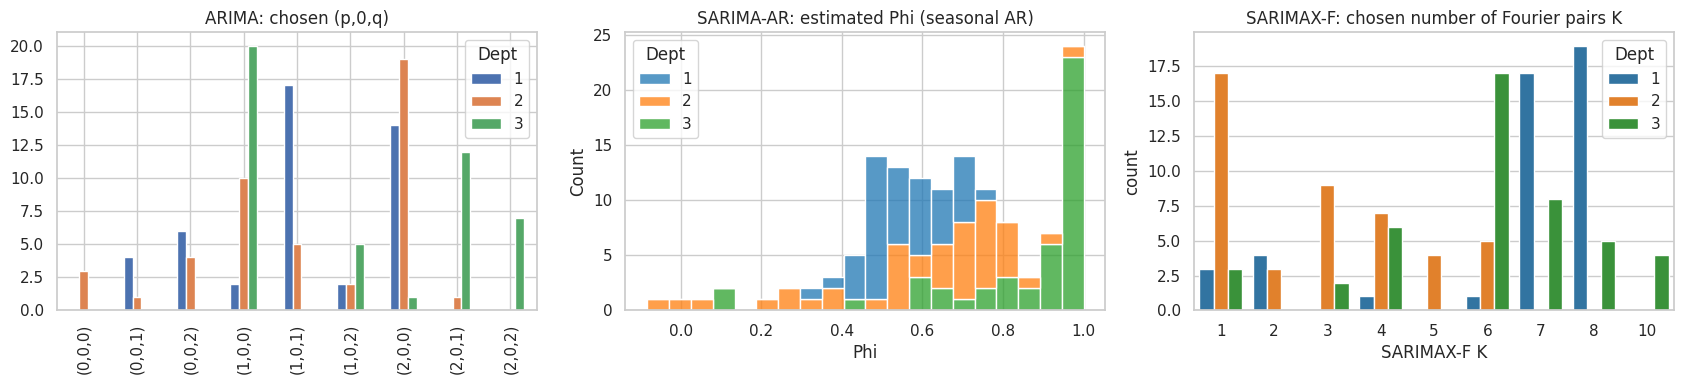

SARIMA-D chosen orders (top 6):
SARIMA-D order
(2,0,0)(0,1,0)52            31
(1,0,0)(0,1,0)52 + drift    19
(2,0,0)(0,1,0)52 + drift    16
(1,0,1)(0,1,0)52            15
(1,0,0)(0,1,0)52            13
(0,0,0)(0,1,0)52 + drift    10


In [36]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

order_counts = model_info.groupby("Dept")["ARIMA order"].value_counts().unstack(fill_value=0)
order_counts.T.plot(kind="bar", ax=axes[0])
axes[0].set_title("ARIMA: chosen (p,0,q)")
axes[0].set_xlabel("")

sns.histplot(data=model_info, x="Phi", hue="Dept", bins=20, multiple="stack", palette="tab10", ax=axes[1])
axes[1].set_title("SARIMA-AR: estimated Phi (seasonal AR)")

sns.countplot(data=model_info, x="SARIMAX-F K", hue="Dept", palette="tab10", ax=axes[2])
axes[2].set_title("SARIMAX-F: chosen number of Fourier pairs K")
plt.tight_layout()
plt.show()

print("SARIMA-D chosen orders (top 6):")
print(model_info["SARIMA-D order"].value_counts().head(6).to_string())

In [37]:
# share of series whose residuals pass the Ljung-Box test (p > 0.05 = no pattern left)
lb_cols = ["LB p ARIMA", "LB p SARIMA-D", "LB p SARIMA-AR", "LB p SARIMAX-D", "LB p SARIMAX-F"]
lb_pass = (model_info[lb_cols] > 0.05).groupby(model_info["Dept"]).mean().T * 100
lb_pass.columns = [f"Dept {d}" for d in lb_pass.columns]
lb_pass["all"] = (model_info[lb_cols] > 0.05).mean() * 100
lb_pass.index = [c.replace("LB p ", "") for c in lb_pass.index]
print("% of series with white-noise residuals (Ljung-Box p > 0.05, lag 10):")
lb_pass.round(0)

% of series with white-noise residuals (Ljung-Box p > 0.05, lag 10):


,Dept 1,Dept 2,Dept 3,all
ARIMA,82.0,91.0,87.0,87.0
SARIMA-D,100.0,100.0,100.0,100.0
SARIMA-AR,29.0,64.0,64.0,53.0
SARIMAX-D,98.0,100.0,96.0,98.0
SARIMAX-F,76.0,27.0,22.0,41.0


In [38]:
failed = [c for c in model_info.columns if c.endswith("failed")]
print("fits that failed and fell back to seasonal naive:", {c: int(model_info[c].fillna(False).sum()) for c in failed} if failed else "none")

# consistency check: the pipeline gives the same Store 1 results as the step-by-step Part 2
check = pd.DataFrame({f"Dept {d}": series_wmae.loc[(FOCUS_STORE, d)] for d in DEPTS}).loc[MODEL_ORDER]
print("largest difference with Part 2 (Store 1):", float((check - store1_wmae[[f'Dept {d}' for d in DEPTS]]).abs().max().max()), "$")

fits that failed and fell back to seasonal naive: none
largest difference with Part 2 (Store 1): 1.1368683772161603e-12 $


**What the models chose**

- **ARIMA:** small orders everywhere: mostly (1,0,1) or (2,0,0) for Dept 1, (2,0,0) or (1,0,0) for Dept 2, (1,0,0) or (2,0,1) for Dept 3. Whatever the order, with $d = 0$ they all end flat at the mean.
- **SARIMA-AR ($\Phi$):** Dept 3 piles up at 1 (22 of 45 stores at 0.95 or more): the data ask for $D = 1$. Dept 1 sits between 0.46 and 0.70 for most stores (median 0.53): the moving holidays drag it down, as in Store 1. Dept 2 is spread from −0.1 to 1 (median 0.68): a weak, noisy yearly pattern.
- **SARIMAX-F ($K$):** Dept 1 needs 7–8 pairs (36 of 45 stores), Dept 2 mostly 1–4 (17 stores at $K = 1$), Dept 3 mostly 6–7. $K$ is a fingerprint of the department's year: many sharp holiday peaks, almost flat, one big peak.
- **SARIMA-D:** (2,0,0) is the most common choice, but **61 of the 135 series (45%) chose a drift**, i.e. a constant yearly growth.

**The drift is the main risk of the copy-based models.** With a drift, the forecast becomes *"last year × the average growth of the last 52 weeks"* for all 39 weeks. If that growth was temporary, the same error is repeated 39 times. Among the SARIMA-D series with a drift, 23% end up more than 20% worse than seasonal naive, versus **none** of the series without a drift, and **all 10 worst SARIMAX-D series have a drift**. Example, Store 35, Dept 3: SARIMA-D (no drift) has a relative WMAE of 0.99, SARIMAX-D (with drift) 2.68, because the drift shrank the whole August peak by about 21%.

**Residual checks vs forecast accuracy**

| Model | % series passing Ljung–Box (p > 0.05) | Rank on mean WMAE (6 statistical models) |
|---|---|---|
| ARIMA | 87% | 6 (worst) |
| SARIMA-D | 100% | 4 |
| SARIMA-AR | 53% | 5 |
| SARIMAX-D | 98% | 3 |
| SARIMAX-F | 41% | 2 (best single model in Dept 1) |
| Combination | (no residuals) | 1 |

**Here, passing the residual test says nothing about forecasting well.** ARIMA passes 87% of the time and is the worst; SARIMAX-F fails 59% of the time and is the best single model. Three reasons: (1) the test looks at lags 1–10, never at lag 52; (2) it checks one-step-ahead errors, not 39-step-ahead ones; (3) the $D = 1$ models are tested on only 52 yearly changes, which are easy to make look random. The failures of SARIMAX-F in Depts 2–3 are still useful: they point at what is missing (the monthly rhythm, 2.6). That's the right use of residual checks: finding **what to add**, not choosing between model families.

**Sanity checks:** no fit failed, and the automated pipeline reproduces the step-by-step Store 1 results to within 10⁻¹² dollars.

## 3.5 Where do the holiday corrections help? Dept 1 around Easter 2012

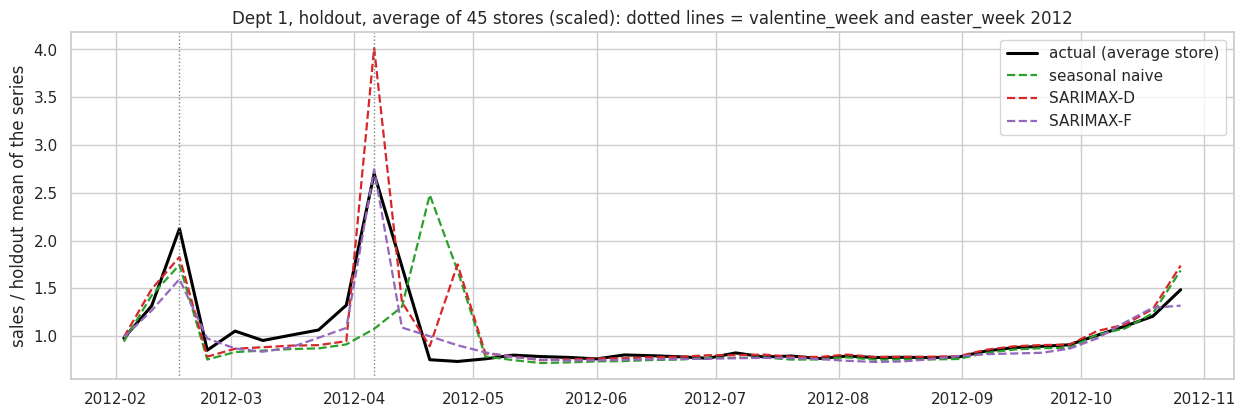

In [39]:
# average over the 45 Dept 1 stores, scaled by each series' holdout mean, for 3 forecasts
d1 = evaluation[(evaluation["Dept"] == 1) & (evaluation["model"].isin(["seasonal naive", "SARIMAX-D", "SARIMAX-F"]))].copy()
scale_by_series = d1.groupby(["Store", "model"])["Weekly_Sales"].transform("mean")
d1["actual (scaled)"] = d1["Weekly_Sales"] / scale_by_series
d1["forecast (scaled)"] = d1["forecast"] / scale_by_series
avg = d1.groupby(["Date", "model"])[["actual (scaled)", "forecast (scaled)"]].mean().reset_index()

plt.figure(figsize=(15, 4.5))
actual_line = avg[avg["model"] == "seasonal naive"]
plt.plot(actual_line["Date"], actual_line["actual (scaled)"], color="black", linewidth=2.2, label="actual (average store)")
for m, color in [("seasonal naive", "tab:green"), ("SARIMAX-D", "tab:red"), ("SARIMAX-F", "tab:purple")]:
    part = avg[avg["model"] == m]
    plt.plot(part["Date"], part["forecast (scaled)"], linestyle="--", color=color, linewidth=1.6, label=m)
for d in week_calendar.loc[(week_calendar["easter_week"] == 1) | (week_calendar["valentine_week"] == 1), "Date"]:
    if split_date < d <= subset["Date"].max():
        plt.axvline(d, color="grey", linestyle=":", linewidth=1)
plt.title("Dept 1, holdout, average of 45 stores (scaled): dotted lines = valentine_week and easter_week 2012")
plt.ylabel("sales / holdout mean of the series")
plt.legend()
plt.show()

**What I see (Dept 1, average of the 45 stores, each series divided by its holdout mean)**

| Week ending | What it is | actual | seasonal naive | SARIMAX-D | SARIMAX-F | Combination |
|---|---|---|---|---|---|---|
| 17 Feb | Valentine's week | **2.12** | 1.75 | 1.83 | 1.60 | 1.71 |
| 30 Mar | week before Easter | **1.32** | 0.91 | 0.95 | 1.09 | 1.02 |
| 6 Apr | Easter week (flagged) | **2.70** | 1.07 | 4.01 | **2.74** | 3.38 |
| 13 Apr | contains Easter Sunday | **1.73** | 1.31 | 1.35 | 1.09 | 1.22 |
| 20 Apr | 52 weeks after the Easter week of 2011 | **0.75** | 2.48 | 0.89 | 1.00 | 0.95 |
| 27 Apr | 52 weeks after the 2nd Easter week of 2011 | **0.73** | 1.69 | 1.75 | 0.90 | 1.33 |

- **Seasonal naive** misses Easter (1.07 vs 2.70) and draws the ghost (2.48 and 1.69 instead of about 0.75): the Store 1 story happens in almost every store.
- **SARIMAX-D** fixes *where* (the peak is in the right week, the 20 April ghost is gone) but not *how much*: 49% too high on average, and the ghost of the second Easter week (27 April) stays.
- **SARIMAX-F** gets the Easter week almost exactly (2.74 vs 2.70) and has no ghost, but it under-forecasts the weeks around it.
- **Easter really spans three weeks:** the build-up (×1.3), the Good-Friday week (×2.7) and the Easter-Sunday week (×1.7). A single dummy can only describe the middle one.
- **Valentine's Day 2012** was stronger than every model expected (2.12 vs 1.60–1.83). It didn't move in 2012 (same week as in 2011), so this is a "how much" error, not a "where" error.

**Ideas to improve (not implemented here):** three Easter dummies (week before, Good-Friday week, week after), or at least a dummy for the week that contains Easter Sunday; and estimate the Easter effect **once per department** from the 45 stores instead of once per series (teammate's Note 7, pooling). Both are also cheap features for the ML models.

# Part 4 — The final forecast for `test.csv`

The holdout told us which approach works best. The usual last step is to **re-fit that approach on all the data we have** (all 143 weeks, train part + holdout) and forecast the real 39 weeks of `test.csv` (2012-11-02 → 2013-07-26). This period contains Halloween, Thanksgiving, Christmas, the Super Bowl and Easter 2013 (29 March, which moved again), so the holiday dummies matter a lot here.

## 4.1 Re-fit the best approach on all 143 weeks

In [40]:
# the best approach on the holdout, among the statistical models (baselines excluded)
statistical = ["ARIMA", "SARIMA-D", "SARIMA-AR", "SARIMAX-D", "SARIMAX-F", "Combination"]
FINAL_MODEL = mean_wmae.loc[statistical, "all 135 series"].idxmin()
needed = {"Combination": ["SARIMAX-D", "SARIMAX-F", "Combination"]}.get(FINAL_MODEL, [FINAL_MODEL])
print("final approach:", FINAL_MODEL, "| models to fit:", needed)

# the 39 weeks of test.csv, with their calendar columns (t, flags) from week_calendar
forecast_set = week_calendar[week_calendar["role"] == "forecast set"].reset_index(drop=True)
print("forecast set:", forecast_set["Date"].min().date(), "->", forecast_set["Date"].max().date(), len(forecast_set), "weeks")
forecast_set.loc[forecast_set[ALL_FLAGS].sum(axis=1) > 0, ["Date"] + ALL_FLAGS]

final approach: Combination | models to fit: ['SARIMAX-D', 'SARIMAX-F', 'Combination']
forecast set: 2012-11-02 -> 2013-07-26 39 weeks


,Date,superbowl,valentine_week,easter_week,labor_day,halloween_week,thanksgiving,christmas_peak,christmas
0,2012-11-02,0,0,0,0,1,0,0,0
3,2012-11-23,0,0,0,0,0,1,0,0
7,2012-12-21,0,0,0,0,0,0,1,0
8,2012-12-28,0,0,0,0,0,0,0,1
14,2013-02-08,1,0,0,0,0,0,0,0
15,2013-02-15,0,1,0,0,0,0,0,0
21,2013-03-29,0,0,1,0,0,0,0,0


In [41]:
FINAL_FILE = RESULTS_DIR + "forecast_set_depts_1_to_3.csv"

if RERUN or not os.path.exists(FINAL_FILE):
    rows = []
    start = time.time()
    all_pairs = subset[["Store", "Dept"]].drop_duplicates().sort_values(["Dept", "Store"]).values
    for i, (store, dept) in enumerate(all_pairs):
        full_history = subset[(subset["Store"] == store) & (subset["Dept"] == dept)].sort_values("Date").reset_index(drop=True)   # all 143 weeks
        forecasts, _ = run_models(full_history, forecast_set, models=needed)
        rows.append(pd.DataFrame({"Store": store, "Dept": dept, "Date": forecast_set["Date"].values,
                                  "Weekly_Sales": forecasts[FINAL_MODEL]}))
        if i % 15 == 0:
            print(f"{i:3d}/135 series done, {time.time() - start:5.0f} s")
    final_forecast = pd.concat(rows, ignore_index=True)
    # Kaggle Id format: Store_Dept_Date (see sampleSubmission.csv)
    final_forecast.insert(0, "Id", final_forecast["Store"].astype(str) + "_" + final_forecast["Dept"].astype(str) + "_"
                          + pd.to_datetime(final_forecast["Date"]).dt.strftime("%Y-%m-%d"))
    final_forecast.to_csv(FINAL_FILE, index=False)
    print(f"done in {time.time() - start:.0f} s")
else:
    final_forecast = pd.read_csv(FINAL_FILE, parse_dates=["Date"])
    print("loaded cached final forecast")

print(final_forecast.shape, "= 135 series x 39 weeks")
final_forecast.head()

loaded cached final forecast
(5265, 5) = 135 series x 39 weeks


,Id,Store,Dept,Date,Weekly_Sales
0,1_1_2012-11-02,1,1,2012-11-02,36734.418470
1,1_1_2012-11-09,1,1,2012-11-09,19873.950214
2,1_1_2012-11-16,1,1,2012-11-16,21359.572048
3,1_1_2012-11-23,1,1,2012-11-23,20643.164441
4,1_1_2012-11-30,1,1,2012-11-30,27287.207853


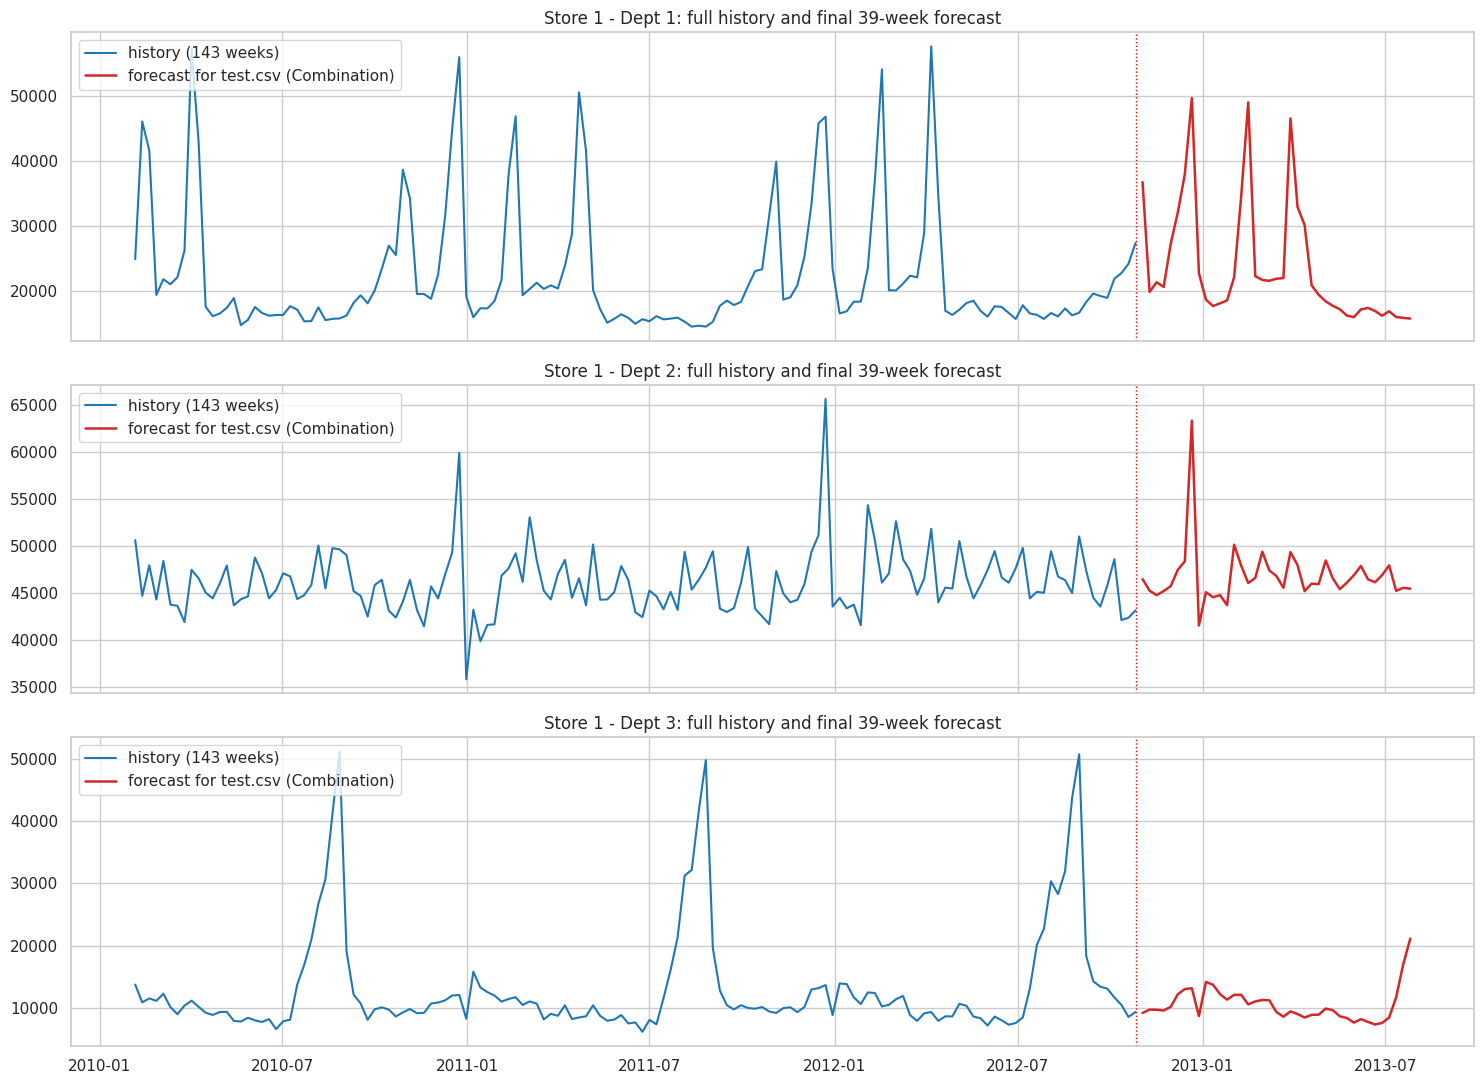

In [42]:
fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)
for ax, dept in zip(axes, DEPTS):
    hist = subset[(subset["Store"] == FOCUS_STORE) & (subset["Dept"] == dept)].sort_values("Date")
    fut = final_forecast[(final_forecast["Store"] == FOCUS_STORE) & (final_forecast["Dept"] == dept)]
    ax.plot(hist["Date"], hist["Weekly_Sales"], color="tab:blue", label="history (143 weeks)")
    ax.plot(fut["Date"], fut["Weekly_Sales"], color="tab:red", linewidth=1.8, label=f"forecast for test.csv ({FINAL_MODEL})")
    ax.axvline(hist["Date"].max(), color="red", linestyle=":", linewidth=1)
    ax.set_title(f"Store {FOCUS_STORE} - Dept {dept}: full history and final 39-week forecast")
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**What I see**

- **Final approach: Combination** (lowest mean WMAE of the statistical models, 2,231). For each series, SARIMAX-D and SARIMAX-F were re-fitted on **all 143 weeks** (2010-02-05 → 2012-10-26) and averaged. All the orders, $K$ values and holiday effects were re-chosen on the longer history with the same rules. Result: **5,265 forecasts** = 135 series × 39 weeks, exactly the Dept 1–3 rows of `test.csv`, with the Kaggle `Id` (`Store_Dept_Date`).
- **Store 1, Dept 1** (top plot): the holidays are where the calendar says they are:
  - Halloween week (2 Nov 2012): 36.7k (2011: 39.9k);
  - week before Christmas (21 Dec): 49.7k (2011: 46.8k);
  - Super Bowl (8 Feb 2013): 34.5k (2012: 37.0k); Valentine's week (15 Feb): 49.0k (2012: 54.1k);
  - **Easter 2013 on 29 March, the new date:** 46.5k, followed by 32.9k and 30.2k. The first of these two weeks is realistic (it contains Easter Sunday, 31 March; the equivalent week made 34.7k in 2012). The second is partly an echo of 2012 (see below).
- **Store 1, Dept 2:** a Christmas peak of 63.3k (2011: 65.6k), otherwise 45–50k with the usual small ups and downs.
- **Store 1, Dept 3:** a quiet winter, then the start of the back-to-school build-up in the last weeks (21.1k on 26 July 2013).
- **Overall level:** the 5,265 forecasts add up to 0.8% less than the same weeks one year earlier: no explosion, no runaway drift.

**One more illustration of how fragile holiday effects are.** Re-fitted on 143 weeks (three Easters instead of two), the SARIMAX-D Easter effect of Store 1, Dept 1 fell from +282% to **+41%**, and across the 45 Dept 1 stores the median went from +247% to +89%. With so few occurrences, one extra Easter changes the estimate a lot. For Store 1 it means SARIMAX-D moves only part of the peak (40.7k on 29 March) and leaves an echo where Easter was in 2012 (41.0k on 5 April). SARIMAX-F gives 52.4k and 24.8k for these two weeks, and the Combination ends at 46.5k and 32.9k.

**What the numbers are:** median forecasts in dollars (section 1.8), for Depts 1–3 only. A full Kaggle submission would also need the other 3,034 series of `test.csv` (same pipeline for the long series, a fallback for the series with little or no history, see the EDA notebook). One series of this file is corrected in 4.2.

## 4.2 Quality check: does any forecast look impossible?

A forecast file with 5,265 numbers can't be checked by eye, line by line. Two quick automatic scans catch the usual problems:

1. **Forecasts above the highest week ever seen for that series.** Not always wrong (a holiday can beat its record), but worth knowing *which weeks* do it.
2. **Isolated spikes in the history.** A copy-based model (SARIMAX-D, so half of the Combination) copies *everything* from 52 weeks earlier, including a data error or a one-off event. Rule used: a week more than **4 ×** the series median **and** more than **3 ×** both of its neighbours, that is **not** one of our holiday weeks. Real seasonal peaks (Easter, back-to-school) build up over several weeks, so they don't match this rule.

In [43]:
# scan 1: forecasts above the series' own historical maximum, and in which week they happen
history_max = subset.groupby(["Store", "Dept"])["Weekly_Sales"].max().rename("history max")
peak_rows = final_forecast.loc[final_forecast.groupby(["Store", "Dept"])["Weekly_Sales"].idxmax()]   # the highest forecast of each series
peak_rows = peak_rows.set_index(["Store", "Dept"]).join(history_max)
peak_rows["forecast / history max"] = peak_rows["Weekly_Sales"] / peak_rows["history max"]
above = peak_rows[peak_rows["forecast / history max"] > 1].sort_values("forecast / history max", ascending=False)

print(f"{len(above)} of 135 series have a forecast above their historical maximum. In which week?")
print(pd.to_datetime(above["Date"]).dt.date.value_counts().to_string())
above[["Date", "Weekly_Sales", "history max", "forecast / history max"]].head(6).round(2)

16 of 135 series have a forecast above their historical maximum. In which week?
Date
2013-03-29    11
2012-12-21     4
2012-11-02     1


,,Date,Weekly_Sales,history max,forecast / history max
Store,Dept,,,,
3,1,2013-03-29,26810.67,18969.05,1.41
27,1,2013-03-29,133512.58,97095.89,1.38
15,1,2013-03-29,64153.49,50479.15,1.27
39,1,2013-03-29,74803.27,65523.35,1.14
12,1,2013-03-29,61897.59,55235.63,1.12
14,1,2013-03-29,175267.97,156677.00,1.12


In [44]:
# scan 2: isolated spikes in the history (candidates for data errors / one-off events)
g = subset.sort_values("Date").groupby(["Store", "Dept"])["Weekly_Sales"]
spike_scan = subset.assign(
    vs_median=subset["Weekly_Sales"] / g.transform("median"),                                  # vs the series' typical week
    vs_neighbours=subset["Weekly_Sales"] / pd.concat([g.shift(1), g.shift(-1)], axis=1).max(axis=1),   # vs the higher neighbour
)
is_flagged_week = subset[ALL_FLAGS].sum(axis=1) > 0
anomalies = spike_scan[(spike_scan["vs_median"] > 4) & (spike_scan["vs_neighbours"] > 3) & ~is_flagged_week]
print(len(anomalies), "isolated spike(s) found in", len(subset), "rows")
anomalies[["Store", "Dept", "Date", "split", "Weekly_Sales", "vs_median", "vs_neighbours"]].round(1)

1 isolated spike(s) found in 19305 rows


,Store,Dept,Date,split,Weekly_Sales,vs_median,vs_neighbours
6114,43,1,2012-03-02,test,70912.0,11.4,10.3


**The fix (only for the series flagged by scan 2):** in a *copy* of the history, replace the spike by the **median of the 2 weeks before and the 2 weeks after** (the series' normal level at that moment), re-fit the same models, and replace the 39 forecasts of that series in the final file. The original data are not modified, and the holdout scores of Part 3 don't change (see the comment below the plot).

series re-fitted (Store, Dept): [(43, 1)] | final file saved: results/forecast_set_depts_1_to_3.csv


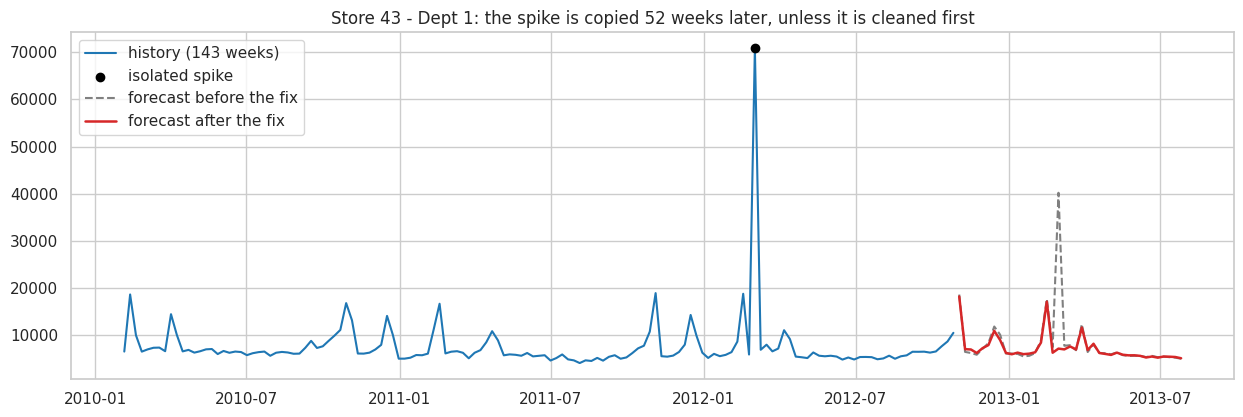

week 2013-03-01: Combination 40,189 -> 7,103 $  (SARIMAX-D 71,304 -> 7,398, SARIMAX-F 9,075 -> 6,808)


In [45]:
def clean_spikes(history, spike_dates):
    # replace each spike week by the median of the 2 weeks before and the 2 weeks after it
    history = history.copy()
    for d in spike_dates:
        i = history.index[history["Date"] == d][0]
        neighbours = [j for j in range(i - 2, i + 3) if j != i and 0 <= j < len(history)]
        history.loc[i, "Weekly_Sales"] = history["Weekly_Sales"].iloc[neighbours].median()
    return history


fixed_series = []
for (store, dept), rows_sd in anomalies.groupby(["Store", "Dept"]):
    full_history = subset[(subset["Store"] == store) & (subset["Dept"] == dept)].sort_values("Date").reset_index(drop=True)
    before, _ = run_models(full_history, forecast_set, models=needed)                                   # as in 4.1
    after, _ = run_models(clean_spikes(full_history, rows_sd["Date"]), forecast_set, models=needed)      # spike replaced
    mask = (final_forecast["Store"] == store) & (final_forecast["Dept"] == dept)
    final_forecast.loc[mask, "Weekly_Sales"] = after[FINAL_MODEL]                                       # same row order (forecast_set dates)
    fixed_series.append((store, dept, full_history, rows_sd["Date"], before, after))

final_forecast.to_csv(FINAL_FILE, index=False)
print("series re-fitted (Store, Dept):", [(int(s), int(d)) for s, d, *_ in fixed_series], "| final file saved:", FINAL_FILE)

for store, dept, full_history, spike_dates, before, after in fixed_series:
    fig, ax = plt.subplots(figsize=(15, 4.5))
    ax.plot(full_history["Date"], full_history["Weekly_Sales"], color="tab:blue", label="history (143 weeks)")
    spike = full_history[full_history["Date"].isin(spike_dates)]
    ax.scatter(spike["Date"], spike["Weekly_Sales"], color="black", zorder=3, label="isolated spike")
    ax.plot(forecast_set["Date"], before[FINAL_MODEL], color="grey", linestyle="--", label="forecast before the fix")
    ax.plot(forecast_set["Date"], after[FINAL_MODEL], color="tab:red", linewidth=1.8, label="forecast after the fix")
    ax.set_title(f"Store {store} - Dept {dept}: the spike is copied 52 weeks later, unless it is cleaned first")
    ax.legend(loc="upper left")
    plt.show()
    k = int(np.argmax(np.abs(before[FINAL_MODEL] - after[FINAL_MODEL])))      # the week that changed the most
    members = ", ".join(f"{m} {before[m][k]:,.0f} -> {after[m][k]:,.0f}" for m in needed if m != FINAL_MODEL)
    print(f"week {forecast_set['Date'].iloc[k].date()}: {FINAL_MODEL} {before[FINAL_MODEL][k]:,.0f} -> {after[FINAL_MODEL][k]:,.0f} $"
          + (f"  ({members})" if members else ""))

**What I see**

**Scan 1: 16 of the 135 series have a forecast above their highest week ever.**
- 11 of them are **Dept 1, in the Easter 2013 week** (29 March), up to 1.41× the historical maximum (Store 3). That's the SARIMAX-D overshoot of section 3.5 again: the Easter multiplier is applied to the same week of 2012 (30 March), which was already the pre-Easter build-up week. These are the stores whose Easter effect stayed large after the re-fit (for example Stores 3, 14, 15, 27: between +165% and +340%).
- 4 are the week before Christmas and 1 is Halloween: plausible, a holiday can beat its record by a few %.
- **Decision:** kept as they are, because that's what the method honestly produces and the Combination already halves the effect. But it's **the main known risk of this file**: in the holdout, the Combination was 25% too high at Easter on average (3.38 vs 2.70 in section 3.5).

**Scan 2: exactly one isolated spike in 19,305 rows.**
- **Store 43, Dept 1, week ending 2 March 2012: 70,912**, which is 11.4× the series' median (6.2k) and 10.3× its higher neighbour. Not a holiday, nothing similar in the other years → most likely a data error or a one-off bulk order.
- **Its effect:** the SARIMAX-D half copied it 52 weeks later. For 1 March 2013: SARIMAX-D 71,304, SARIMAX-F 9,075, so the Combination said **40,189** for a department that sells about 6–8k a week. After cleaning: 7,398 and 6,808 → **7,103**.
- **The holdout scores of Part 3 don't change:** the spike is inside the holdout, i.e. part of the truth we were scored against, not in the 104 training weeks. Every model paid the same unforecastable error on that week.

**Lesson:** *copy-based models copy everything, including errors.* Before handing over a forecast file, always scan it against the history. The same spike would also hurt any ML model that uses a lag-52 feature for this series in 2013.

# Part 5 — Conclusions

## 5.1 The results in one table

All 135 series (Depts 1–3 × 45 stores), fitted on 104 weeks, forecast 39 weeks ahead from one origin (2012-01-27), scored with WMAE on the holdout (Feb → Oct 2012).

| Model | Idea | Mean WMAE | vs seasonal naive | Better than seasonal naive on |
|---|---|---|---|---|
| naive | last week, forever | 5,751 | +102% | 9% of the series |
| mean | an average week | 5,086 | +79% | 13% |
| ARIMA | short-term memory | 4,773 | +68% | 10% |
| **seasonal naive** | same week last year | **2,847** | — | — |
| SARIMA-AR | shrunk copy of last year | 2,833 | −0.5% | 56% |
| SARIMA-D | last year + a correction that fades | 2,805 | −1.5% | 53% |
| SARIMAX-D | copy + moving holidays | 2,615 | −8% | 68% |
| SARIMAX-F | smooth curve + holiday dummies + ARMA | 2,572 | −10% | 51% |
| **Combination** | average of SARIMAX-D and SARIMAX-F | **2,231** | **−22%** | **81%** |

**The story in four sentences**
1. The yearly pattern is everything: the models without it (naive, mean, ARIMA) are 70–100% worse than "same week last year".
2. With two years of data, a pure SARIMA can't learn much more than "copy last year" (−1%).
3. The real gains come from **calendar knowledge**: moving the holidays (SARIMAX-D, −8%) or describing the year as a smooth curve plus holiday spikes (SARIMAX-F, −10% overall and −40% in Dept 1).
4. Averaging two models that see the data differently gives the best result (−22%), and it beats seasonal naive on 4 series out of 5.

## 5.2 What this notebook teaches: theory ↔ what we saw

| # | Theory | What we saw |
|---|---|---|
| 1 | ARMA memory fades like $\phi^h$, so an ARIMA with $d = 0$ forecasts the mean after a few steps (1.4). | ARIMA forecasts were flat after 2–3 weeks and about as good as the mean baseline (2.2). For a 39-week horizon, short-term memory is worth almost nothing. |
| 2 | Seasonal naive = SARIMA(0,0,0)(0,1,0)₅₂ (1.5). | It's a strong baseline. SARIMA-D and SARIMA-AR beat it by only about 1%: they are seasonal naive plus a correction that fades (2.3, 2.4). |
| 3 | The data budget: with 104 weeks, $P$ and $Q$ can't be identified together with $D = 1$ (1.5). | The only seasonal options were $D = 1$ or $P = 1$. $\Phi \approx 1$ in Dept 3 confirmed $D = 1$ (2.4, 3.4). |
| 4 | SARIMAX adds information known in advance (1.6, Note 5). | Calendar information gave the biggest gains. Easter alone is a +90% to +280% effect in Dept 1, depending on the model and the data. |
| 5 | Seasonal differencing erases regressors that repeat every year (1.6). | Only the 3 moving holidays could enter SARIMAX-D. SARIMAX-F (no differencing) used all 8 flags and all 104 weeks. |
| 6 | Fourier terms describe a smooth typical year with few parameters (1.6). | Great for the holiday-driven Dept 1 ($K$ = 7–8), blind to Dept 2's monthly rhythm, too soft for Dept 3's sharp peak (2.6). |
| 7 | AICc only compares models fitted on the same data (1.7). | AICc chose orders and $K$ inside each family, on the train part only; the families were compared once, on the holdout. |
| 8 | Residual checks test one-step-ahead errors at short lags (1.7). | Passing Ljung–Box said nothing about 39-week accuracy: ARIMA 87% pass and worst, SARIMAX-F 41% pass and best single model (3.4). |
| 9 | The absolute error is convex: the error of an average ≤ the average of the errors. | The Combination was never worse than the average of its members, better than both in 42% of the series, and the best overall (3.3). |
| 10 | $e^{\hat y}$ is the median forecast, the right point forecast for an absolute-error metric (1.8). | All forecasts are back-transformed with $e^{\hat y}$, without bias correction. |

**And three practical lessons**
- **Holiday effects estimated from 1–3 occurrences are fragile:** the Easter effect of Store 1, Dept 1 was +282% on 104 weeks and +41% on 143 weeks (Part 4).
- **A drift is a strong assumption** for a 39-week horizon: it was behind all 10 worst SARIMAX-D forecasts (3.4).
- **Check the final file, not only the scores:** one data error was copied straight into the 2013 forecast (4.2).

## 5.3 Limitations, and how they could be addressed

| Limitation | Consequence | What could be done |
|---|---|---|
| **One forecast origin** (2012-01-27) | the ranking rests on a single 39-week period with its own accidents (Easter in early April, a back-to-school peak one week late) | **rolling origins**: repeat the evaluation from several origins (e.g. every 4 weeks) and average. It costs compute, not new ideas |
| **Two years of history** | every holiday effect is learned from 1–3 occurrences and is unstable (5.2) | **pool** each holiday effect across the 45 stores of a department (Note 7), or shrink each store's effect towards the department's |
| **The holdout is not the forecast period** | the holdout (Feb–Oct) has only 2 weight-5 weeks (Super Bowl, Labor Day), while `test.csv` has Thanksgiving and Christmas, where the metric is decided (EDA G.7) | add an origin in autumn 2011 (fit up to Oct 2011, forecast Nov 2011 → Jan 2012) to test the end-of-year season |
| **Easter = one dummy** | the effect spans three weeks: overshoot and echo (3.5, Part 4) | three Easter dummies (week before, Good-Friday week, week after) |
| **Drift** | a temporary growth is extended over 39 weeks (3.4) | no drift, or only when clearly significant, or a damped drift |
| **Peaks that slide by a week** (Dept 3 in 2012) | a one-week shift of a 5× peak; no calendar flag explains it | a school-calendar variable (not in the data); the smooth SARIMAX-F half already limits the damage |
| **Monthly rhythm** (Dept 2) | missed by SARIMAX-F; residuals not white noise (2.6) | a "week contains the 1st of the month" dummy, or Fourier terms with a monthly period |
| **Depts 1–3 only** | 135 of 3,331 series, 7.1% of sales: other departments may behave differently | `run_models` works for any complete series with 2+ years; short or new series need a fallback |
| **No economic variables** | temperature, fuel price, CPI, unemployment and markdowns are not used | by design: they are not known 39 weeks ahead (Note 5), and the EDA showed that their effect is mostly the season itself |

## 5.4 Link with the other parts of the project

**Files handed over** (folder `results/`):

| File | Content | How the team can use it |
|---|---|---|
| `holdout_forecasts.csv` | 47,385 rows = 135 series × 39 holdout weeks × 9 models | **common benchmark**: score the ML / DL models on the same weeks with the same WMAE. The bars to beat: 2,847 (seasonal naive) and 2,231 (Combination) |
| `holdout_model_info.csv` | one row per series: chosen orders, $\Phi$, $K$, Easter effect, Ljung–Box p-values | to understand *why* a series is hard |
| `forecast_set_depts_1_to_3.csv` | 5,265 rows: `Id, Store, Dept, Date, Weekly_Sales` | the statistical forecast for `test.csv`; one candidate for a cross-team combination |

**What the statistical part suggests for the ML / DL feature engineering**
- **Sales 52 weeks earlier** (the seasonal naive) is the most useful single predictor, and it is **known at the forecast origin for all 39 horizons** (52 > 39). Lags 1 to 38 are not available for every horizon: using them would leak the future (Note 5), unless the ML model forecasts recursively.
- **Calendar flags:** the moving holidays (`valentine_week`, `easter_week`, `halloween_week`), the real Christmas peak (`christmas_peak`, rather than the official Christmas flag), plus an **Easter-Sunday week** flag (3.5).
- **"Last year's week was a holiday" flags**, i.e. the $x_t - x_{t-52}$ of SARIMAX-D: they tell a model when the lag-52 value is *not* a normal week.
- **Fourier terms** ($K \approx 6$–8, period 52.18 weeks): a smooth seasonal shape that tree-based models can't build on their own.
- **Week of the month** (Dept 2's rhythm, 2.6).
- **The statistical forecasts themselves as a feature** (stacking), which is the "ARIMA as feature engineering" idea. It is only valid if they are true out-of-sample forecasts made from the same origin as the ML target, like `holdout_forecasts.csv`. In-sample fitted values would leak.

**For the frontier and competition parts:** same split, same metric and the same relative WMAE vs seasonal naive, so that every part of the report fits in one comparison table.

## 5.5 Cheat sheet

**Models** ($y_t$ = log weekly sales, $s = 52$)

| Model | Equation | statsmodels | The 39-week forecast looks like |
|---|---|---|---|
| AR(p) | $y_t = c + \phi_1 y_{t-1} + \dots + \phi_p y_{t-p} + \varepsilon_t$ | `SARIMAX(y, order=(p,0,0), trend="c")` | slides back to the mean |
| MA(q) | $y_t = \mu + \varepsilon_t + \theta_1 \varepsilon_{t-1} + \dots + \theta_q \varepsilon_{t-q}$ | `order=(0,0,q)` | the mean after $q$ weeks |
| ARIMA(p,d,q) | $\phi(B)(1-B)^d y_t = c + \theta(B)\varepsilon_t$ | `order=(p,d,q)` | flat: the mean ($d = 0$) or the last level ($d = 1$) |
| seasonal naive | $y_t = y_{t-52} + \varepsilon_t$ | `seasonal_order=(0,1,0,52)` | last year |
| SARIMA-D | $w_t = y_t - y_{t-52}$ follows an ARMA(p,q) | ARMA on $w$, then add last year back | last year + a correction that fades |
| SARIMA-AR | $y_t - \bar y = \Phi\,(y_{t-52} - \bar y) + \dots$ | `seasonal_order=(1,0,0,52)` on $y - \bar y$, approximate diffuse start | last year, shrunk towards the mean |
| SARIMAX-D | $w_t = \beta\,(x_t - x_{t-52}) + \eta_t$, $\eta_t$ ARMA | `SARIMAX(w, exog=dx, order=(p,0,q))` | last year with the moving holidays moved |
| SARIMAX-F | $y_t = \beta_0 + \text{Fourier}_K + \beta' x_t + \eta_t$, $\eta_t$ ARMA | `SARIMAX(y, exog=[Fourier, dummies], order=(p,0,q), trend="c")` | a smooth typical year + holiday spikes |
| Combination | $(\hat y^{D} + \hat y^{F}) / 2$ in dollars | plain average | in between, never worse than the average of the two |

**Reading rules**

| Situation | Rule |
|---|---|
| ACF decays, PACF cuts off after lag $p$ | AR($p$) |
| ACF cuts off after lag $q$, PACF decays | MA($q$) |
| ACF decays very slowly, or stays high at lags 52, 104 | difference ($d = 1$ or $D = 1$) |
| choosing orders | lowest AICc; a difference below 2 = no real difference; only between models fitted on the same data |
| Ljung–Box p > 0.05 | no pattern left at short lags: necessary, not sufficient |
| dummy coefficient $\beta$ on log sales | effect $= e^{\beta} - 1$ (in %) |
| back to dollars | $e^{\hat y}$ = median forecast, the right choice for WMAE |
| relative WMAE < 1 | better than "same week last year" |

**Self-check questions** (click a question to see the answer)

<details>
<summary>1. Why is the ARIMA forecast flat after a few weeks?</summary>

With $d = 0$ the ARMA is stationary: the influence of the last observed weeks fades like $\phi^h$, so far ahead the best guess is the long-run mean $c/(1-\phi)$.
</details>

<details>
<summary>2. Why can't we estimate a seasonal AR or MA term together with seasonal differencing here?</summary>

After $D = 1$ only 52 yearly changes are left. A seasonal AR term would need pairs (yearly change, yearly change 52 weeks earlier), and there are none in 104 weeks.
</details>

<details>
<summary>3. Why do the Labor Day and Thanksgiving dummies disappear from SARIMAX-D, but not Easter?</summary>

On the differenced scale the regressor becomes $x_t - x_{t-52}$. A holiday that falls in the same week every year gives 0 everywhere; a moving holiday gives +1 and −1.
</details>

<details>
<summary>4. Why can the Combination never be worse than the average of its two members?</summary>

For every week, $|y - (a+b)/2| \le (|y-a| + |y-b|)/2$ (triangle inequality), so the WMAE of the average is at most the average of the two WMAEs.
</details>

<details>
<summary>5. Why convert forecasts back with exp(ŷ) rather than with the bias-corrected exp(ŷ + σ²/2)?</summary>

$e^{\hat y}$ is the median of the forecast distribution, and the median minimises the expected absolute error (WMAE). The bias-corrected mean is only better for squared errors (RMSE).
</details>

<details>
<summary>6. A model passes the Ljung–Box test. Is it a good 39-week forecaster?</summary>

Not necessarily: the test only looks at one-step-ahead errors at short lags. ARIMA passed for 87% of the series and was the worst statistical model.
</details>